*[notebook only]*

# Block detection pipeline: LEVEL 0 notebook

**LVL0 → LVL1 → LVL2.** Response-style QC and drift modelling. Run this notebook first; its stamped output is the input of the LVL1 notebook.

- **Conditions and cohorts:** the manuscript calls the two conditions cohorts: T2 = Cohort A (CA), T3 = Cohort B (CB). The code, file names, exports and the final report keep T2 and T3; only `make_replication_figures.ipynb` prints CA and CB.
- **Input:** the raw long-format file `INPUT_LONG_PATH` (set in `[cell 2]`).
- **Output:** the stamped handoff `lv0_out_<ts>.csv` and its run log `lv0_out_<ts>_parameters.json` (the LVL_0 configuration and results), both in `LVL_OUTS` (`[cell 2]`). Pin the handoff in the LVL1 notebook (`LVL0_HANDOFF`).
- **Exports for the reports** (notebook only, after `[cell 7]`): the group-level decay fits `lv0_out_<ts>_decay_fits.csv` (model selection per span; the selected model per transform, span and scale) and the medians and fitted curves `lv0_out_<ts>_decay_curves.csv`, read by `LVL0_report.ipynb` and `make_replication_figures.ipynb`.
- Every code cell starts with a label. A `# [cell N]` cell is a pipeline cell: N is its pipeline-wide number, also its `NOTEBOOK CELL n` banner in `lvl0.py` / `lvl2.py`, which `build_level_scripts.py` builds from all three notebooks. A `# [notebook only]` cell is never copied into a script.
- `[cell 0]`–`[cell 2]` are shared with the LVL1 / LVL2 notebooks. The build stops if the copies differ; edit all three.

In [1]:
# [notebook only] LVL_0 RUN ENVIRONMENT: INTERPRETER AND PACKAGE VERSIONS
# =============================================================================
# Interpreter and package versions of this run.
import sys as _vsys, platform as _vplatform
from importlib import metadata as _vmeta


def _pkg_version(p):
    try:
        return _vmeta.version(p)
    except _vmeta.PackageNotFoundError:
        return "not installed"


print(f"interpreter: {_vsys.executable} (Python {_vplatform.python_version()})")
print("packages: " + ", ".join(f"{p} {_pkg_version(p)}" for p in (
    "numpy", "pandas", "scipy", "scikit-learn", "statsmodels", "hmmlearn", "ruptures", "joblib", "matplotlib")))

interpreter: /usr/bin/python3 (Python 3.10.12)
packages: numpy 1.26.4, pandas 2.2.1, scipy 1.12.0, scikit-learn 1.7.2, statsmodels 0.14.6, hmmlearn 0.3.3, ruptures 1.1.10, joblib 1.5.3, matplotlib 3.10.8


In [2]:
# [cell 0]
# =============================================================================
# SET BLAS/LAPACK THREAD LIMITS
# =============================================================================
# CRITICAL: These env vars MUST be set BEFORE importing numpy/scipy.
# They control multi-threaded BLAS (OpenBLAS, Intel MKL, etc.) so that
# joblib parallelism doesn't oversubscribe each worker with BLAS threads.
# Setting to '1' means joblib controls ALL parallelization via n_jobs.
# =============================================================================

import os
import multiprocessing as mp

os.environ['OMP_NUM_THREADS'] = '1'
os.environ['MKL_NUM_THREADS'] = '1'
os.environ['OPENBLAS_NUM_THREADS'] = '1'
os.environ['NUMEXPR_NUM_THREADS'] = '1'
os.environ['VECLIB_MAXIMUM_THREADS'] = '1'

# joblib controls all parallelism via n_jobs
n_jobs = 31

print(f"Available CPU cores: {mp.cpu_count()}")
print(f"CPU cores to use: {n_jobs}")

Available CPU cores: 32
CPU cores to use: 31


In [3]:
# [cell 1]
# =============================================================================
# IMPORTS, WARNING CONTROL
# =============================================================================

# -----------------------------
# Standard library
# -----------------------------
from datetime import datetime
import hashlib
import json
import logging
from pathlib import Path
from typing import Dict, List, Optional, Tuple, Union
import warnings

# -----------------------------
# Third-party
# -----------------------------
from joblib import Parallel, delayed

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import scipy.stats as stats
from scipy.optimize import curve_fit
import scipy.sparse as sp_sparse
from scipy.sparse.linalg import splu as sp_splu

from hmmlearn import hmm

import ruptures as rpt


from sklearn.cluster import KMeans
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.preprocessing import StandardScaler

from statsmodels.stats.multitest import fdrcorrection

# -----------------------------
# Warnings (logged to WARNINGS_OUTS/suppressed_warnings.log, set up in [cell 2])
# -----------------------------
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning)
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("default", category=ConvergenceWarning)

warnings.filterwarnings("default", message=".*convergence.*", category=UserWarning)
warnings.filterwarnings("default", message=".*did not converge.*", category=UserWarning)
warnings.filterwarnings("default", message=".*singular.*", category=UserWarning)
warnings.filterwarnings("default", message=".*Hessian.*", category=UserWarning)
warnings.filterwarnings("default", message=".*MLE.*boundary.*", category=UserWarning)

warnings.filterwarnings("ignore", message=".*KMeans.*", category=UserWarning)
warnings.filterwarnings("ignore", message=".*Fitting.*", category=UserWarning)

In [4]:
# [cell 2]
# =============================================================================
# SET DIRECTORIES
# =============================================================================
# Everything the pipeline reads and writes is inside /home/sjsuss626/EMST_files/sjs_dissertation:
#   INPUT_LONG_PATH  the raw long-format data, read by LVL_0
#   LVL_OUTS         every output: handoffs, run logs, exports, the warnings log
#   FIG_DIR          figures, written only when the level's save_figures is True
#   CODE_DIR         this folder (the LVL2 notebook loads LVL0 / LVL1 cells from it)
INPUT_LONG_PATH = Path("/home/sjsuss626/EMST_files/sjs_dissertation/dset/all_subjects_long.csv")
LVL_OUTS        = Path("/home/sjsuss626/EMST_files/sjs_dissertation/dervatives/dynamic_qc/lvl_outs")
WARNINGS_OUTS   = Path("/home/sjsuss626/EMST_files/sjs_dissertation/dervatives/dynamic_qc/lvl_outs/warnings")
FIG_DIR         = Path("/home/sjsuss626/EMST_files/sjs_dissertation/dervatives/dynamic_qc/figures")
CODE_DIR        = Path("/home/sjsuss626/EMST_files/sjs_dissertation/code/cpd_and_blk_rep_anaylsis")
print("input  :", INPUT_LONG_PATH)
print("outputs:", LVL_OUTS)

# Warnings go to a file so they aren't silently lost.
LVL_OUTS.mkdir(parents=True, exist_ok=True)
WARNINGS_OUTS.mkdir(parents=True, exist_ok=True)
logging.basicConfig(
    filename=str(WARNINGS_OUTS / "suppressed_warnings.log"),
    filemode="w",  # overwrite each run
    level=logging.DEBUG,
    format="%(asctime)s | %(levelname)s | %(message)s",
)
logging.captureWarnings(True)

# =============================================================================
# PIPELINE VERSION AND SOFTWARE (recorded in every run log)
# =============================================================================
# Development series 0.0.x (1.0.1 will be the general tool). The same literal stands in the three level notebooks'
# [cell 2] (identical copies) and in Replication_and_final_report [cell 1]; the report's [cell 3] checks it against
# the run logs.
PIPELINE_VERSION = "0.0.1"
SOFTWARE_PACKAGES = ("numpy", "pandas", "scipy", "scikit-learn", "statsmodels", "hmmlearn", "ruptures", "joblib",
                     "matplotlib")


def software_versions():
    """Interpreter and package versions of this process: the "software" entry of every run log."""
    import platform as _platform
    import sys as _sys
    from importlib import metadata as _meta
    out = {"executable": _sys.executable, "python": _platform.python_version()}
    for p in SOFTWARE_PACKAGES:
        try:
            out[p] = _meta.version(p)
        except _meta.PackageNotFoundError:
            out[p] = None
    return out


# =============================================================================
# FIGURE SAVING + PER-LEVEL PARAMETER/RESULTS JSON
# =============================================================================
# Run logs sit in LVL_OUTS beside the outputs they describe. Figures are written only
# when the level's config sets save_figures (SAVE_FIGURES is set in each config cell).
RUN_LOG_DIR = LVL_OUTS
FIG_DIR.mkdir(parents=True, exist_ok=True)

FIG_PREFIX = "LVL"
SAVE_FIGURES = False
_FIG_SAVE_STATE = {"n": 0}

# Re-running this cell must not wrap our own wrapper. _ORIG_PLT_SHOW is a
# notebook GLOBAL and cell-level functions resolve globals at CALL time, so a
# second execution rebinds it to show_and_save itself -- the wrapper then calls
# itself forever (RecursionError inside plt.show()).
# Only ever cache a show() that genuinely comes from matplotlib.pyplot, and
# re-derive it if a previous run cached a wrapper.
def _is_real_show(fn):
    return getattr(fn, "__module__", "") == "matplotlib.pyplot"


if not _is_real_show(getattr(plt, "_orig_show_unpatched", None)):
    if _is_real_show(plt.show):
        plt._orig_show_unpatched = plt.show
    else:
        import importlib
        plt._orig_show_unpatched = importlib.reload(
            importlib.import_module("matplotlib.pyplot")).show
_ORIG_PLT_SHOW = plt._orig_show_unpatched

# Re-entrancy guard: even if some other wrapper is still installed from an
# earlier kernel state, this terminates instead of recursing.
_IN_SHOW = {"active": False}


def show_and_save(*args, **kwargs):
    if _IN_SHOW["active"]:
        return None
    _IN_SHOW["active"] = True
    try:
        return _show_and_save_inner(*args, **kwargs)
    finally:
        _IN_SHOW["active"] = False


def _show_and_save_inner(*args, **kwargs):
    for _num in (plt.get_fignums() if SAVE_FIGURES else []):
        _fig = plt.figure(_num)
        if getattr(_fig, "_saved_by_show", False):
            continue
        _FIG_SAVE_STATE["n"] += 1
        _fig.savefig(
            FIG_DIR / f"{FIG_PREFIX}_fig{_FIG_SAVE_STATE['n']:03d}.png",
            dpi=150, bbox_inches="tight",
        )
        _fig._saved_by_show = True
    return _ORIG_PLT_SHOW(*args, **kwargs)


plt.show = show_and_save


def _jsonable(obj):
    if isinstance(obj, pd.DataFrame):
        return obj.astype(object).where(pd.notna(obj), None).to_dict(orient="records")
    if isinstance(obj, pd.Series):
        return obj.astype(object).where(pd.notna(obj), None).to_dict()
    if isinstance(obj, dict):
        return {str(k): _jsonable(v) for k, v in obj.items()}
    if isinstance(obj, (list, tuple, set)):
        return [_jsonable(v) for v in obj]
    if isinstance(obj, np.integer):
        return int(obj)
    if isinstance(obj, np.floating):
        return None if np.isnan(obj) else float(obj)
    if isinstance(obj, np.bool_):
        return bool(obj)
    return obj


def file_sha256(path, chunk=1 << 20):
    """SHA-256 of a file's bytes: the content identity of the raw input, recorded by LVL_0 and checked downstream."""
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for b in iter(lambda: f.read(chunk), b""):
            h.update(b)
    return h.hexdigest()


def dump_level_json(level, config, results=None, extra=None, name=None):
    """Write the level's run log: <name>_parameters.json, where name is the stem of the
    output it describes (e.g. lv0_out_<ts>), or <level>_parameters_<ts>.json without one."""
    ts = datetime.now().strftime("%Y%m%d_%H%M%S")
    path = RUN_LOG_DIR / (f"{name}_parameters.json" if name else f"{level}_parameters_{ts}.json")
    payload = {
        "level": level,
        "pipeline_version": PIPELINE_VERSION,
        "software": software_versions(),
        "timestamp": ts,
        "input_long_path": str(INPUT_LONG_PATH),
        "figures_dir": str(FIG_DIR),
        "figures_saved": int(_FIG_SAVE_STATE["n"]),
        "parameters": _jsonable(config),
        "statistical_results": _jsonable(results or {}),
        "outputs": _jsonable(extra or {}),
    }
    with open(path, "w") as f:
        json.dump(payload, f, indent=2, default=str)
    print(f"  {level} parameter/results JSON -> {path}")
    return path

input  : /home/sjsuss626/EMST_files/sjs_dissertation/dset/all_subjects_long.csv
outputs: /home/sjsuss626/EMST_files/sjs_dissertation/dervatives/dynamic_qc/lvl_outs


In [5]:
# [cell 3]
# =============================================================================
# DATA IMPORT AND GLOBAL PARAMETERS
# =============================================================================

FIG_PREFIX = "LVL0"

# -----------------------------------------------------------------------------
# Load Data
# -----------------------------------------------------------------------------
# Single source of truth for the raw input file. Every downstream stage, the
# Step 12 export included, reads INPUT_LONG_PATH rather than naming a file of its own.
all_data = pd.read_csv(INPUT_LONG_PATH)
print(all_data.head())

# =============================================================================
# CONFIGURATION (BASE)
# =============================================================================

LVL_0_CONFIG = {

    "save_figures": False,            # bool: write figures to FIG_DIR ([cell 2]); the run log is always written

    # --------------------------------------------------------------------------
    # Experiment structure
    # --------------------------------------------------------------------------
    "sessions": [1, 2],               # Session numbers
    "conditions": ["T2", "T3"],       # Condition intake filter; e.g. ["T2"] runs LVL_0 on T2 only
    "max_age": 30,                    # Age intake filter (years): participants older than max_age are excluded
    # also set at LVL_1
    "pr_stim_drop": 3,                # Practice stimulus (number of stimuli that we define as practice) to drop at session start

    # --------------------------------------------------------------------------
    # Reaction-time filtering
    # --------------------------------------------------------------------------
    # also set at LVL_1
    "max_rt_thresh": 90,              # Maximum acceptable RT (seconds; default is 90); 0 = off
    # also set at LVL_1
    "min_rt_thresh": 0.15,           # Minimum acceptable RT (seconds); same 150 ms floor as inattent_behav_fast_rt_thresh; 0 = off

    # --------------------------------------------------------------------------
    # Response-pattern diagnostics
    # --------------------------------------------------------------------------
    # [cell 5] builds a per-participant-session PERMUTATION null for straight-lining,
    # the periodic patterns (p = 2, 3, 4) and the 5-response stimulus-linked pattern,
    # and shows their 95th / 99th percentiles (figures and a marker table, overall and
    # per condition). LVL_0 flags no trials: the careless-responding heuristic is set in
    # LVL_2_CONFIG ("inattent_behav_*"), from the T2 columns of the marker table.
    "periodic_n_perms": 1000,         # permutations per participant-session, for every null (~30s for all three)

    # --------------------------------------------------------------------------
    # Diagnostic plots
    # --------------------------------------------------------------------------
    "sub_n_plots": 25,               # Number of participants to show in diagnostic plots
    "vis_drift_residuals": ["raw","log","boxcox"],           # list of RT types to fit, residualize and visualize
    "vis_hist_scales": "all",                # "all" = all scales from scale_ranges; or list e.g. ["valence","arousal"]

    # --------------------------------------------------------------------------
    # RT transformation
    # --------------------------------------------------------------------------
    # Which representation is "primary" is NOT decided here: LVL_0 fits and
    # residualises all of vis_drift_residuals and writes one tagged column set per
    # representation. LVL_1 selects with "feature_rt_transform"; LVL_2 with
    # "feature_rt_transform" as well.
    "joint_scale_fit": False,        # Applies to Overall fit only. False = fit each scale independently; True = shared dynamics + per-scale offsets

    # --------------------------------------------------------------------------
    # Drift model
    # --------------------------------------------------------------------------
    # Drift Model Selection
    #   Model options: "exp_w_linfag" | "exp" | "log" | "log_w_linfag" | "linear" | "auto"
    #   - exp_w_linfag: Exponential decay + linear fatigue (default)
    #   - exp: Simple exponential decay
    #   - log: Logarithmic decay
    #   - linear: Linear decay
    "ses_drift_model_overall": "auto",                # model for concatenated overall fit; "auto" = best R²
    "ses_drift_model_per_ses": ["auto", "auto"],    # model per session (ordered by "sessions"); "auto" = best R²
    # also set at LVL_1, LVL_2
    "ses_wise_drift": False,        # bool: True = per-session drift | False = overall drift

    # --------------------------------------------------------------------------
    # Age adjustment of drift residuals
    # --------------------------------------------------------------------------
    # When True, removes the linear age trend from drift residuals within each
    # scale (drift_residual_<tag>_overall → drift_residual_<tag>_overall_age,
    # drift_residual_<tag>_per_ses → drift_residual_<tag>_per_ses_age).
    # also set at LVL_1
    "age_adjust_drift_residuals": True,  # bool: regress out linear age effect
}

# -----------------------------------------------------------------------------
# Apply the intake filters: age, then sessions and conditions
# -----------------------------------------------------------------------------
_raw_n, _raw_ids = len(all_data), all_data["id"].nunique()
all_data = all_data[all_data["age"] <= LVL_0_CONFIG["max_age"]]
print(f"Age filter (age <= {LVL_0_CONFIG['max_age']}): kept {all_data['id'].nunique()}/{_raw_ids} participants, "
      f"{len(all_data):,}/{_raw_n:,} rows")
_requested_sessions = LVL_0_CONFIG["sessions"]
_pre_n = len(all_data)
all_data = all_data[all_data["session"].isin(_requested_sessions)].reset_index(drop=True)
all_data = all_data[all_data["condition"].isin(LVL_0_CONFIG["conditions"])].reset_index(drop=True)
_actual_sessions = sorted(all_data["session"].dropna().unique().tolist())
print(f"Sessions / conditions filter: kept {len(all_data):,}/{_pre_n:,} rows  "
      f"(sessions={_actual_sessions}, conditions={sorted(all_data['condition'].dropna().unique().tolist())})")

SAVE_FIGURES = LVL_0_CONFIG["save_figures"]

     id  age   sex gender condition  session       scale  stim_order  \
0  1008   28  male   male        T2        1     valence           1   
1  1008   28  male   male        T2        1     arousal           1   
2  1008   28  male   male        T2        1     emotion           1   
3  1008   28  male   male        T2        1  similarity           1   
4  1008   28  male   male        T2        1      threat           1   

   resp_order  stim_label      trial_label  response  rt_sec  S1_S2_mins  \
0           1       21023     valence21023         1  3.8932      9955.0   
1           2       21023     arousal21023         7  4.1695      9955.0   
2           3       21023     emotion21023         1  6.0556      9955.0   
3           4       21023  similarity21023         1  4.8707      9955.0   
4           5       21023      threat21023         1  2.1016      9955.0   

   S1_S2_hours  same_day  anx_raw  anx_t  dep_raw  dep_t  
0   165.916667       0.0     25.0   63.5     19.0  

*[cell 4]*

# LEVEL 0: Descriptive Statistics & Drift Modelling

## Input Data Structure
Long-format DataFrame read from `INPUT_LONG_PATH`.

**Required**
- **id** — participant ID
- **age** — participant age in years (age filter + age-adjustment regression)
- **session** — session number, gated by `LVL_0_CONFIG["sessions"]`
- **stim_order** — trial index within scale (1..N per scale per session)
- **resp_order** — trial index across all responses; primary trial axis for the QC detectors
- **scale** — scale name (`valence`, `arousal`, `emotion`, `similarity`, `threat`)
- **response** — rating response (scale-dependent range)
- **rt_sec** — reaction time in seconds

**Optional** (guarded by `if <col> in df.columns:` everywhere)
- **condition** — `T2` / `T3`; when present, IRR / reliability / deviation analyses run per condition. These are different participants rating different stimuli, not within-subject timepoints.
- **stim_label** — stimulus identifier used for IRR / consensus / deviation grouping; falls back to `stim_order`.

## Outputs
- Tagged drift residuals `drift_residual_{raw|log|bc}_{overall|per_ses}[_age]` and `predicted_rt_{tag}_{base}` — LVL_0 picks no primary representation; LVL_1 selects one with `feature_rt_transform` (plus `ses_wise_drift` and `age_adjust_drift_residuals`) and hands it to LVL_2 as `rt_input`; LVL_2 has no RT-representation knob.
- In `LVL_OUTS` (`[cell 2]`): the timestamped LVL_0 handoff `lv0_out_<ts>.csv` (the input of the LVL1 notebook and of `lvl1.py --lvl0-input`) and its run log `lv0_out_<ts>_parameters.json` (configuration, resolved drift models, fitted drift parameters, age adjustment). Figures go to `FIG_DIR` only when `save_figures` is True.


RT THRESHOLD ANALYSIS

RT THRESHOLD ANALYSIS (Empirical Percentiles)
Total trials: 552,281
RT range: 0.000s - 776.0s
Median RT: 1.77s
Mean RT: 2.88s
----------------------------------------------------------------------
SLOW RT thresholds (upper tail):
  95th percentile: 8.21s (27,614 trials exceed, 5.0%)
  99th percentile: 20.32s (5,523 trials exceed, 1.0%)
  Current threshold (90s): 220 trials exceed (0.04%)
----------------------------------------------------------------------
FAST RT thresholds (lower tail):
  1th percentile: 0.117s (5,510 trials below, 1.0%)
  5th percentile: 0.217s (27,556 trials below, 5.0%)
  Current threshold (0.15s): 11,080 trials below (2.01%)
----------------------------------------------------------------------
Per-participant analysis:
  Median RT range across participants: 0.28s - 4.38s
  Mean of participant medians: 1.80s


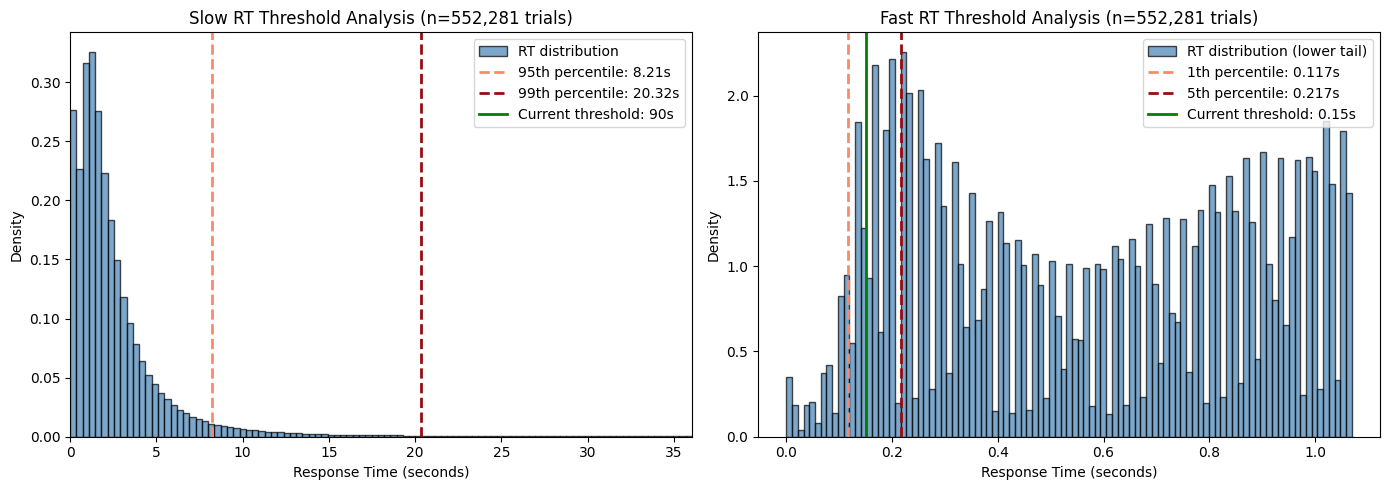

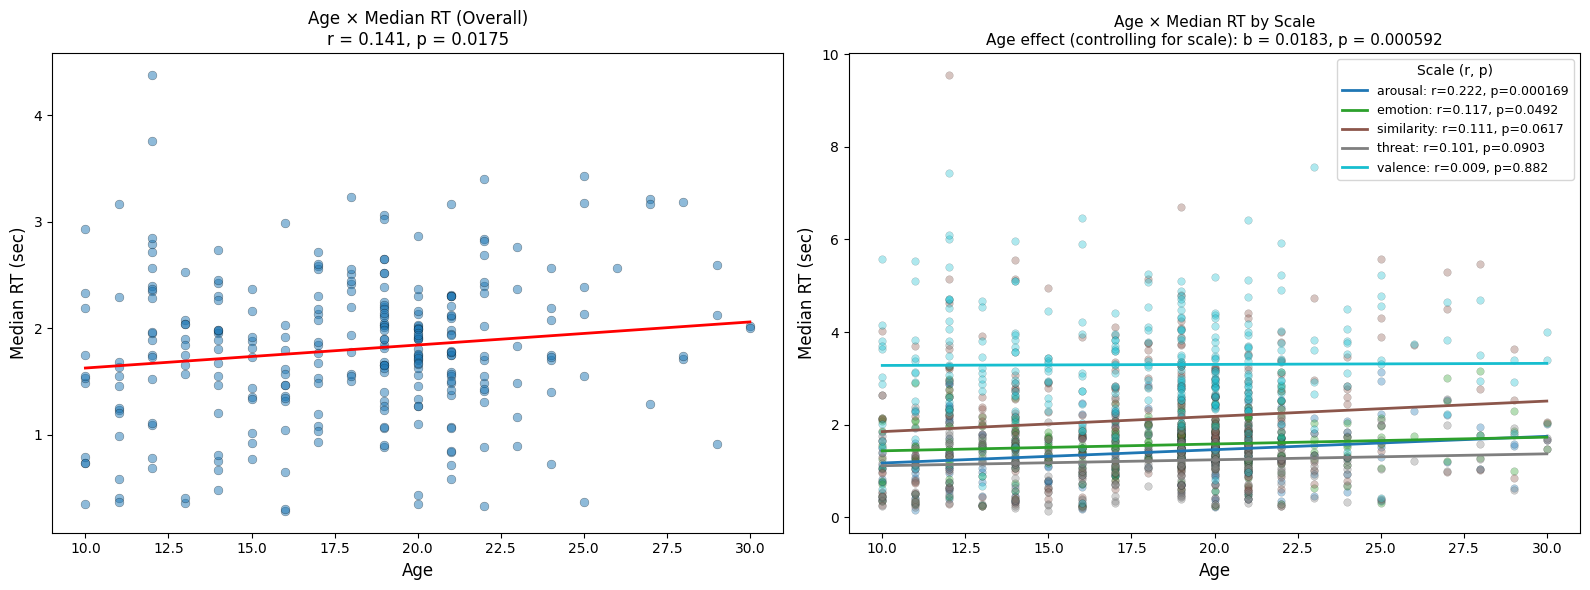

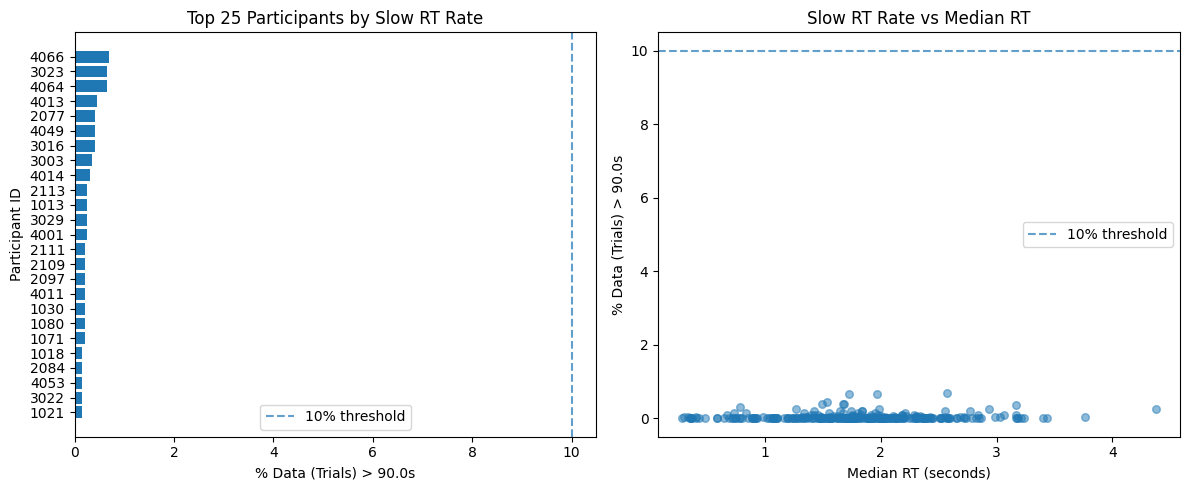

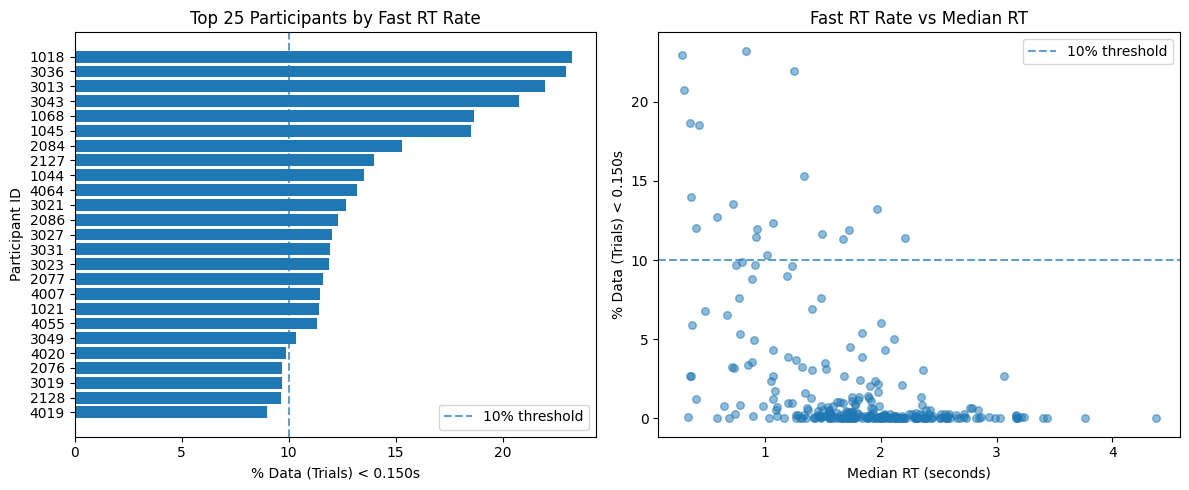


RUNNING PERMUTATION NULLS (DIAGNOSTICS)
Running 1000 permutations per participant-session...

Analyzing straight-line null distribution...
STRAIGHT-LINE THRESHOLD ANALYSIS
Null distribution (pooled from 553 participant-sessions x permutations):
  Mean max run by chance: 7.4
  Median max run by chance: 6.0
  Max observed in null: 225
----------------------------------------------------------------------
Null percentile markers (pooled over these participant-sessions):
  95th percentile: 14 (79 participant-sessions exceed, 14.3%)
  99th percentile: 21 (51 participant-sessions exceed, 9.2%)
----------------------------------------------------------------------
Observed data:
  Global max run: 631
  Mean max run per participant-session: 11.8
  Median max run per participant-session: 5.0
----------------------------------------------------------------------
Per-participant analysis (observed vs own null):
  Participants exceeding their own 95th pct null: 111 (20.1%)
  Participants exceedin

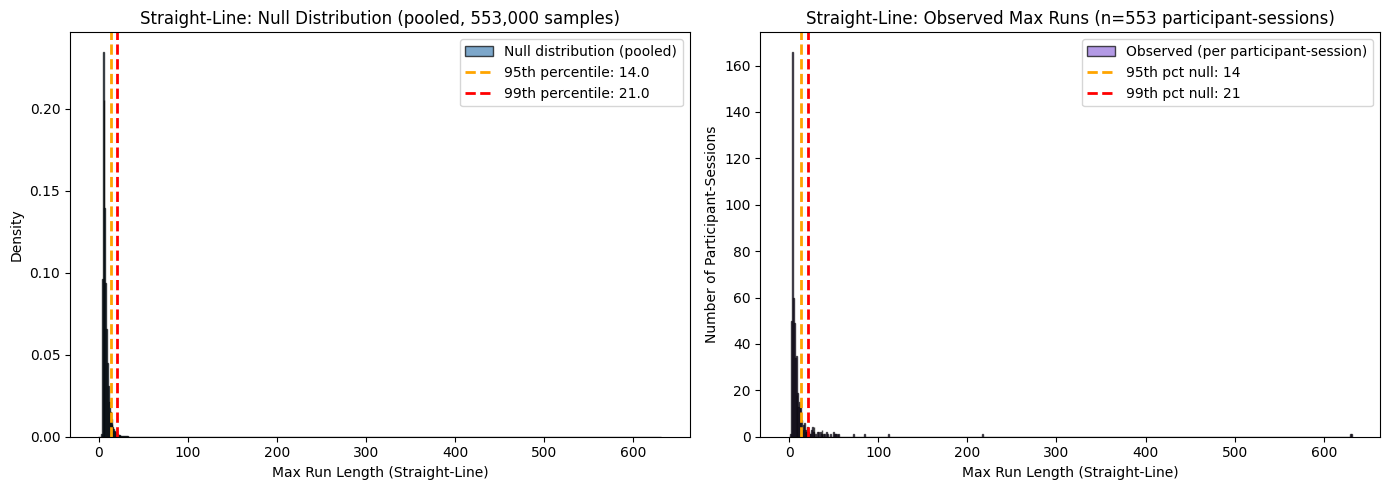


Building periodic null distributions for p=[2, 3, 4] (1000 permutations per participant-session, shared shuffles)...
PERIODIC P=2 THRESHOLD ANALYSIS
Null distribution (pooled from 553 participant-sessions x permutations):
  Mean max run by chance: 5.9
  Median max run by chance: 6.0
  Max observed in null: 18
----------------------------------------------------------------------
Null percentile markers (pooled over these participant-sessions):
  95th percentile: 8 (19 participant-sessions exceed, 3.4%)
  99th percentile: 9 (15 participant-sessions exceed, 2.7%)
----------------------------------------------------------------------
Observed data:
  Global max run: 21
  Mean max run per participant-session: 5.2
  Median max run per participant-session: 5.0
----------------------------------------------------------------------
Per-participant analysis (observed vs own null):
  Participants exceeding their own 95th pct null: 16 (2.9%)
  Participants exceeding their own 99th pct null: 13 (

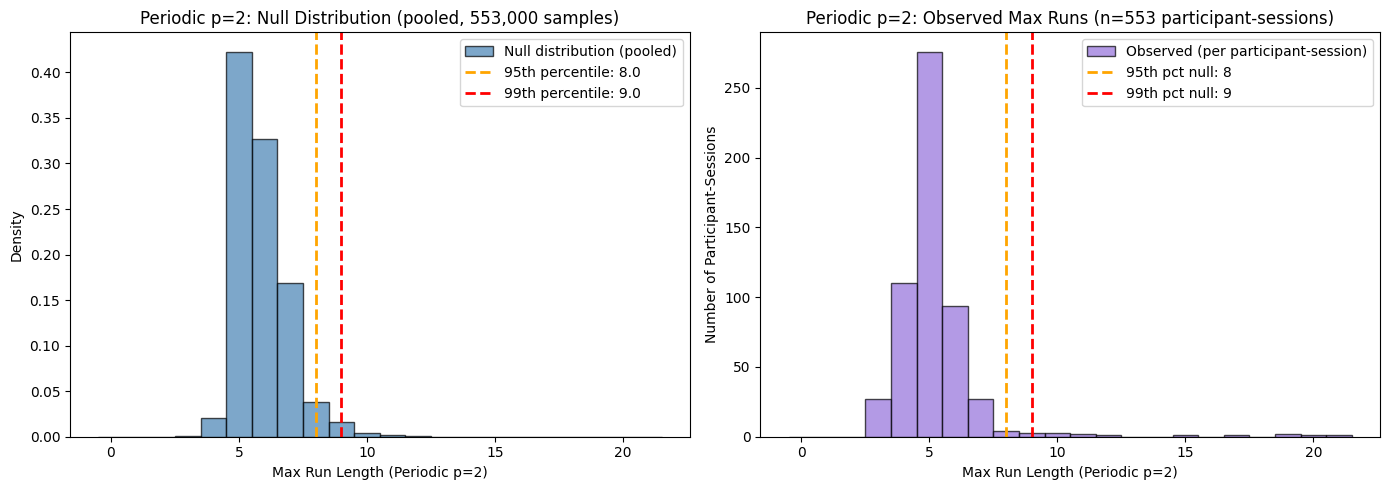

PERIODIC P=3 THRESHOLD ANALYSIS
Null distribution (pooled from 553 participant-sessions x permutations):
  Mean max run by chance: 7.2
  Median max run by chance: 7.0
  Max observed in null: 21
----------------------------------------------------------------------
Null percentile markers (pooled over these participant-sessions):
  95th percentile: 9 (19 participant-sessions exceed, 3.4%)
  99th percentile: 11 (7 participant-sessions exceed, 1.3%)
----------------------------------------------------------------------
Observed data:
  Global max run: 19
  Mean max run per participant-session: 6.3
  Median max run per participant-session: 6.0
----------------------------------------------------------------------
Per-participant analysis (observed vs own null):
  Participants exceeding their own 95th pct null: 12 (2.2%)
  Participants exceeding their own 99th pct null: 8 (1.4%)


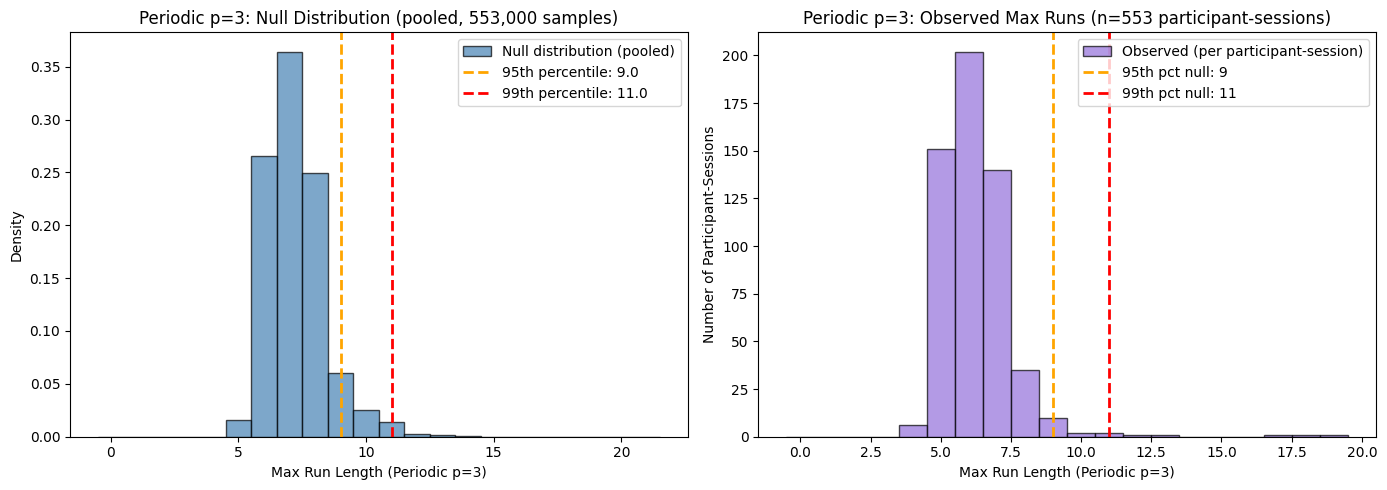

PERIODIC P=4 THRESHOLD ANALYSIS
Null distribution (pooled from 553 participant-sessions x permutations):
  Mean max run by chance: 8.3
  Median max run by chance: 8.0
  Max observed in null: 34
----------------------------------------------------------------------
Null percentile markers (pooled over these participant-sessions):
  95th percentile: 11 (36 participant-sessions exceed, 6.5%)
  99th percentile: 13 (3 participant-sessions exceed, 0.5%)
----------------------------------------------------------------------
Observed data:
  Global max run: 18
  Mean max run per participant-session: 8.0
  Median max run per participant-session: 8.0
----------------------------------------------------------------------
Per-participant analysis (observed vs own null):
  Participants exceeding their own 95th pct null: 17 (3.1%)
  Participants exceeding their own 99th pct null: 8 (1.4%)


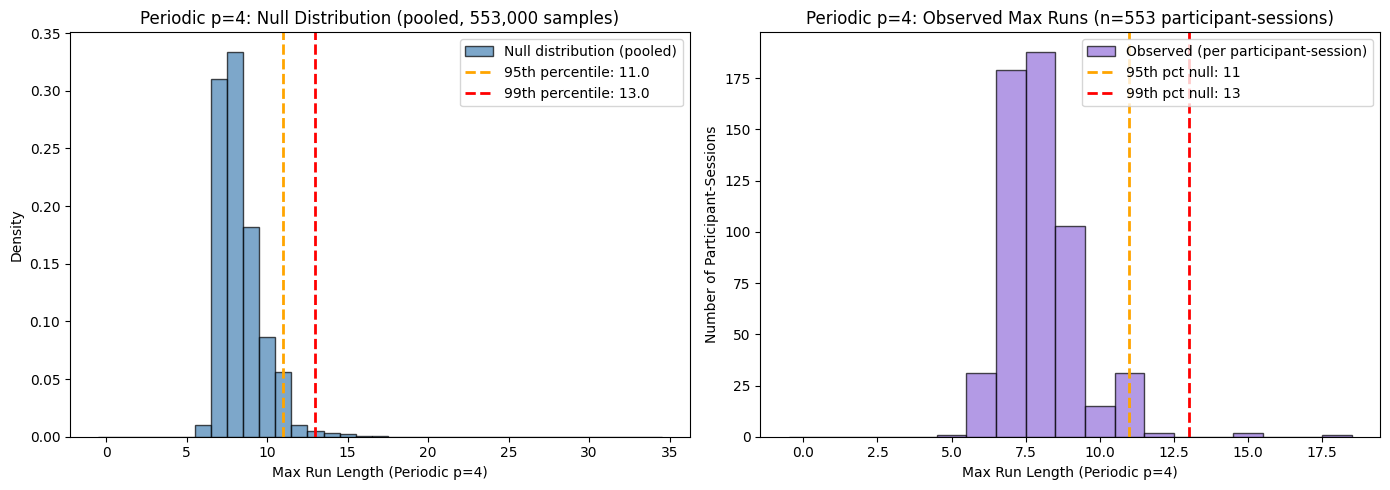


Analyzing 5-response stimulus-linked pattern null distribution...
5-RESPONSE STIMULUS-LINKED PATTERN THRESHOLD ANALYSIS
Null distribution (pooled from 553 participant-sessions x permutations):
  Mean max run by chance: 1.8
  Median max run by chance: 2.0
  Max observed in null: 84
----------------------------------------------------------------------
Null percentile markers (pooled over these participant-sessions):
  95th percentile: 4 (188 participant-sessions exceed, 34.0%)
  99th percentile: 8 (60 participant-sessions exceed, 10.8%)
----------------------------------------------------------------------
Observed data:
  Global max run: 126
  Mean max run per participant-session: 4.7
  Median max run per participant-session: 3.0
----------------------------------------------------------------------
Per-participant analysis (observed vs own null):
  Participants exceeding their own 95th pct null: 262 (47.4%)
  Participants exceeding their own 99th pct null: 219 (39.6%)


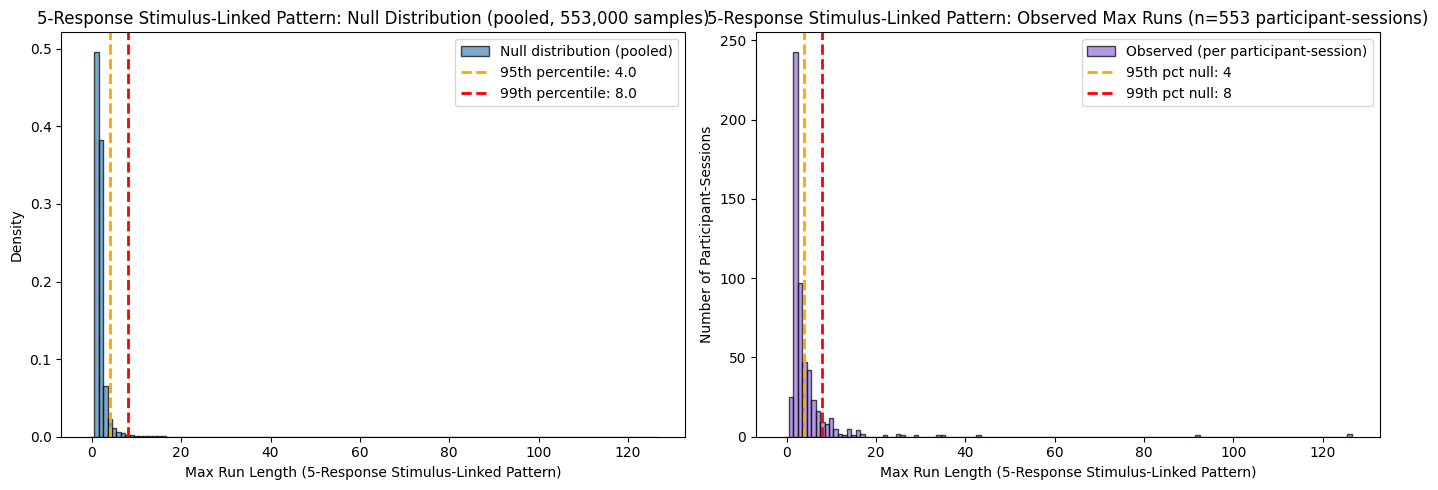


PERMUTATION-NULL MARKERS (run length at the 95th / 99th percentile of each null)
The T2 columns are the calibration values for LVL_2_CONFIG's inattent_behav_*_thresh ([cell 28]).
                                    ALL 95th  ALL 99th  T2 95th  T2 99th  T3 95th  T3 99th
detector                                                                                  
Straight-Line                             14        21       12       20       15       23
Periodic p=2                               8         9        8        9        8        9
Periodic p=3                               9        11        9       11        9       11
Periodic p=4                              11        13       11       13       11       13
5-Response Stimulus-Linked Pattern         4         8        4        9        3        6

Flagged-trial displays at the T2-null 99th percentile (display only): straight-line 20, periodic p=2/3/4 9/11/13, stimulus-linked 9
STRAIGHT-LINE DETECTION SUMMARY
Definition: Same r

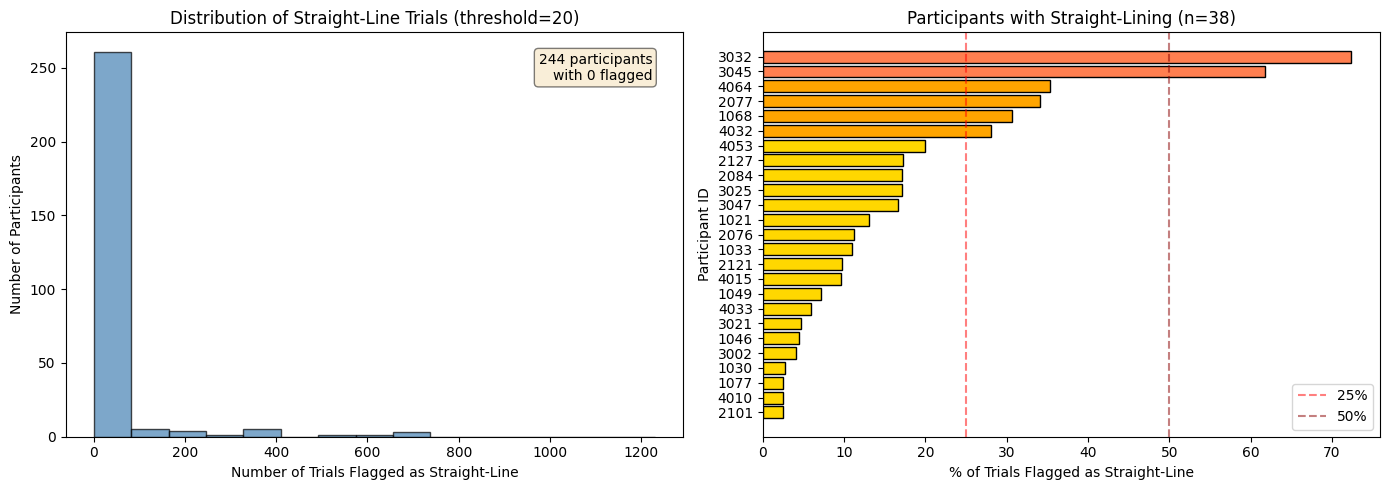


PERIODIC PATTERNS AT THE T2-NULL 99TH PERCENTILE (display only)
  p=2 (run >= 9): 549 trials (0.10%) across 13 participants
  p=3 (run >= 11): 137 trials (0.02%) across 6 participants
  p=4 (run >= 13): 48 trials (0.01%) across 3 participants
  ANY periodic: 734 trials (0.13%) across 16 participants
INATTENTIVE PATTERN DETECTION SUMMARY
Definition: Same response to 9+ consecutive stimuli (within scale)
Note: Straight-line responses are excluded before detection
----------------------------------------------------------------------
Total participants: 282
Participants with 5-response stimulus-linked patterns: 25 (8.9%)
Participants without 5-response stimulus-linked patterns: 257 (91.1%)

Among participants WITH 5-response stimulus-linked patterns:
  Mean trials flagged: 239.6
  Median trials flagged: 105
  Max trials flagged: 840
  Mean % of trials: 13.8%
  Longest run: 92 consecutive stimuli


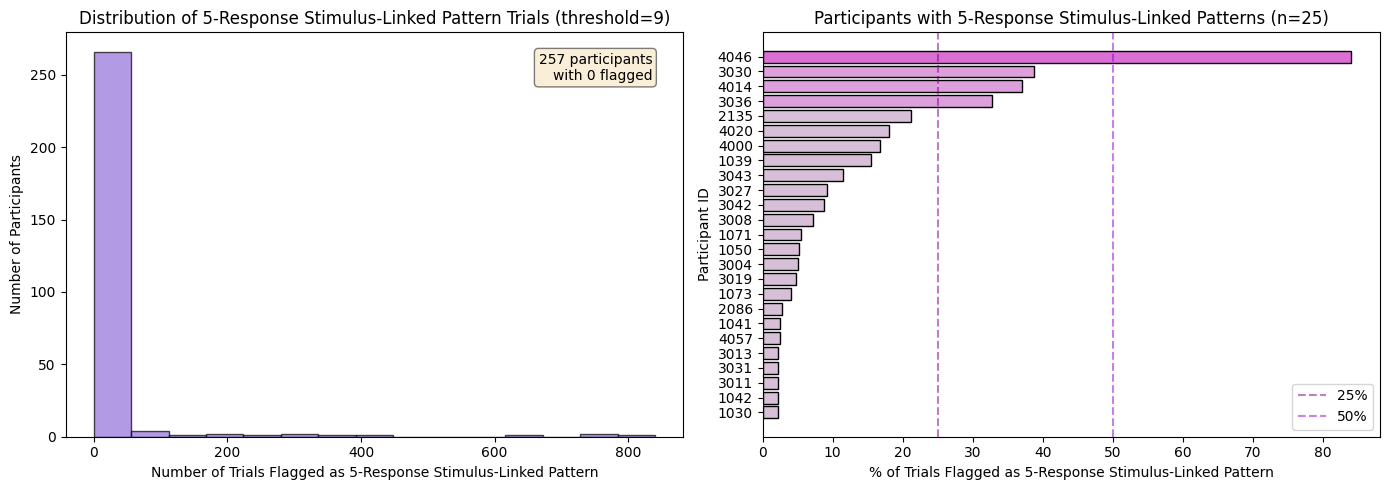

In [6]:
# [cell 5]
# =============================================================================
# RESPONSE STYLE QC
# =============================================================================

def plot_rt_threshold_analysis(
    df: pd.DataFrame,
    rt_col: str = "rt_sec",
    id_col: str = "id",
    percentiles_slow: list = [95, 99],
    percentiles_fast: list = [1, 5],
    current_max_thresh: float = None,
    current_min_thresh: float = None,
) -> tuple[plt.Figure, dict]:
    """
    Data-driven RT threshold analysis using empirical percentiles.
    
    Parameters
    ----------
    df : pd.DataFrame
        Long-format data with RT column
    rt_col : str
        Column containing RT values
    percentiles_slow : list
        Percentiles to suggest for slow RT threshold (upper tail)
    percentiles_fast : list
        Percentiles to suggest for fast RT threshold (lower tail)
    current_max_thresh, current_min_thresh : float
        Current threshold settings to display
    
    Returns
    -------
    tuple: (plt.Figure, dict of suggested thresholds)
    """
    rts = df[rt_col].dropna().values
    
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    
    suggested_thresholds = {"slow": {}, "fast": {}}
    colors = plt.cm.Reds(np.linspace(0.4, 0.9, max(len(percentiles_slow), len(percentiles_fast))))

    
    # === LEFT: Slow RT analysis ===
    ax = axes[0]
    
    # Histogram of all RTs (focus on upper tail)
    rt_99 = np.percentile(rts, 99.5)
    bins = np.linspace(0, min(rt_99 * 1.2, rts.max()), 100)
    ax.hist(rts, bins=bins, density=True, alpha=0.7, color="steelblue", 
            edgecolor="black", label="RT distribution")
    
    # Mark percentile thresholds for slow RTs
    for i, pct in enumerate(percentiles_slow):
        thresh = np.percentile(rts, pct)
        suggested_thresholds["slow"][pct] = thresh
        ax.axvline(thresh, color=colors[i % len(colors)], linestyle="--", linewidth=2,
                   label=f"{pct}th percentile: {thresh:.2f}s")
    
    if current_max_thresh is not None:
        ax.axvline(current_max_thresh, color="green", linestyle="-", linewidth=2,
                   label=f"Current threshold: {current_max_thresh}s")
    
    ax.set_xlabel("Response Time (seconds)")
    ax.set_ylabel("Density")
    ax.set_title(f"Slow RT Threshold Analysis (n={len(rts):,} trials)")
    ax.legend(loc="upper right")
    ax.set_xlim(0, min(rt_99 * 1.2, rts.max()))
    
    # === RIGHT: Fast RT analysis ===
    ax = axes[1]
    
    # Histogram focused on lower tail
    rt_10 = np.percentile(rts, 10)
    bins = np.linspace(0, rt_10 * 3, 100)
    ax.hist(rts[rts < rt_10 * 3], bins=bins, density=True, alpha=0.7, color="steelblue", 
            edgecolor="black", label="RT distribution (lower tail)")
    
    # Mark percentile thresholds for fast RTs
    for i, pct in enumerate(percentiles_fast):
        thresh = np.percentile(rts, pct)
        suggested_thresholds["fast"][pct] = thresh
        ax.axvline(thresh, color=colors[i % len(colors)], linestyle="--", linewidth=2,
                   label=f"{pct}th percentile: {thresh:.3f}s")
    
    if current_min_thresh is not None:
        ax.axvline(current_min_thresh, color="green", linestyle="-", linewidth=2,
                   label=f"Current threshold: {current_min_thresh}s")
    
    ax.set_xlabel("Response Time (seconds)")
    ax.set_ylabel("Density")
    ax.set_title(f"Fast RT Threshold Analysis (n={len(rts):,} trials)")
    ax.legend(loc="upper right")
    
    plt.tight_layout()
    
    # Print summary
    n_total = len(rts)
    print("=" * 70)
    print("RT THRESHOLD ANALYSIS (Empirical Percentiles)")
    print("=" * 70)
    print(f"Total trials: {n_total:,}")
    print(f"RT range: {rts.min():.3f}s - {rts.max():.1f}s")
    print(f"Median RT: {np.median(rts):.2f}s")
    print(f"Mean RT: {np.mean(rts):.2f}s")
    print("-" * 70)
    
    print("SLOW RT thresholds (upper tail):")
    for pct in percentiles_slow:
        thresh = suggested_thresholds["slow"][pct]
        n_exceed = np.sum(rts > thresh)
        pct_exceed = 100 * n_exceed / n_total
        print(f"  {pct}th percentile: {thresh:.2f}s ({n_exceed:,} trials exceed, {pct_exceed:.1f}%)")
    if current_max_thresh is not None:
        n_exceed = np.sum(rts > current_max_thresh)
        pct_exceed = 100 * n_exceed / n_total
        print(f"  Current threshold ({current_max_thresh}s): {n_exceed:,} trials exceed ({pct_exceed:.2f}%)")
    
    print("-" * 70)
    print("FAST RT thresholds (lower tail):")
    for pct in percentiles_fast:
        thresh = suggested_thresholds["fast"][pct]
        n_below = np.sum(rts < thresh)
        pct_below = 100 * n_below / n_total
        print(f"  {pct}th percentile: {thresh:.3f}s ({n_below:,} trials below, {pct_below:.1f}%)")
    if current_min_thresh is not None:
        n_below = np.sum(rts < current_min_thresh)
        pct_below = 100 * n_below / n_total
        print(f"  Current threshold ({current_min_thresh}s): {n_below:,} trials below ({pct_below:.2f}%)")
    
    # Per-participant summary
    print("-" * 70)
    print("Per-participant analysis:")
    participant_medians = df.groupby(id_col)[rt_col].median()
    print(f"  Median RT range across participants: {participant_medians.min():.2f}s - {participant_medians.max():.2f}s")
    print(f"  Mean of participant medians: {participant_medians.mean():.2f}s")
    print("=" * 70)
    
    return fig, suggested_thresholds


def plot_slow_rt_by_participant(
    df: pd.DataFrame,
    config: dict,  
    rt_col: str = "rt_sec",
    id_col: str = "id",
) -> plt.Figure:
    """
    Show participants with the slowest RTs.
    """
    # 1. Extract parameters from the config dictionary first
    slow_threshold = config["max_rt_thresh"]
    top_n = config["sub_n_plots"]

    # 2. Perform the data aggregation
    stats_df = df.groupby(id_col).agg(
        n_trials=(rt_col, "count"),
        n_slow=(rt_col, lambda x: (x > slow_threshold).sum()), # Count slow responses (based on max_rt_thresh)
        max_rt=(rt_col, "max"),
        median_rt=(rt_col, "median"),
    ).reset_index()

    # zero-guard so participants with all-NaN RT do not yield inf/NaN.
    stats_df["pct_slow"] = np.where(
        stats_df["n_trials"] > 0,
        100 * stats_df["n_slow"] / stats_df["n_trials"].replace(0, np.nan),
        0.0,
    )
    stats_df = stats_df[stats_df["n_trials"] > 0]
    stats_df = stats_df.sort_values("pct_slow", ascending=False).head(top_n)

    fig, axes = plt.subplots(1, 2, figsize=(12, 5))

    ax = axes[0]
    ax.barh(range(len(stats_df)), stats_df["pct_slow"])
    ax.set_yticks(range(len(stats_df)))
    ax.set_yticklabels(stats_df[id_col].astype(str))
    ax.set_xlabel(f"% Data (Trials) > {slow_threshold:.1f}s")
    ax.set_ylabel("Participant ID")
    ax.set_title(f"Top {top_n} Participants by Slow RT Rate")
    ax.axvline(10, linestyle="--", alpha=0.7, label="10% threshold")
    ax.legend()
    ax.invert_yaxis()

    ax = axes[1]
    all_stats = df.groupby(id_col).agg(
        n_trials=(rt_col, "count"),
        n_slow=(rt_col, lambda x: (x > slow_threshold).sum()),
        median_rt=(rt_col, "median"),
    ).reset_index()
    # zero-guard
    all_stats["pct_slow"] = np.where(
        all_stats["n_trials"] > 0,
        100 * all_stats["n_slow"] / all_stats["n_trials"].replace(0, np.nan),
        0.0,
    )

    ax.scatter(all_stats["median_rt"], all_stats["pct_slow"], alpha=0.5, s=30)
    ax.axhline(10, linestyle="--", alpha=0.7, label="10% threshold")
    ax.set_xlabel("Median RT (seconds)")
    ax.set_ylabel(f"% Data (Trials) > {slow_threshold:.1f}s")
    ax.set_title("Slow RT Rate vs Median RT")
    ax.legend()

    fig.tight_layout()
    return fig


def plot_fast_rt_by_participant(
    df: pd.DataFrame,
    config: dict,  
    rt_col: str = "rt_sec",
    id_col: str = "id",
) -> plt.Figure:
    """
    Show participants with the fastest RTs.
    """
    fast_threshold = config["min_rt_thresh"]
    top_n = config["sub_n_plots"]

    stats_df = df.groupby(id_col).agg(
        n_trials=(rt_col, "count"),
        n_fast=(rt_col, lambda x: (x < fast_threshold).sum()),
        min_rt=(rt_col, "min"),
        median_rt=(rt_col, "median"),
    ).reset_index()

    # zero-guard
    stats_df["pct_fast"] = np.where(
        stats_df["n_trials"] > 0,
        100 * stats_df["n_fast"] / stats_df["n_trials"].replace(0, np.nan),
        0.0,
    )
    stats_df = stats_df[stats_df["n_trials"] > 0]
    stats_df = stats_df.sort_values("pct_fast", ascending=False).head(top_n)

    fig, axes = plt.subplots(1, 2, figsize=(12, 5))

    ax = axes[0]
    ax.barh(range(len(stats_df)), stats_df["pct_fast"])
    ax.set_yticks(range(len(stats_df)))
    ax.set_yticklabels(stats_df[id_col].astype(str))
    ax.set_xlabel(f"% Data (Trials) < {fast_threshold:.3f}s")
    ax.set_ylabel("Participant ID")
    ax.set_title(f"Top {top_n} Participants by Fast RT Rate")
    ax.axvline(10, linestyle="--", alpha=0.7, label="10% threshold")
    ax.legend()
    ax.invert_yaxis()

    ax = axes[1]
    all_stats = df.groupby(id_col).agg(
        n_trials=(rt_col, "count"),
        n_fast=(rt_col, lambda x: (x < fast_threshold).sum()),
        median_rt=(rt_col, "median"),
    ).reset_index()
    # zero-guard
    all_stats["pct_fast"] = np.where(
        all_stats["n_trials"] > 0,
        100 * all_stats["n_fast"] / all_stats["n_trials"].replace(0, np.nan),
        0.0,
    )

    ax.scatter(all_stats["median_rt"], all_stats["pct_fast"], alpha=0.5, s=30)
    ax.axhline(10, linestyle="--", alpha=0.7, label="10% threshold")
    ax.set_xlabel("Median RT (seconds)")
    ax.set_ylabel(f"% Data (Trials) < {fast_threshold:.3f}s")
    ax.set_title("Fast RT Rate vs Median RT")
    ax.legend()

    fig.tight_layout()
    return fig


def detect_straight_lines(
    df: pd.DataFrame,
    sl_thresh: int,
    response_col: str = "response",
    id_col: str = "id",
    session_col: str = "session",
    stim_col: str = "resp_order",  # Use resp_order for actual response order
    _n_jobs: int = 1,  # default matches docstring; pass -1 explicitly to use all cores
) -> pd.DataFrame:
    """
    Detect straight-line responding: same response value for sl_thresh+ consecutive trials.
    
    A trial = one response to one scale. Straight-lining is detected when a participant
    gives the identical response value for sl_thresh or more consecutive trials,
    regardless of which scale is being rated.

    Parallelization
    ---------------
    This function parallelizes across participant×session groups using joblib.
    If n_jobs is None, it tries to use LVL_0_CONFIG["n_jobs"] when available; otherwise defaults to 1.
    """
    # validate stim_col exists; otherwise groupby+sort_values would
    # raise a confusing pandas error deep in the stack.
    if stim_col not in df.columns:
        raise ValueError(
            f"detect_straight_lines: stim_col='{stim_col}' not found in df. "
            f"Available columns: {list(df.columns)[:20]}..."
        )

    df = df.copy()
    
    if sl_thresh <= 0:
        df["is_straight_line"] = False
        df["sl_run_length"] = 0
        return df
    
    
    # also drop a 'run_length' column if present, so it cannot shadow sl_run_length.
    for col in ["is_straight_line", "sl_run_length", "run_length"]:
        if col in df.columns:
            df = df.drop(columns=[col])
    
    # Initialize columns
    df["is_straight_line"] = False
    df["sl_run_length"] = 0
    
    def _compute_run_lengths(orig_idx: np.ndarray, responses: np.ndarray):
        """Compute the consecutive-identical run length each position belongs to.

        NaN handling: NaN responses act as run terminators. A NaN at
        position k is assigned run_length=0 and breaks any run on either
        side. Sequence [5, 5, NaN, 5, 5] therefore yields two separate
        runs of length 2 each, not one run of 4.
        """
        n = len(responses)
        run_lengths = np.zeros(n, dtype=int)
        
        i = 0
        while i < n:
            # Skip NaN responses (they terminate any surrounding run)
            if pd.isna(responses[i]):
                i += 1
                continue
            
            # Find end of this run of identical responses
            j = i + 1
            while j < n and responses[j] == responses[i]:
                j += 1
            
            run_len = j - i
            run_lengths[i:j] = run_len
            i = j
        
        is_sl = run_lengths >= sl_thresh
        return orig_idx, run_lengths, is_sl
    
    # Build tasks: (sorted original indices, response array) for each participant×session
    tasks = []
    for _, group in df.groupby([id_col, session_col], sort=False):
        sorted_idx = group.sort_values(stim_col).index.to_numpy()
        responses = df.loc[sorted_idx, response_col].to_numpy()
        tasks.append((sorted_idx, responses))
    
    if _n_jobs == 1 or len(tasks) == 0:
        results = [_compute_run_lengths(idx, resp) for idx, resp in tasks]
    else:
        results = Parallel(n_jobs=_n_jobs)(
            delayed(_compute_run_lengths)(idx, resp) for idx, resp in tasks
        )
    
    # Write back to original dataframe (no race conditions: we assign after parallel section)
    for orig_idx, run_lengths, is_sl in results:
        df.loc[orig_idx, "sl_run_length"] = run_lengths.astype(int)
        df.loc[orig_idx, "is_straight_line"] = is_sl.astype(bool)
    
    return df


def summarize_straight_lines(df: pd.DataFrame, sl_thresh: int, id_col: str = "id") -> pd.DataFrame:
    """Summarize straight-line statistics per participant."""
    if "is_straight_line" not in df.columns:
        df = detect_straight_lines(df, sl_thresh, _n_jobs=n_jobs)
    
    summary = df.groupby(id_col).agg(
        n_trials=("response", "count"),
        n_sl_trials=("is_straight_line", "sum"),
        max_run_length=("sl_run_length", "max"),
    ).reset_index()
    
    summary["pct_sl"] = np.where(
    summary["n_trials"] > 0,
    100 * summary["n_sl_trials"] / summary["n_trials"],
    0.0,
    )
    
    
    return summary


def plot_straight_line_histogram(df: pd.DataFrame, sl_thresh: int, id_col: str = "id", top_n: int = 25) -> plt.Figure:
    """Plot straight-line detection results."""
    if "is_straight_line" not in df.columns:
        df = detect_straight_lines(df, sl_thresh, _n_jobs=n_jobs)
    
    summary = summarize_straight_lines(df, sl_thresh=sl_thresh, id_col=id_col)
    
    n_total = len(summary)
    n_with_sl = (summary["n_sl_trials"] > 0).sum()
    pct_with_sl = 100 * n_with_sl / n_total if n_total > 0 else 0
    
    print("=" * 70)
    print(f"STRAIGHT-LINE DETECTION SUMMARY")
    print("=" * 70)
    print(f"Definition: Same response for {sl_thresh}+ consecutive trials")
    print("-" * 70)
    print(f"Total participants: {n_total}")
    print(f"Participants with straight-lining: {n_with_sl} ({pct_with_sl:.1f}%)")
    print(f"Participants without straight-lining: {n_total - n_with_sl} ({100 - pct_with_sl:.1f}%)")
    
    if n_with_sl > 0:
        sl_only = summary[summary["n_sl_trials"] > 0]
        print(f"\nAmong participants WITH straight-lining:")
        print(f"  Mean trials flagged: {sl_only['n_sl_trials'].mean():.1f}")
        print(f"  Median trials flagged: {sl_only['n_sl_trials'].median():.0f}")
        print(f"  Max trials flagged: {sl_only['n_sl_trials'].max()}")
        print(f"  Mean % of trials: {sl_only['pct_sl'].mean():.1f}%")
        print(f"  Longest run: {sl_only['max_run_length'].max()} consecutive trials")
    print("=" * 70)
    
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    
    # Left: Distribution
    ax = axes[0]
    sl_counts = summary["n_sl_trials"]
    if sl_counts.max() > 0:
        bins = np.arange(0, sl_counts.max() + 10, max(1, int(sl_counts.max() // 15)))
        ax.hist(sl_counts, bins=bins, edgecolor="black", alpha=0.7, color="steelblue")
    else:
        ax.hist(sl_counts, bins=20, edgecolor="black", alpha=0.7, color="steelblue")
    ax.set_xlabel("Number of Trials Flagged as Straight-Line")
    ax.set_ylabel("Number of Participants")
    ax.set_title(f"Distribution of Straight-Line Trials (threshold={sl_thresh})")
    ax.text(0.95, 0.95, f"{n_total - n_with_sl} participants\nwith 0 flagged", 
            transform=ax.transAxes, ha="right", va="top", fontsize=10,
            bbox=dict(boxstyle="round", facecolor="wheat", alpha=0.5))
    
    # Right: Top offenders
    ax = axes[1]
    top_sl = summary[summary["n_sl_trials"] > 0].nlargest(top_n, "pct_sl")
    if len(top_sl) > 0:
        colors = ["coral" if pct > 50 else "orange" if pct > 25 else "gold" for pct in top_sl["pct_sl"]]
        ax.barh(range(len(top_sl)), top_sl["pct_sl"], color=colors, edgecolor="black")
        ax.set_yticks(range(len(top_sl)))
        ax.set_yticklabels(top_sl[id_col].astype(str))
        ax.set_xlabel("% of Trials Flagged as Straight-Line")
        ax.set_ylabel("Participant ID")
        ax.set_title(f"Participants with Straight-Lining (n={n_with_sl})")
        ax.invert_yaxis()
        ax.axvline(25, color="red", linestyle="--", alpha=0.5, label="25%")
        ax.axvline(50, color="darkred", linestyle="--", alpha=0.5, label="50%")
        ax.legend(loc="lower right")
    else:
        ax.text(0.5, 0.5, f"No straight-lining detected\n(threshold = {sl_thresh} consecutive trials)", 
                ha="center", va="center", transform=ax.transAxes, fontsize=12)
        ax.set_title("Participants with Straight-Lining")
    
    plt.tight_layout()
    return fig


def detect_inattentive_patterns(
    df: pd.DataFrame,
    stim_ip_thresh: int,
    response_col: str = "response",
    id_col: str = "id",
    session_col: str = "session",
    scale_col: str = "scale",
    stim_col: str = "stim_order",
    mask_straight_lines: bool = True,
    _n_jobs: int = None
) -> pd.DataFrame:
    """
    Detect inattentive response patterns: identical response vectors across consecutive stimuli.
    
    This detects when a participant gives the SAME response pattern to consecutive stimuli,
    i.e., their response vector (across all scales) for stimulus N is identical to stimulus N-1.
    
    For example, if a participant rates:
        Stimulus 1: valence=1, arousal=2, threat=3, similarity=4, emotion=5
        Stimulus 2: valence=1, arousal=2, threat=3, similarity=4, emotion=5
        Stimulus 3: valence=1, arousal=2, threat=3, similarity=4, emotion=5
    
    This is a 5-response stimulus-linked pattern - they're not differentiating between stimuli.
    
    Parameters
    ----------
    df : pd.DataFrame
        Long-format data with responses
    stim_ip_thresh : int
        Minimum consecutive identical stimulus response vectors to flag as inattentive
    response_col : str
        Column containing response values
    id_col : str
        Column containing participant IDs
    session_col : str
        Column containing session numbers
    scale_col : str
        Column containing scale names
    stim_col : str
        Column containing stimulus order
    mask_straight_lines : bool
        If True, exclude already-flagged straight-line responses before detection
        (requires 'is_straight_line' column)
    n_jobs : int
        Number of parallel workers
    
    Returns
    -------
    pd.DataFrame
        DataFrame with added columns:
        - is_inattentive_pattern: bool, whether trial is part of 5-response stimulus-linked pattern
        - ip_run_length: int, length of the 5-response stimulus-linked pattern run (in stimuli)
    """
    df = df.copy()
    
    if stim_ip_thresh <= 0:
        df["is_inattentive_pattern"] = False
        df["ip_run_length"] = 0
        return df
    
    # Resolve n_jobs (use global n_jobs if not specified)
    if _n_jobs is None:
        try:
            _n_jobs = n_jobs  # global n_jobs set in the BLAS/thread-limits cell
        except NameError:
            _n_jobs = 1
    _n_jobs = max(1, int(_n_jobs))
    
    # Remove existing columns if present
    for col in ["is_inattentive_pattern", "ip_run_length"]:
        if col in df.columns:
            df = df.drop(columns=[col])
    
    # Initialize columns
    df["is_inattentive_pattern"] = False
    df["ip_run_length"] = 0
    
    # Create working copy, masking straight-lines if requested
    work_df = df.copy()
    if mask_straight_lines and "is_straight_line" in df.columns:
        work_df.loc[work_df["is_straight_line"], response_col] = np.nan
    
    def _detect_ip_for_group(group_df):
        """Detect 5-response stimulus-linked patterns for a single participant-session group."""
        # Get unique stimuli in order
        stim_orders = sorted(group_df[stim_col].unique())
        n_stim = len(stim_orders)
        
        if n_stim < stim_ip_thresh:
            return [], []
        
        # Get scales (consistent order)
        scales = sorted(group_df[scale_col].unique())
        
        # Build response vectors for each stimulus
        # response_vectors[stim_order] = tuple of responses in scale order (or None if any missing)
        response_vectors = {}
        stim_indices = {}  # stim_order -> list of original indices for that stimulus
        
        for stim_order in stim_orders:
            stim_data = group_df[group_df[stim_col] == stim_order]
            stim_indices[stim_order] = stim_data.index.tolist()
            
            # Build response vector in consistent scale order
            resp_dict = dict(zip(stim_data[scale_col], stim_data[response_col]))
            
            # Check if all scales present and no NaN
            if len(resp_dict) == len(scales) and all(not pd.isna(resp_dict.get(s)) for s in scales):
                response_vectors[stim_order] = tuple(resp_dict[s] for s in scales)
            else:
                response_vectors[stim_order] = None  # Mark as invalid (missing or NaN)
        
        # Find runs of identical response vectors
        flagged_indices = []
        run_lengths = {}  # index -> run_length
        
        i = 0
        while i < n_stim:
            stim_i = stim_orders[i]
            vec_i = response_vectors[stim_i]
            
            # Skip if invalid vector
            if vec_i is None:
                i += 1
                continue
            
            # Find end of run of identical vectors
            j = i + 1
            while j < n_stim:
                stim_j = stim_orders[j]
                vec_j = response_vectors[stim_j]
                if vec_j is None or vec_j != vec_i:
                    break
                j += 1
            
            run_len = j - i  # Number of consecutive stimuli with identical vectors
            
            if run_len >= stim_ip_thresh:
                # Flag all trials for stimuli in this run
                for k in range(i, j):
                    stim_k = stim_orders[k]
                    for idx in stim_indices[stim_k]:
                        flagged_indices.append(idx)
                        run_lengths[idx] = run_len
            
            i = j
        
        return flagged_indices, run_lengths
    
    # Process each participant-session group
    all_flagged = []
    all_run_lengths = {}
    
    groups = list(work_df.groupby([id_col, session_col], sort=False))
    
    if _n_jobs == 1 or len(groups) == 0:
        for _, group_df in groups:
            flagged, run_lens = _detect_ip_for_group(group_df)
            all_flagged.extend(flagged)
            all_run_lengths.update(run_lens)
    else:
        results = Parallel(n_jobs=_n_jobs)(
            delayed(_detect_ip_for_group)(group_df) for _, group_df in groups
        )
        for flagged, run_lens in results:
            all_flagged.extend(flagged)
            all_run_lengths.update(run_lens)
    
    # Update original dataframe
    df.loc[all_flagged, "is_inattentive_pattern"] = True
    for idx, run_len in all_run_lengths.items():
        df.loc[idx, "ip_run_length"] = run_len
    
    return df


def summarize_inattentive_patterns(df: pd.DataFrame, stim_ip_thresh: int, id_col: str = "id") -> pd.DataFrame:
    """Summarize 5-response stimulus-linked pattern statistics per participant (at trial level)."""
    if "is_inattentive_pattern" not in df.columns:
        df = detect_inattentive_patterns(df, stim_ip_thresh=stim_ip_thresh)
    
    summary = df.groupby(id_col).agg(
        n_trials=("response", "count"),
        n_ip_trials=("is_inattentive_pattern", "sum"),
        max_ip_run_length=("ip_run_length", "max"),
    ).reset_index()
    
    summary["pct_ip"] = np.where(
    summary["n_trials"] > 0,
    100 * summary["n_ip_trials"] / summary["n_trials"],
    0.0,
    )

    
    return summary


def plot_inattentive_pattern_histogram(
    df: pd.DataFrame, 
    stim_ip_thresh: int, 
    id_col: str = "id", 
    top_n: int = 25
) -> plt.Figure:
    """Plot 5-response stimulus-linked pattern detection results (reported at trial level)."""
    if "is_inattentive_pattern" not in df.columns:
        df = detect_inattentive_patterns(df, stim_ip_thresh=stim_ip_thresh)
    
    summary = summarize_inattentive_patterns(df, stim_ip_thresh=stim_ip_thresh, id_col=id_col)
    
    n_total = len(summary)
    n_with_ip = (summary["n_ip_trials"] > 0).sum()
    pct_with_ip = 100 * n_with_ip / n_total if n_total > 0 else 0
    
    print("=" * 70)
    print(f"INATTENTIVE PATTERN DETECTION SUMMARY")
    print("=" * 70)
    print(f"Definition: Same response to {stim_ip_thresh}+ consecutive stimuli (within scale)")
    print(f"Note: Straight-line responses are excluded before detection")
    print("-" * 70)
    print(f"Total participants: {n_total}")
    print(f"Participants with 5-response stimulus-linked patterns: {n_with_ip} ({pct_with_ip:.1f}%)")
    print(f"Participants without 5-response stimulus-linked patterns: {n_total - n_with_ip} ({100 - pct_with_ip:.1f}%)")
    
    if n_with_ip > 0:
        ip_only = summary[summary["n_ip_trials"] > 0]
        print(f"\nAmong participants WITH 5-response stimulus-linked patterns:")
        print(f"  Mean trials flagged: {ip_only['n_ip_trials'].mean():.1f}")
        print(f"  Median trials flagged: {ip_only['n_ip_trials'].median():.0f}")
        print(f"  Max trials flagged: {ip_only['n_ip_trials'].max()}")
        print(f"  Mean % of trials: {ip_only['pct_ip'].mean():.1f}%")
        print(f"  Longest run: {ip_only['max_ip_run_length'].max()} consecutive stimuli")
    print("=" * 70)
    
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    
    # Left: Distribution
    ax = axes[0]
    ip_counts = summary["n_ip_trials"]
    if ip_counts.max() > 0:
        bins = np.arange(0, ip_counts.max() + 10, max(1, int(ip_counts.max() // 15)))
        ax.hist(ip_counts, bins=bins, edgecolor="black", alpha=0.7, color="mediumpurple")
    else:
        ax.hist(ip_counts, bins=20, edgecolor="black", alpha=0.7, color="mediumpurple")
    ax.set_xlabel("Number of Trials Flagged as 5-Response Stimulus-Linked Pattern")
    ax.set_ylabel("Number of Participants")
    ax.set_title(f"Distribution of 5-Response Stimulus-Linked Pattern Trials (threshold={stim_ip_thresh})")
    ax.text(0.95, 0.95, f"{n_total - n_with_ip} participants\nwith 0 flagged", 
            transform=ax.transAxes, ha="right", va="top", fontsize=10,
            bbox=dict(boxstyle="round", facecolor="wheat", alpha=0.5))
    
    # Right: Top offenders
    ax = axes[1]
    top_ip = summary[summary["n_ip_trials"] > 0].nlargest(top_n, "pct_ip")
    if len(top_ip) > 0:
        colors = ["orchid" if pct > 50 else "plum" if pct > 25 else "thistle" for pct in top_ip["pct_ip"]]
        ax.barh(range(len(top_ip)), top_ip["pct_ip"], color=colors, edgecolor="black")
        ax.set_yticks(range(len(top_ip)))
        ax.set_yticklabels(top_ip[id_col].astype(str))
        ax.set_xlabel("% of Trials Flagged as 5-Response Stimulus-Linked Pattern")
        ax.set_ylabel("Participant ID")
        ax.set_title(f"Participants with 5-Response Stimulus-Linked Patterns (n={n_with_ip})")
        ax.invert_yaxis()
        ax.axvline(25, color="purple", linestyle="--", alpha=0.5, label="25%")
        ax.axvline(50, color="darkviolet", linestyle="--", alpha=0.5, label="50%")
        ax.legend(loc="lower right")
    else:
        ax.text(0.5, 0.5, f"No 5-response stimulus-linked patterns detected\n(threshold = {stim_ip_thresh} consecutive stimuli)", 
                ha="center", va="center", transform=ax.transAxes, fontsize=12)
        ax.set_title("Participants with 5-Response Stimulus-Linked Patterns")
    
    plt.tight_layout()
    return fig


# =============================================================================
# PERMUTATION-BASED THRESHOLD ANALYSIS
# =============================================================================

def _single_perm_sl_per_participant(perm_seed, responses):
    """Single permutation for one participant's straight-line null."""
    rng = np.random.default_rng(perm_seed)
    shuffled = responses.copy()
    rng.shuffle(shuffled)
    
    max_run = 1
    current_run = 1
    for i in range(1, len(shuffled)):
        if pd.notna(shuffled[i]) and pd.notna(shuffled[i-1]) and shuffled[i] == shuffled[i-1]:
            current_run += 1
            max_run = max(max_run, current_run)
        else:
            current_run = 1
    return max_run


def permutation_null_straight_line(
    df: pd.DataFrame,
    n_permutations: int = 1000,
    response_col: str = "response",
    id_col: str = "id",
    session_col: str = "session",
    stim_col: str = "resp_order",
    random_state: int = 42,
    _n_jobs: int = None
) -> dict:
    """
    Build null distribution of max straight-line run lengths PER participant-session.
    
    For each participant-session, shuffles their responses n_permutations times
    and computes the max run length each time. Returns a distribution of what
    max runs that specific participant would show by chance.
    
    Returns
    -------
    dict
        {(pid, session): np.ndarray of max runs from permutations}
    """
    # Resolve n_jobs
    if _n_jobs is None:
        try:
            _n_jobs = n_jobs
        except NameError:
            _n_jobs = -1
    
    rng = np.random.default_rng(random_state)
    
    # Pre-extract response arrays for each group
    groups_data = {}
    for (pid, sess), group in df.groupby([id_col, session_col], sort=False):
        sorted_group = group.sort_values(stim_col)
        groups_data[(pid, sess)] = sorted_group[response_col].values.copy()
    
    # For each participant-session, run permutations. The Parallel() pool is
    # opened once and reused across all groups so we pay the pool-init cost
    # (~100ms for loky backend) one time instead of once per group.
    null_distributions = {}
    with Parallel(n_jobs=_n_jobs) as parallel:
        for (pid, sess), responses in groups_data.items():
            perm_seeds = rng.integers(0, 2**31, size=n_permutations)
            max_runs = parallel(
                delayed(_single_perm_sl_per_participant)(seed, responses)
                for seed in perm_seeds
            )
            null_distributions[(pid, sess)] = np.array(max_runs)

    return null_distributions


def _single_perm_ip_per_participant(perm_seed, scales, stim_orders, scale_responses):
    """Single permutation for one participant's 5-response stimulus-linked pattern null."""
    rng = np.random.default_rng(perm_seed)
    n_stim = len(stim_orders)
    
    if n_stim < 2:
        return 1
    
    # Shuffle responses within each scale independently
    shuffled_by_scale = {}
    for scale, (stim_list, resp_array) in scale_responses.items():
        shuffled = resp_array.copy()
        rng.shuffle(shuffled)
        for i, stim in enumerate(stim_list):
            shuffled_by_scale[(stim, scale)] = shuffled[i]
    
    # Build response vectors for each stimulus
    response_vectors = []
    for stim in stim_orders:
        vec = tuple(shuffled_by_scale.get((stim, s), np.nan) for s in scales)
        if any(pd.isna(v) for v in vec):
            response_vectors.append(None)
        else:
            response_vectors.append(vec)
    
    # Find max run of identical vectors
    max_run = 1
    current_run = 1
    for i in range(1, n_stim):
        if response_vectors[i] is not None and response_vectors[i-1] is not None and response_vectors[i] == response_vectors[i-1]:
            current_run += 1
            max_run = max(max_run, current_run)
        else:
            current_run = 1
    
    return max_run


def permutation_null_inattentive_pattern(
    df: pd.DataFrame,
    n_permutations: int = 1000,
    response_col: str = "response",
    id_col: str = "id",
    session_col: str = "session",
    scale_col: str = "scale",
    stim_col: str = "stim_order",
    random_state: int = 42,
    _n_jobs: int = None
) -> dict:
    """
    Build null distribution of max consecutive identical response vectors PER participant-session.
    
    Returns
    -------
    dict
        {(pid, session): np.ndarray of max runs from permutations}
    """
    # Resolve n_jobs
    if _n_jobs is None:
        try:
            _n_jobs = n_jobs
        except NameError:
            _n_jobs = -1
    
    rng = np.random.default_rng(random_state)
    
    # Pre-extract data for each participant-session
    groups_data = {}
    for (pid, sess), ps_group in df.groupby([id_col, session_col], sort=False):
        scales = sorted(ps_group[scale_col].unique())
        stim_orders = sorted(ps_group[stim_col].unique())
        
        scale_responses = {}
        for scale in scales:
            scale_data = ps_group[ps_group[scale_col] == scale].sort_values(stim_col)
            scale_responses[scale] = (
                scale_data[stim_col].values.copy(),
                scale_data[response_col].values.copy()
            )
        
        groups_data[(pid, sess)] = (scales, stim_orders, scale_responses)
    
    # Reuse the Parallel() pool across all groups (see SL counterpart).
    null_distributions = {}
    with Parallel(n_jobs=_n_jobs) as parallel:
        for (pid, sess), (scales, stim_orders, scale_responses) in groups_data.items():
            perm_seeds = rng.integers(0, 2**31, size=n_permutations)
            max_runs = parallel(
                delayed(_single_perm_ip_per_participant)(seed, scales, stim_orders, scale_responses)
                for seed in perm_seeds
            )
            null_distributions[(pid, sess)] = np.array(max_runs)

    return null_distributions


def compute_observed_max_runs_straight_line(
    df: pd.DataFrame,
    response_col: str = "response",
    id_col: str = "id",
    session_col: str = "session",
    stim_col: str = "resp_order"
) -> dict:
    """Compute observed max run lengths for straight-lining per participant."""
    results = {}
    
    for (pid, sess), group in df.groupby([id_col, session_col], sort=False):
        sorted_group = group.sort_values(stim_col)
        responses = sorted_group[response_col].values
        
        # an empty group has no runs at all → max_run = 0.
        if len(responses) == 0:
            results[(pid, sess)] = 0
            continue
        max_run = 1
        current_run = 1
        for i in range(1, len(responses)):
            if pd.notna(responses[i]) and pd.notna(responses[i-1]) and responses[i] == responses[i-1]:
                current_run += 1
                max_run = max(max_run, current_run)
            else:
                current_run = 1
        
        results[(pid, sess)] = max_run
    
    return results


def compute_observed_max_runs_inattentive(
    df: pd.DataFrame,
    response_col: str = "response",
    id_col: str = "id",
    session_col: str = "session",
    scale_col: str = "scale",
    stim_col: str = "stim_order"
) -> dict:
    """Compute observed max run lengths for 5-response stimulus-linked patterns per participant."""
    results = {}
    
    for (pid, sess), ps_group in df.groupby([id_col, session_col], sort=False):
        scales = sorted(ps_group[scale_col].unique())
        stim_orders = sorted(ps_group[stim_col].unique())
        n_stim = len(stim_orders)
        
        if n_stim < 2:
            results[(pid, sess)] = 1
            continue
        
        # Build response vectors
        response_vectors = []
        for stim in stim_orders:
            stim_data = ps_group[ps_group[stim_col] == stim]
            resp_dict = dict(zip(stim_data[scale_col], stim_data[response_col]))
            
            if len(resp_dict) == len(scales) and all(not pd.isna(resp_dict.get(s)) for s in scales):
                response_vectors.append(tuple(resp_dict[s] for s in scales))
            else:
                response_vectors.append(None)
        
        # Find max run
        max_run = 1
        current_run = 1
        for i in range(1, n_stim):
            if response_vectors[i] is not None and response_vectors[i-1] is not None and response_vectors[i] == response_vectors[i-1]:
                current_run += 1
                max_run = max(max_run, current_run)
            else:
                current_run = 1
        
        results[(pid, sess)] = max_run
    
    return results


def plot_threshold_analysis(
    null_distributions: dict,
    observed_max_runs: dict,
    detection_type: str = "Straight-Line",
    percentiles: list = [95, 99],
    current_thresh: int = None
) -> tuple[plt.Figure, dict]:
    """
    Plot null distribution vs observed data with suggested thresholds.
    
    Parameters
    ----------
    null_distributions : dict
        {(pid, session): np.ndarray of max runs from permutations} per participant
    observed_max_runs : dict
        Dict of (pid, session) -> observed max_run_length
    detection_type : str
        "Straight-Line" or "5-Response Stimulus-Linked Pattern" for labels
    percentiles : list
        Percentiles to mark as suggested thresholds
    current_thresh : int
        Current threshold setting (if any) to display
    
    Returns
    -------
    tuple: (plt.Figure, dict of suggested thresholds)
    """
    # For each participant, compare their observed max to their null distribution
    # Compute: what percentile is their observed value in their own null?
    observed_percentiles = []
    all_null_values = []
    observed_values = []
    
    for key in observed_max_runs:
        obs = observed_max_runs[key]
        observed_values.append(obs)

        if key in null_distributions:
            null_dist = null_distributions[key]
            all_null_values.extend(null_dist)
            # Per-participant percentile rank of observed in own null.
            # Strict `<` is intentional: ties at the observed value count
            # toward "not exceeded" rather than "exceeded", which is the
            # conservative direction for an inattention-flagging decision.
            pct = 100 * np.mean(null_dist < obs)
            observed_percentiles.append(pct)
    
    all_null_values = np.array(all_null_values)
    observed_values = np.array(observed_values)
    observed_global_max = max(observed_values) if len(observed_values) > 0 else 0
    
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    
    # Left: Pooled null distribution (all participant permutations combined)
    ax = axes[0]
    
    max_val = max(all_null_values.max() if len(all_null_values) > 0 else 10, observed_global_max)
    bins = np.arange(0, max_val + 2) - 0.5
    ax.hist(all_null_values, bins=bins, density=True, alpha=0.7, color="steelblue", 
            edgecolor="black", label="Null distribution (pooled)")
    
    # Mark percentiles of the pooled null
    colors = ["orange", "red", "darkred"]
    suggested_thresholds = {}
    for i, pct in enumerate(percentiles):
        thresh = np.percentile(all_null_values, pct)
        suggested_thresholds[pct] = int(np.ceil(thresh))
        ax.axvline(thresh, color=colors[i % len(colors)], linestyle="--", linewidth=2,
                   label=f"{pct}th percentile: {thresh:.1f}")
    
    if current_thresh is not None:
        ax.axvline(current_thresh, color="green", linestyle="-", linewidth=2,
                   label=f"Current threshold: {current_thresh}")
    
    ax.set_xlabel(f"Max Run Length ({detection_type})")
    ax.set_ylabel("Density")
    ax.set_title(f"{detection_type}: Null Distribution (pooled, {len(all_null_values):,} samples)")
    ax.legend(loc="upper right")
    
    # Right: Distribution of observed max runs
    ax = axes[1]
    
    bins = np.arange(0, observed_global_max + 2) - 0.5
    ax.hist(observed_values, bins=bins, alpha=0.7, color="mediumpurple", 
            edgecolor="black", label="Observed (per participant-session)")
    
    # Mark thresholds
    for i, pct in enumerate(percentiles):
        thresh = suggested_thresholds[pct]
        ax.axvline(thresh, color=colors[i % len(colors)], linestyle="--", linewidth=2,
                   label=f"{pct}th pct null: {thresh}")
    
    if current_thresh is not None:
        ax.axvline(current_thresh, color="green", linestyle="-", linewidth=2,
                   label=f"Current threshold: {current_thresh}")
    
    n_total = len(observed_values)
    ax.set_xlabel(f"Max Run Length ({detection_type})")
    ax.set_ylabel("Number of Participant-Sessions")
    ax.set_title(f"{detection_type}: Observed Max Runs (n={n_total} participant-sessions)")
    ax.legend(loc="upper right")
    
    plt.tight_layout()
    
    # Print summary
    print("=" * 70)
    print(f"{detection_type.upper()} THRESHOLD ANALYSIS")
    print("=" * 70)
    print(f"Null distribution (pooled from {n_total} participant-sessions x permutations):")
    print(f"  Mean max run by chance: {all_null_values.mean():.1f}")
    print(f"  Median max run by chance: {np.median(all_null_values):.1f}")
    print(f"  Max observed in null: {all_null_values.max():.0f}")
    print("-" * 70)
    print("Null percentile markers (pooled over these participant-sessions):")
    for pct in percentiles:
        thresh = suggested_thresholds[pct]
        n_exceed = np.sum(observed_values >= thresh)
        pct_exceed = 100 * n_exceed / n_total if n_total > 0 else 0
        print(f"  {pct}th percentile: {thresh} ({n_exceed} participant-sessions exceed, {pct_exceed:.1f}%)")
    print("-" * 70)
    print(f"Observed data:")
    print(f"  Global max run: {observed_global_max}")
    print(f"  Mean max run per participant-session: {np.mean(observed_values):.1f}")
    print(f"  Median max run per participant-session: {np.median(observed_values):.1f}")
    if current_thresh is not None:
        n_exceed_current = np.sum(observed_values >= current_thresh)
        pct_exceed_current = 100 * n_exceed_current / n_total if n_total > 0 else 0
        print(f"  Exceeding current threshold ({current_thresh}): {n_exceed_current} ({pct_exceed_current:.1f}%)")
    
    # How many participants have observed values exceeding their own 95th/99th percentile null?
    print("-" * 70)
    print("Per-participant analysis (observed vs own null):")
    for pct_thresh in [95, 99]:
        n_exceed_own = sum(1 for p in observed_percentiles if p >= pct_thresh)
        pct_exceed_own = 100 * n_exceed_own / len(observed_percentiles) if observed_percentiles else 0
        print(f"  Participants exceeding their own {pct_thresh}th pct null: {n_exceed_own} ({pct_exceed_own:.1f}%)")
    print("=" * 70)
    
    return fig, suggested_thresholds


# =============================================================================
# RUN DIAGNOSTIC PLOTS & THRESHOLD ANALYSIS
# =============================================================================

# -----------------------------------------------------------------------------
# RT Threshold Analysis (Data-Driven)
# -----------------------------------------------------------------------------
print("\n" + "=" * 70)
print("RT THRESHOLD ANALYSIS")
print("=" * 70 + "\n")

fig, rt_suggested = plot_rt_threshold_analysis(
    all_data,
    percentiles_slow=[95, 99],
    percentiles_fast=[1, 5],
    current_max_thresh=LVL_0_CONFIG["max_rt_thresh"],
    current_min_thresh=LVL_0_CONFIG["min_rt_thresh"],
)
plt.show()

# -----------------------------------------------------------------------------
# Age × RT Relationship (Overall & By Scale)
# -----------------------------------------------------------------------------
# Compute participant-level median RT (across all scales)
_age_rt = (
    all_data.dropna(subset=["age", "rt_sec"])
    .groupby("id")
    .agg(age=("age", "first"), median_rt=("rt_sec", "median"))
    .reset_index()
)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# ---- LEFT PANEL: Overall Age × Median RT ----
ax = axes[0]
r_val, p_val = stats.pearsonr(_age_rt["age"], _age_rt["median_rt"])
rho, p_rho = stats.spearmanr(_age_rt["age"], _age_rt["median_rt"])
ax.scatter(_age_rt["age"], _age_rt["median_rt"], alpha=0.5, edgecolors="k", linewidths=0.3, s=40)
# regression line
from numpy.polynomial.polynomial import polyfit as _pfit
_b, _m = _pfit(_age_rt["age"], _age_rt["median_rt"], 1)
_xline = np.linspace(_age_rt["age"].min(), _age_rt["age"].max(), 100)
ax.plot(_xline, _b + _m * _xline, "r-", linewidth=2)
ax.set_xlabel("Age", fontsize=12)
ax.set_ylabel("Median RT (sec)", fontsize=12)
ax.set_title(f"Age × Median RT (Overall)\nr = {r_val:.3f}, p = {p_val:.3g}", fontsize=12)

# ---- RIGHT PANEL: Age × Median RT by Scale ----
ax = axes[1]
_scales = sorted(all_data["scale"].dropna().unique())
_colors = plt.cm.tab10(np.linspace(0, 1, len(_scales)))

# For ANCOVA-style overall test: does scale moderate the age-RT relationship?
# We'll use a simple OLS: median_rt ~ age * scale
_age_rt_scale = (
    all_data.dropna(subset=["age", "rt_sec", "scale"])
    .groupby(["id", "scale"])
    .agg(age=("age", "first"), median_rt=("rt_sec", "median"))
    .reset_index()
)

# Overall p-value from age predictor controlling for scale (OLS)
try:
    import statsmodels.api as sm
    _formula_data = _age_rt_scale.copy()
    _formula_data["scale_cat"] = pd.Categorical(_formula_data["scale"])
    _dummies = pd.get_dummies(_formula_data["scale_cat"], prefix="s", drop_first=True).astype(float)
    _X = pd.concat([_formula_data[["age"]], _dummies], axis=1)
    _X = sm.add_constant(_X)
    _ols = sm.OLS(_formula_data["median_rt"], _X).fit()
    _age_p_overall = _ols.pvalues["age"]
    _age_coef = _ols.params["age"]
    _overall_title = f"Age × Median RT by Scale\nAge effect (controlling for scale): b = {_age_coef:.4f}, p = {_age_p_overall:.3g}"
except Exception:
    _overall_title = "Age × Median RT by Scale"

ax.set_title(_overall_title, fontsize=11)

_legend_handles = []
for idx, sc in enumerate(_scales):
    _sub = _age_rt_scale[_age_rt_scale["scale"] == sc]
    _r, _p = stats.pearsonr(_sub["age"], _sub["median_rt"])
    ax.scatter(_sub["age"], _sub["median_rt"], alpha=0.35, color=_colors[idx], s=30, edgecolors="k", linewidths=0.2)
    # regression line per scale
    _b, _m = _pfit(_sub["age"], _sub["median_rt"], 1)
    _xl = np.linspace(_sub["age"].min(), _sub["age"].max(), 100)
    line, = ax.plot(_xl, _b + _m * _xl, color=_colors[idx], linewidth=2)
    _legend_handles.append(line)

# Build legend labels with per-scale stats
_legend_labels = []
for idx, sc in enumerate(_scales):
    _sub = _age_rt_scale[_age_rt_scale["scale"] == sc]
    _r, _p = stats.pearsonr(_sub["age"], _sub["median_rt"])
    _legend_labels.append(f"{sc}: r={_r:.3f}, p={_p:.3g}")

ax.legend(_legend_handles, _legend_labels, fontsize=9, loc="best", title="Scale (r, p)")
ax.set_xlabel("Age", fontsize=12)
ax.set_ylabel("Median RT (sec)", fontsize=12)

plt.tight_layout()
plt.show()
del _age_rt, _age_rt_scale, _legend_handles, _legend_labels, _scales, _colors


# RT by participant plots
fig = plot_slow_rt_by_participant(all_data, LVL_0_CONFIG)
plt.show() 

fig = plot_fast_rt_by_participant(all_data, LVL_0_CONFIG)
plt.show()

# ======================================================================================
# PERIODIC RESPONSE PATTERNS
# Extends the straight-line machinery from period 1 (the same key repeated) to periods
# 2, 3 and 4 (1-2-1-2-1, 1-2-3-1-2-3, 1-2-3-4-1-2-3-4).
# DESIGN NOTES:
#   * Runs are computed on the `resp_order` axis -- the interleaved keypress stream --
#     NOT within scale. A disengaged rater oscillating 1-2-1-2 does so in KEY space; the
#     values land on whichever of the five scales happens to be current. Computing these
#     within scale would look for the pattern in the one place it is not.
#   * The permutation null shuffles each participant-session's responses FREELY, across
#     scales, exactly as permutation_null_straight_line already does. Constraining the
#     shuffle within scale would preserve the very structure the null is meant to
#     destroy, making the test anti-conservative.
#   * Period 5 is deliberately NOT included here. A period-5 repeat across resp_order is
#     the same 5-tuple repeated across stimuli, which is exactly what
#     detect_inattentive_patterns already detects on the stim_order axis. Adding it here
#     would double-count.
#   * A RUN COUNTS FOR PERIOD p ONLY IF ITS MINIMAL PERIOD IS p.
#     A run is attributed to period p only where the same span is NOT wholly explained
#     by a proper divisor of p (1 for p=2 and p=3; 1 and 2 for p=4). A plain lag rule
#     ("value[i] == value[i-p] repeatedly") would count every constant run as a period-2,
#     -3 AND -4 run of the same length (a constant series satisfies every lag), and a
#     1-2-1-2 run also at p=4 (lag-2 equality implies lag-4 equality), in the
#     diagnostics and the permutation null alike. The minimal-period rule makes the three
#     detectors mutually exclusive and disjoint from straight-lining BY CONSTRUCTION, in
#     the observed data and in the null alike -- no masking order, no threshold
#     circularity. mask_shorter in detect_periodic_patterns is a second guard, not the
#     mechanism.
# ======================================================================================

PERIODIC_PERIODS = (2, 3, 4)

# Proper divisors of each period. A span matching at lag d also matches at every
# multiple of d, so these are the shorter explanations a period-p run must survive.
_PERIODIC_DIVISORS = {2: (1,), 3: (1,), 4: (1, 2)}

# No threshold is set in this cell: its diagnostics show the null percentiles, and the
# values applied are LVL_2_CONFIG's inattent_behav_periodic_p{p}_thresh (add_trial_markers).


def _periodic_response_array(responses) -> np.ndarray:
    """Responses as float64 with non-numeric/masked entries as NaN.

    NaN != NaN, so gaps break runs automatically in the vectorised comparisons below.
    """
    return pd.to_numeric(pd.Series(responses), errors="coerce").to_numpy(dtype=float)


def _lag_match_mask(arr: np.ndarray, lag: int) -> np.ndarray:
    """mask[i] is True where arr[i] == arr[i - lag] (False for i < lag and for NaN)."""
    mask = np.zeros(arr.size, dtype=bool)
    if arr.size > lag:
        np.equal(arr[lag:], arr[:-lag], out=mask[lag:])
    return mask


def _true_run_bounds(mask: np.ndarray):
    """(starts, stops) of the maximal True runs in `mask`; mask[start:stop] is all True."""
    edges = np.flatnonzero(np.diff(np.concatenate(([0], mask.view(np.int8), [0]))))
    return edges[0::2], edges[1::2]


def _periodic_max_runs(arr: np.ndarray, periods=PERIODIC_PERIODS) -> dict:
    """Longest MINIMAL-period run length, in trials, for each requested period.

    One pass, shared lag masks -- this is the hot path for the permutation null.
    Length is counted in TRIALS, so 1-2-1-2-1 has a period-2 run of 5.
    """
    lags = sorted(set(periods) | {d for p in periods for d in _PERIODIC_DIVISORS[p]})
    masks = {lag: _lag_match_mask(arr, lag) for lag in lags}

    out = {}
    for period in periods:
        m = masks[period]
        best = 0
        if m.any():
            div_masks = [masks[d] for d in _PERIODIC_DIVISORS[period]]
            for start, stop in zip(*_true_run_bounds(m)):
                # Wholly explained by a shorter period? Then it is that pattern, not this one.
                if any(dm[start:stop].all() for dm in div_masks):
                    continue
                best = max(best, stop - (start - period))
        out[period] = int(best)
    return out



def _periodic_run_lengths(responses, period: int) -> np.ndarray:
    """Per-trial run length for a given period; 0 where the trial is not in such a run."""
    arr = _periodic_response_array(responses)
    out = np.zeros(arr.size, dtype=int)
    if arr.size <= period:
        return out

    m = _lag_match_mask(arr, period)
    if not m.any():
        return out

    div_masks = [_lag_match_mask(arr, d) for d in _PERIODIC_DIVISORS[period]]
    for start, stop in zip(*_true_run_bounds(m)):
        if any(dm[start:stop].all() for dm in div_masks):
            continue
        a, b = start - period, stop
        # Consecutive runs can share their first `period` trials; keep the longer claim.
        np.maximum(out[a:b], b - a, out=out[a:b])
    return out


def _perm_null_periodic_session(responses, seed, n_permutations, periods):
    """One participant-session's whole null: (n_permutations, len(periods)) of max runs.

    Parallelised over SESSIONS rather than over individual permutations: one joblib task
    per permutation (572,000 tasks of ~1 ms) would spend most of its wall time in dispatch.
    """
    rng = np.random.default_rng(seed)
    arr = _periodic_response_array(responses)
    out = np.empty((n_permutations, len(periods)), dtype=int)
    for i in range(n_permutations):
        rng.shuffle(arr)
        maxima = _periodic_max_runs(arr, periods)
        out[i] = [maxima[p] for p in periods]
    return out


def permutation_null_periodic_all(
    df: pd.DataFrame,
    periods=PERIODIC_PERIODS,
    n_permutations: int = 1000,
    response_col: str = "response",
    id_col: str = "id",
    session_col: str = "session",
    stim_col: str = "resp_order",
    random_state: int = 42,
    _n_jobs: int = None,
) -> dict:
    """Null distributions of max minimal-period run length PER participant-session.

    Returns {period: {(pid, session): np.ndarray}}, i.e. one plot_threshold_analysis-ready
    dict per period. All periods are read off the SAME shuffles, so the panels differ only
    because the patterns differ, not because the draws did.
    """
    periods = tuple(periods)
    if _n_jobs is None:
        try:
            _n_jobs = n_jobs
        except NameError:
            _n_jobs = -1

    rng = np.random.default_rng(random_state)
    keys, responses = [], []
    for (pid, sess), group in df.groupby([id_col, session_col], sort=False):
        keys.append((pid, sess))
        responses.append(group.sort_values(stim_col)[response_col].to_numpy())

    seeds = rng.integers(0, 2**31, size=len(keys))
    results = Parallel(n_jobs=_n_jobs)(
        delayed(_perm_null_periodic_session)(r, s, n_permutations, periods)
        for r, s in zip(responses, seeds)
    )

    null = {p: {} for p in periods}
    for key, res in zip(keys, results):
        for j, p in enumerate(periods):
            null[p][key] = res[:, j]
    return null



def compute_observed_max_runs_periodic_all(
    df: pd.DataFrame,
    periods=PERIODIC_PERIODS,
    response_col: str = "response",
    id_col: str = "id",
    session_col: str = "session",
    stim_col: str = "resp_order",
) -> dict:
    """Observed max minimal-period run per participant-session -> {period: {key: value}}."""
    periods = tuple(periods)
    observed = {p: {} for p in periods}
    for (pid, sess), group in df.groupby([id_col, session_col], sort=False):
        arr = _periodic_response_array(group.sort_values(stim_col)[response_col].to_numpy())
        maxima = _periodic_max_runs(arr, periods)
        for p in periods:
            observed[p][(pid, sess)] = maxima[p]
    return observed



def detect_periodic_patterns(
    df: pd.DataFrame,
    periodic_thresh: dict,
    response_col: str = "response",
    id_col: str = "id",
    session_col: str = "session",
    stim_col: str = "resp_order",
    mask_shorter: bool = True,
) -> pd.DataFrame:
    """Flag trials in periodic runs at or above the configured thresholds.

    Adds, for each period p in PERIODIC_PERIODS: `is_periodic_p{p}` and `p{p}_run_length`;
    plus a convenience union column `is_any_periodic`.

    Thresholds come from `periodic_thresh`, {period: minimum run length in trials}; a
    threshold of 0 disables that period.

    Attribution to the shortest period that explains a run is structural (see the
    minimal-period note at the top of this block). mask_shorter is a second
    guard: it drops straight-lined trials, and trials already claimed by a shorter
    period, out of the series before the next period is scanned.
    """
    df = df.copy()
    work = df[response_col].copy()

    if mask_shorter and "is_straight_line" in df.columns:
        work = work.mask(df["is_straight_line"].fillna(False))

    for period in PERIODIC_PERIODS:
        thresh = int(periodic_thresh[period])
        flag_col, len_col = f"is_periodic_p{period}", f"p{period}_run_length"
        df[flag_col], df[len_col] = False, 0
        if thresh <= 0:
            continue
        for _, group in df.groupby([id_col, session_col], sort=False):
            idx = group.sort_values(stim_col).index.to_numpy()
            runs = _periodic_run_lengths(work.loc[idx].to_numpy(), period)
            df.loc[idx, len_col] = runs
            df.loc[idx, flag_col] = runs >= thresh
        if mask_shorter:
            work = work.mask(df[flag_col])

    periodic_cols = [f"is_periodic_p{p}" for p in PERIODIC_PERIODS]
    df["is_any_periodic"] = df[periodic_cols].any(axis=1)
    return df


def add_trial_markers(
    df: pd.DataFrame,
    sl_thresh: int,
    periodic_thresh: dict,
    ip_thresh: int,
    fast_rt_thresh: float,
    fast_rt_scales=None,
    rt_col: str = "rt_sec",
    scale_col: str = "scale",
) -> pd.DataFrame:
    """The trial-level careless-responding markers: the one implementation of them.

    Adds, in this order:
      is_straight_line, sl_run_length      straight-lining (detect_straight_lines)
      is_periodic_p{2,3,4}, p{p}_run_length, is_any_periodic
                                           periodic patterns, straight-lined trials masked
                                           (detect_periodic_patterns)
      is_inattentive_pattern, ip_run_length
                                           5-response stimulus-linked pattern, straight-lined
                                           trials masked (detect_inattentive_patterns)
      is_fast_rt                           rt_col below fast_rt_thresh, on fast_rt_scales
                                           (None = every scale)

    Runs are counted within each participant-session on the sequence passed in; pass the
    unfiltered sequence, the one the permutation nulls of this cell are built on. Every
    threshold is an argument and nothing is read from a config; 0 disables a marker.
    LVL_2 calls this at load ([cell 29]) with its inattent_behav_* settings; LVL_0 calls it
    only for its display copy.
    """
    df = detect_straight_lines(df, sl_thresh)
    df = detect_periodic_patterns(df, periodic_thresh)
    df = detect_inattentive_patterns(df, stim_ip_thresh=ip_thresh, mask_straight_lines=True)
    _on = df[scale_col].isin(fast_rt_scales) if fast_rt_scales is not None else True
    df["is_fast_rt"] = (df[rt_col] < fast_rt_thresh) & _on
    return df


def run_periodic_threshold_diagnostics(
    all_data: pd.DataFrame,
    n_perms: int = 1000,
    percentiles: list = [95, 99],
    show: bool = True,
) -> dict:
    """Build permutation nulls and their percentile charts for each periodic pattern (p=2,3,4).

    Uses plot_threshold_analysis, so these charts match the straight-line and
    5-response stimulus-linked pattern charts.

    Returns ({"Periodic p=<p>": percentile markers}, the per-session null draws
    {period: {(id, session): array}} and observed maxima {period: {(id, session): int}}).
    """
    print(f"\nBuilding periodic null distributions for p={list(PERIODIC_PERIODS)} "
          f"({n_perms} permutations per participant-session, shared shuffles)...")
    null_all = permutation_null_periodic_all(
        all_data, periods=PERIODIC_PERIODS, n_permutations=n_perms, random_state=42
    )
    observed_all = compute_observed_max_runs_periodic_all(all_data, periods=PERIODIC_PERIODS)

    suggestions = {}
    for period in PERIODIC_PERIODS:
        label = f"Periodic p={period}"
        fig, suggested = plot_threshold_analysis(
            null_all[period], observed_all[period], detection_type=label,
            percentiles=percentiles,
        )
        if show:
            plt.show()
        suggestions[label] = suggested
    return suggestions, null_all, observed_all


# =============================================================================
# PERMUTATION-NULL DIAGNOSTICS (no trial is flagged here)
# =============================================================================
# The nulls are reference distributions for choosing the careless-responding heuristic.
# Their 95th / 99th percentiles are drawn on the figures and listed in the MARKER TABLE,
# for all imported data and for each condition. The heuristic itself -- the thresholds
# applied and the block rule -- is set in LVL_2_CONFIG ([cell 28]), and lvl2.py computes
# the trial markers with add_trial_markers. all_data gets no marker column, so the LVL_0
# handoff carries none.

n_perms = LVL_0_CONFIG["periodic_n_perms"]

# The condition whose 99th-percentile markers the flagged-trial displays below are drawn
# at (display only): T2, the calibration condition.
CALIBRATION_CONDITION = "T2"

print("\n" + "=" * 70)
print("RUNNING PERMUTATION NULLS (DIAGNOSTICS)")
print(f"Running {n_perms} permutations per participant-session...")
print("=" * 70 + "\n")

# -----------------------------------------------------------------------------
# Straight-lining (period 1)
# -----------------------------------------------------------------------------
print("Analyzing straight-line null distribution...")
sl_null = permutation_null_straight_line(all_data, n_permutations=n_perms, random_state=42)
sl_observed = compute_observed_max_runs_straight_line(all_data)
fig, sl_suggested = plot_threshold_analysis(
    sl_null, sl_observed,
    detection_type="Straight-Line",
    percentiles=[95, 99],
)
plt.show()

# -----------------------------------------------------------------------------
# Periodic patterns (periods 2, 3, 4)
# -----------------------------------------------------------------------------
_periodic_suggested, periodic_null, periodic_observed = run_periodic_threshold_diagnostics(
    all_data,
    n_perms=n_perms,
    percentiles=[95, 99],
)

# -----------------------------------------------------------------------------
# 5-response stimulus-linked patterns: the same response on all five scales, repeated across
# consecutive stimuli
# -----------------------------------------------------------------------------
print("\nAnalyzing 5-response stimulus-linked pattern null distribution...")
ip_null = permutation_null_inattentive_pattern(all_data, n_permutations=n_perms, random_state=42)
ip_observed = compute_observed_max_runs_inattentive(all_data)
fig, ip_suggested = plot_threshold_analysis(
    ip_null, ip_observed,
    detection_type="5-Response Stimulus-Linked Pattern",
    percentiles=[95, 99],
)
plt.show()

# -----------------------------------------------------------------------------
# MARKER TABLE: the 95th / 99th percentile of each null, rounded up to a whole run length
# (as plot_threshold_analysis marks them), for all imported data and for each condition.
# A condition's markers pool only its own participant-sessions' null draws. Printed here
# and kept in LVL0_QC; not written to disk and not read downstream.
# -----------------------------------------------------------------------------
_QC_NULLS = {"Straight-Line": (sl_null, sl_observed),
             **{f"Periodic p={_p}": (periodic_null[_p], periodic_observed[_p]) for _p in PERIODIC_PERIODS},
             "5-Response Stimulus-Linked Pattern": (ip_null, ip_observed)}
_sess_cond = all_data.groupby(["id", "session"], sort=False)["condition"].first().to_dict()
_qc_conds = [c for c in LVL_0_CONFIG["conditions"] if c in set(_sess_cond.values())]
_marker_rows = []
for _name, (_null, _obs) in _QC_NULLS.items():
    _row = {"detector": _name}
    for _lab, _cd in [("ALL", None)] + [(c, c) for c in _qc_conds]:
        _draws = np.concatenate([np.asarray(_v) for _k, _v in _null.items()
                                 if _k in _obs and (_cd is None or _sess_cond.get(_k) == _cd)])
        for _pct in (95, 99):
            _row[f"{_lab} {_pct}th"] = int(np.ceil(np.percentile(_draws, _pct)))
    _marker_rows.append(_row)
QC_MARKERS = pd.DataFrame(_marker_rows).set_index("detector")
print("\n" + "=" * 70)
print("PERMUTATION-NULL MARKERS (run length at the 95th / 99th percentile of each null)")
print(f"The {CALIBRATION_CONDITION} columns are the calibration values for LVL_2_CONFIG's "
      "inattent_behav_*_thresh ([cell 28]).")
print("=" * 70)
print(QC_MARKERS.to_string())

# -----------------------------------------------------------------------------
# FLAGGED-TRIAL DISPLAYS: trials in runs at or above the CALIBRATION_CONDITION 99th-percentile
# markers, flagged on a COPY (add_trial_markers) for the histograms and counts below only.
# -----------------------------------------------------------------------------
_cal_col = f"{CALIBRATION_CONDITION} 99th"
if _cal_col in QC_MARKERS.columns:
    QC_DISPLAY_THRESH = {
        "sl": int(QC_MARKERS.loc["Straight-Line", _cal_col]),
        "periodic": {_p: int(QC_MARKERS.loc[f"Periodic p={_p}", _cal_col]) for _p in PERIODIC_PERIODS},
        "ip": int(QC_MARKERS.loc["5-Response Stimulus-Linked Pattern", _cal_col]),
    }
    _qc_view = add_trial_markers(all_data, sl_thresh=QC_DISPLAY_THRESH["sl"],
                                 periodic_thresh=QC_DISPLAY_THRESH["periodic"],
                                 ip_thresh=QC_DISPLAY_THRESH["ip"], fast_rt_thresh=0)
    print(f"\nFlagged-trial displays at the {CALIBRATION_CONDITION}-null 99th percentile (display only): "
          f"straight-line {QC_DISPLAY_THRESH['sl']}, periodic p=2/3/4 "
          f"{'/'.join(str(QC_DISPLAY_THRESH['periodic'][_p]) for _p in PERIODIC_PERIODS)}, "
          f"stimulus-linked {QC_DISPLAY_THRESH['ip']}")
    fig = plot_straight_line_histogram(_qc_view, sl_thresh=QC_DISPLAY_THRESH["sl"],
                                       top_n=LVL_0_CONFIG["sub_n_plots"])
    plt.show()
    print("\n" + "=" * 70)
    print(f"PERIODIC PATTERNS AT THE {CALIBRATION_CONDITION}-NULL 99TH PERCENTILE (display only)")
    print("=" * 70)
    _n_trials_total = len(_qc_view)
    for _p in PERIODIC_PERIODS:
        _n = int(_qc_view[f"is_periodic_p{_p}"].sum())
        _n_ids = _qc_view.loc[_qc_view[f"is_periodic_p{_p}"], "id"].nunique()
        print(f"  p={_p} (run >= {QC_DISPLAY_THRESH['periodic'][_p]}): {_n:,} trials "
              f"({100 * _n / _n_trials_total:.2f}%) across {_n_ids} participants")
    _n_any = int(_qc_view["is_any_periodic"].sum())
    print(f"  ANY periodic: {_n_any:,} trials ({100 * _n_any / _n_trials_total:.2f}%) "
          f"across {_qc_view.loc[_qc_view['is_any_periodic'], 'id'].nunique()} participants")
    print("=" * 70)
    fig = plot_inattentive_pattern_histogram(_qc_view, stim_ip_thresh=QC_DISPLAY_THRESH["ip"],
                                             top_n=LVL_0_CONFIG["sub_n_plots"])
    plt.show()
else:
    QC_DISPLAY_THRESH, _qc_view = None, None
    print(f"\n{CALIBRATION_CONDITION} is not in the imported data: no flagged-trial displays")

# -----------------------------------------------------------------------------
# Kept for the per-condition copies of these figures (the notebook-only cell
# "LVL_0 REPORTING: QC FIGURES BY CONDITION" at the end of this notebook): the per-session
# null draws and observed maxima (keyed by (id, session)), each session's condition, the
# marker table, and the display copy with its thresholds. Nothing is recomputed there.
# -----------------------------------------------------------------------------
LVL0_QC = {
    "data": _qc_view,
    "nulls": _QC_NULLS,
    "sess_cond": _sess_cond,
    "markers": QC_MARKERS,
    "display_thresh": QC_DISPLAY_THRESH,
}


In [7]:
# [cell 6]
# =============================================================================
# CREATE CLEAN DATAFRAMES
# =============================================================================
# Create clean dataframes to fit regressions without outlier bias

# Use stim_order for practice trial dropping (1-based indexing)
# Drop first pr_stim_drop stimuli per session, then RT-window filter.
# Explicit .copy() : clean_data is a fully independent frame so
# downstream in-place column writes (e.g. log_rt, bc_rt, drift residuals)
# can't trigger SettingWithCopyWarning or leak into all_data.
clean_data = all_data[all_data["stim_order"] > LVL_0_CONFIG["pr_stim_drop"]].reset_index(drop=True).copy()

# Each threshold is its own gate: 0 disables it. Mirrors apply_rt_filters'
# (cell 12) convention -- without this, max_rt_thresh=0 would drop nearly every
# row (rt_sec <= 0 is essentially never true), rather than turning the filter off.
_rt_mask = pd.Series(True, index=clean_data.index)
if LVL_0_CONFIG["min_rt_thresh"] > 0:
    _rt_mask &= clean_data["rt_sec"] >= LVL_0_CONFIG["min_rt_thresh"]
if LVL_0_CONFIG["max_rt_thresh"] > 0:
    _rt_mask &= clean_data["rt_sec"] <= LVL_0_CONFIG["max_rt_thresh"]
clean_data = clean_data[_rt_mask].copy()

before = len(all_data)
after  = len(clean_data)
dropped = before - after
# zero-guard for empty-input edge case
pct_dropped = 100 * dropped / before if before > 0 else 0.0

print(f"Before:  {before}")
print(f"After:   {after}")
print(f"Dropped: {dropped}")
print(f"Dropped: {pct_dropped:.2f}% of trials")

print(clean_data.head())

Before:  552281
After:   532776
Dropped: 19505
Dropped: 3.53% of trials
     id  age   sex gender condition  session       scale  stim_order  \
0  1008   28  male   male        T2        1     valence           4   
1  1008   28  male   male        T2        1     arousal           4   
2  1008   28  male   male        T2        1     emotion           4   
3  1008   28  male   male        T2        1  similarity           4   
4  1008   28  male   male        T2        1      threat           4   

   resp_order  stim_label      trial_label  response  rt_sec  S1_S2_mins  \
0          16       21210     valence21210         2  4.2431      9955.0   
1          17       21210     arousal21210         6  2.6188      9955.0   
2          18       21210     emotion21210         1  4.6852      9955.0   
3          19       21210  similarity21210         1  2.6558      9955.0   
4          20       21210      threat21210         1  1.5567      9955.0   

   S1_S2_hours  same_day  anx_raw  anx

COMPUTING RT TRANSFORMATIONS
  Mode: PER-SCALE (each scale gets its own Box-Cox lambda)
  Computed log_rt for 532,776 observations
  Per-scale Box-Cox lambdas:
    arousal: λ = 0.0273
    emotion: λ = 0.0362
    similarity: λ = 0.0619
    threat: λ = -0.0048
    valence: λ = -0.0496
  Applied transforms to all_data (552,281 observations)
EXP_FATIGUE DRIFT MODEL PIPELINE
Clean data (for fitting): 532,776 observations
Full data (for residuals): 552,281 observations
Participants: 282
Scales: ['arousal', 'emotion', 'similarity', 'threat', 'valence']
RT Transform: raw
Drift Model (Per-Session): ['auto', 'auto']

[0/4] Using raw RT (rt_sec)
  Added continuous_stim_order for concatenated session drift modeling

[1/4] Computing trial statistics on rt_sec...
  Auto-selecting model for Session 1:
    exp_w_linfag          mean R² = 0.9511
    exp                   mean R² = 0.9316
    log                   mean R² = 0.9209
    log_w_linfag          mean R² = 0.9552
    linear                mean

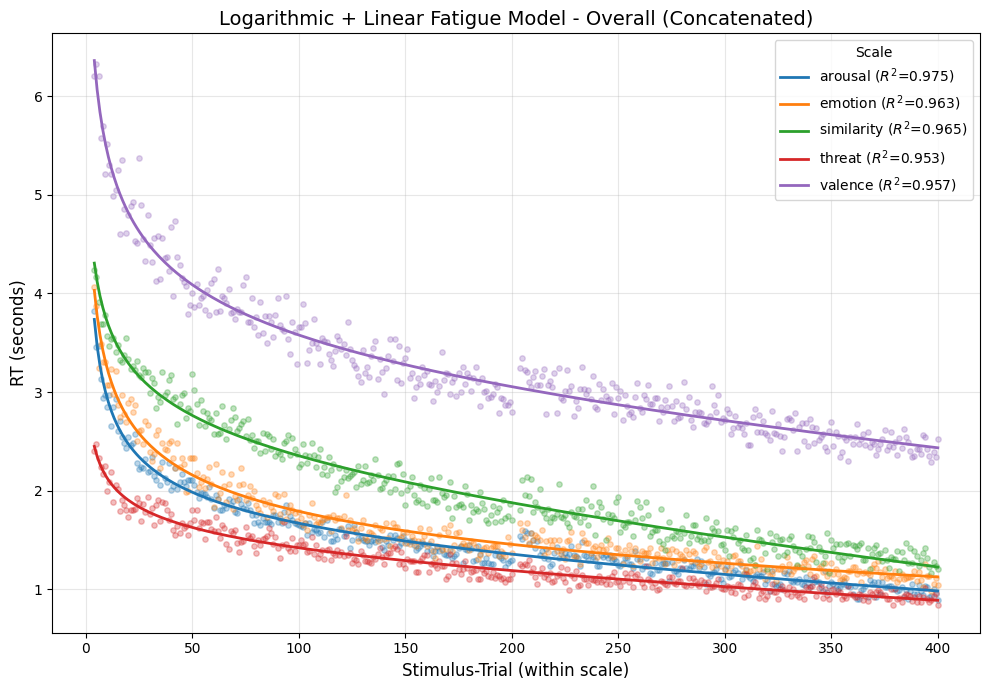

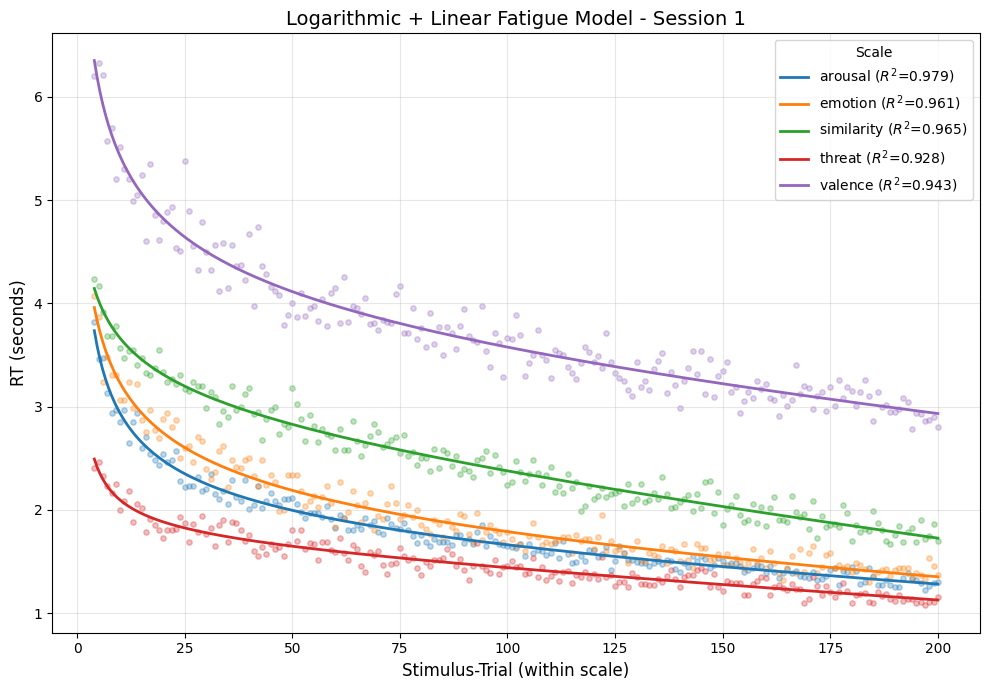

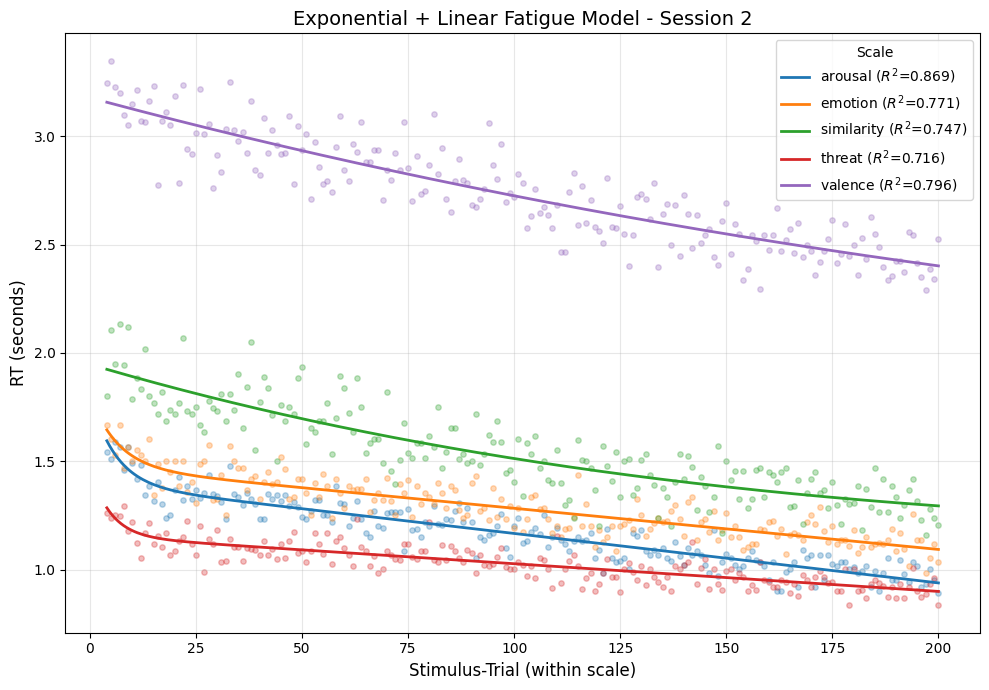


  --- Visualizing log RT ---


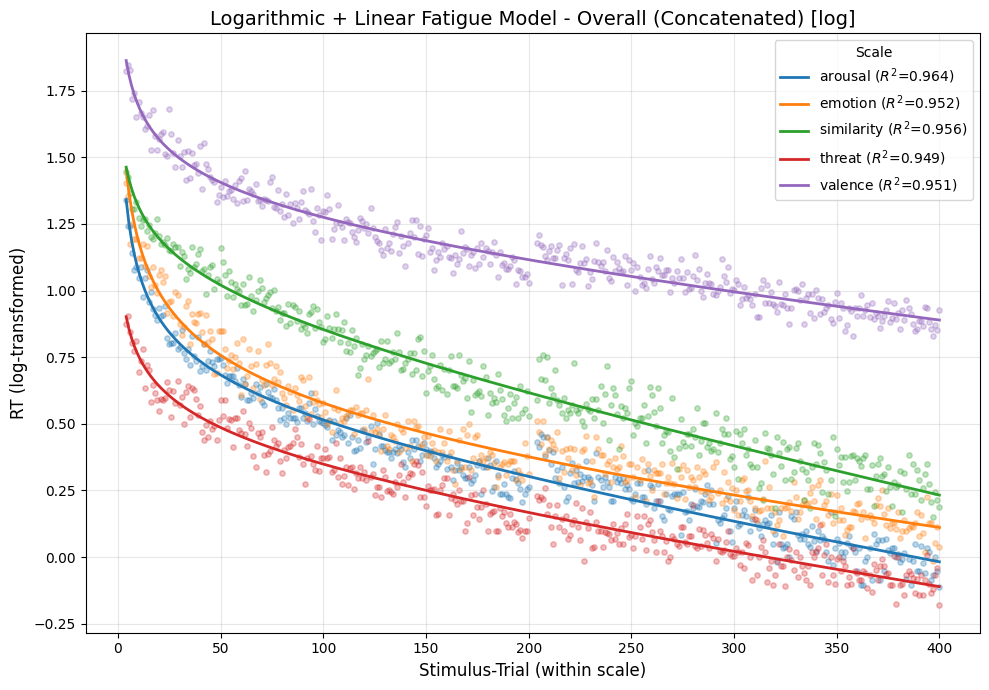

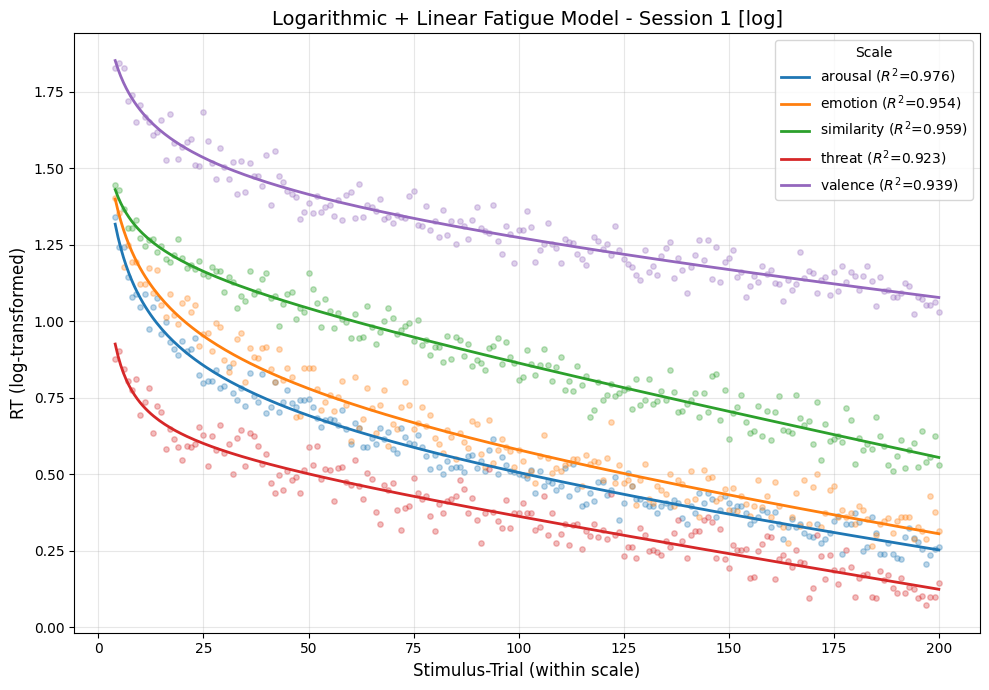

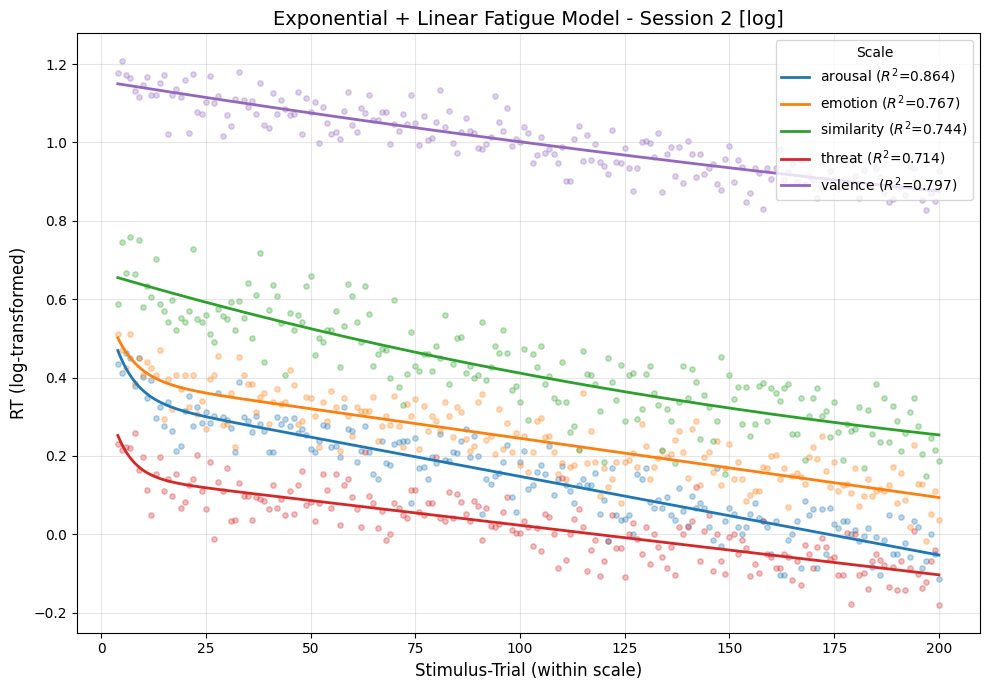


  --- Visualizing boxcox RT ---


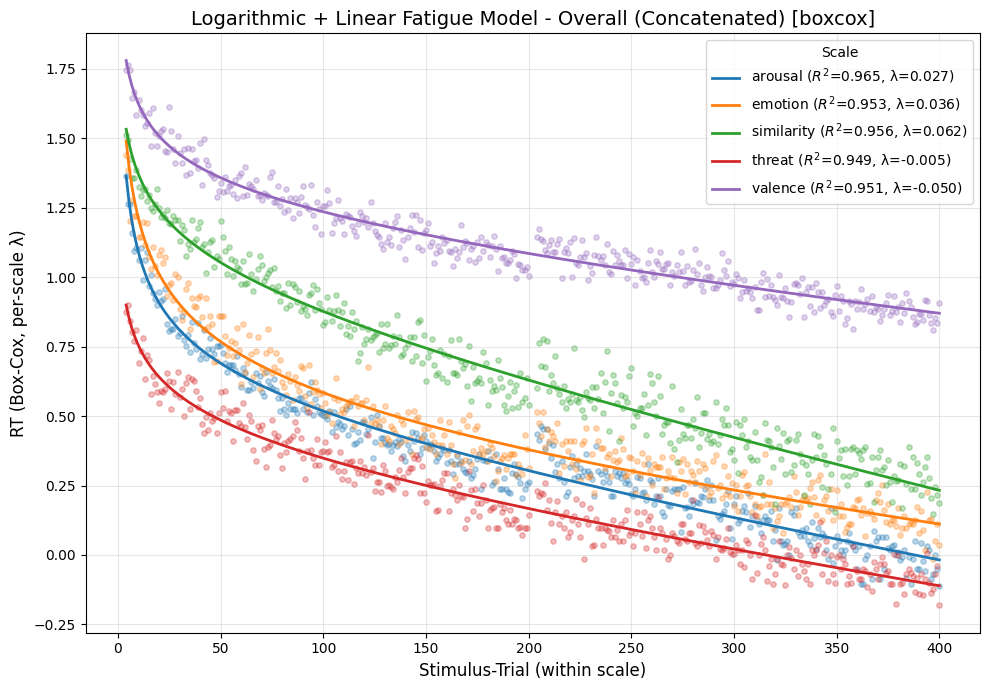

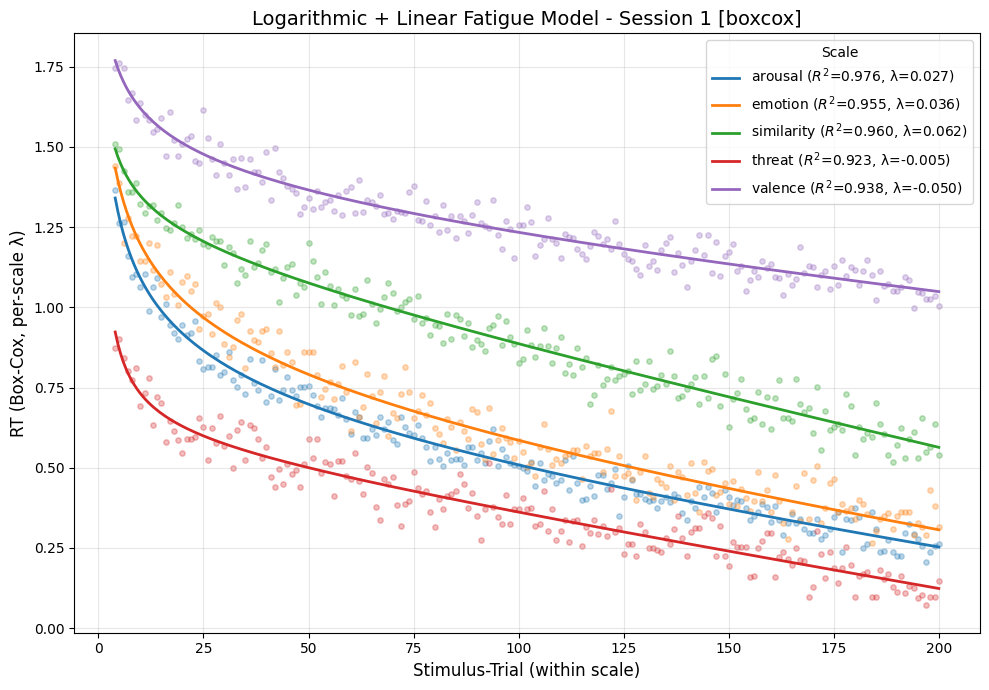

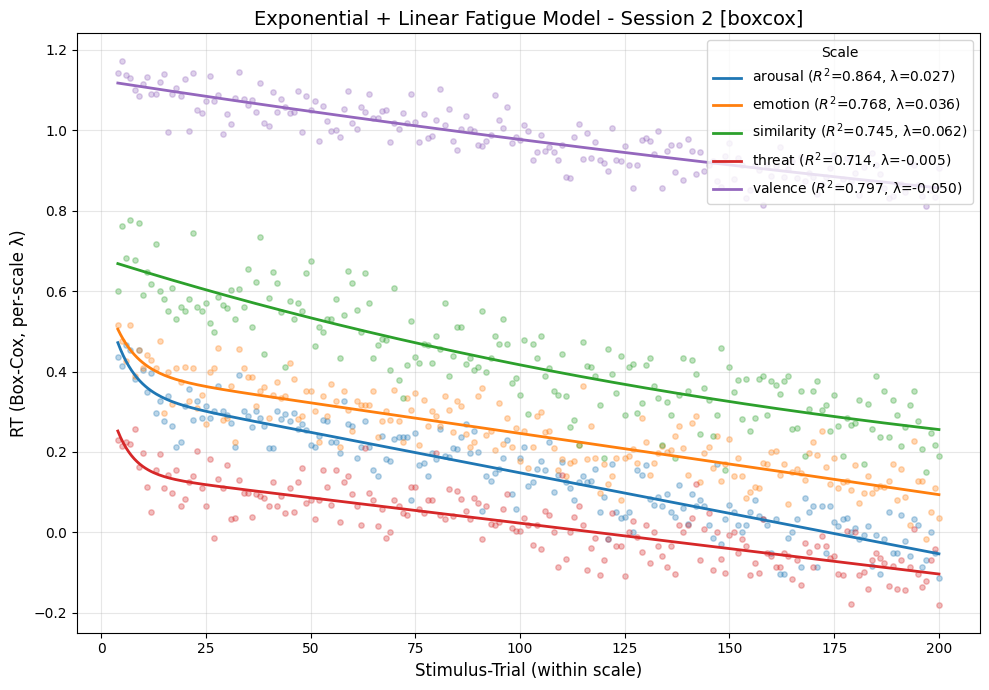


  Fitted 15 curves

Parameters:
     scale   model_name  r_squared     rmse  n_trials    rt_column          session_label     asymptote  amplitude       rate   fatigue rt_transform  bc_lambda  per_scale_transform
   arousal log_w_linfag   0.975032 0.072818       394    median_rt Overall (Concatenated) -3.852454e-01  13.346830   4.880270 -0.000986          raw   0.027319                 True
   emotion log_w_linfag   0.963446 0.096085       394    median_rt Overall (Concatenated) -2.099000e+00  32.727190  41.408979 -0.000363          raw   0.036234                 True
similarity log_w_linfag   0.964595 0.116872       394    median_rt Overall (Concatenated) -1.916000e+00  47.677342 420.100330 -0.002052          raw   0.061948                 True
    threat log_w_linfag   0.952562 0.067134       394    median_rt Overall (Concatenated) -7.996000e-01  23.831508 304.851639 -0.000872          raw  -0.004797                 True
   valence log_w_linfag   0.956751 0.151739       394    media

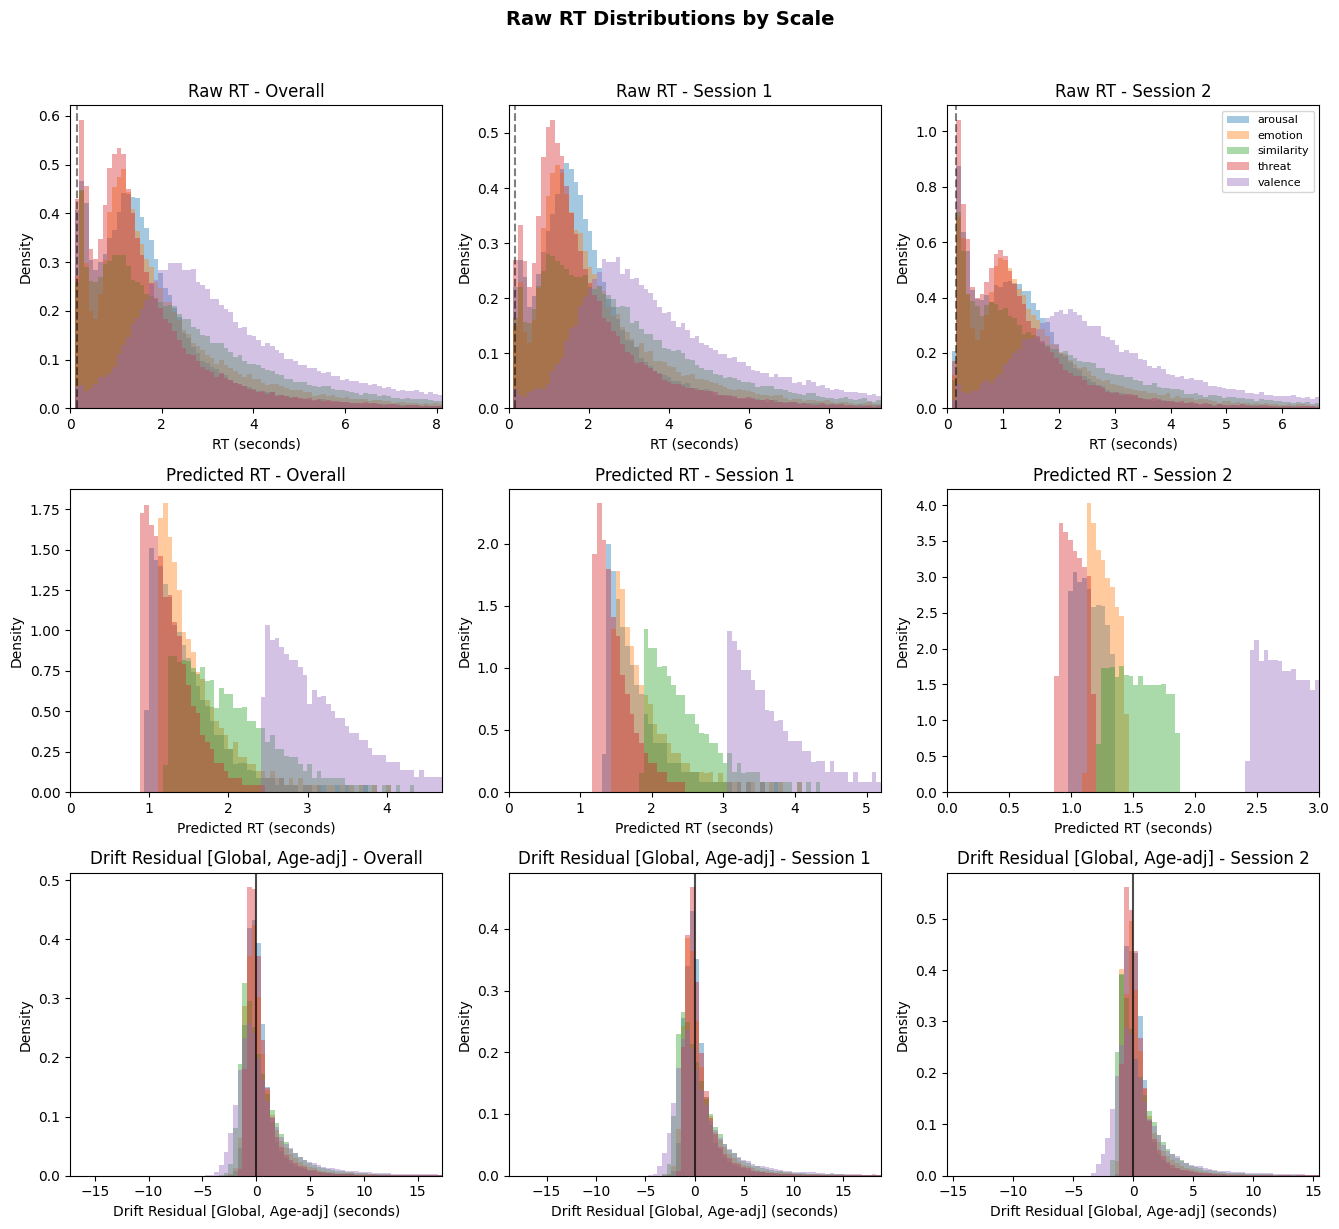

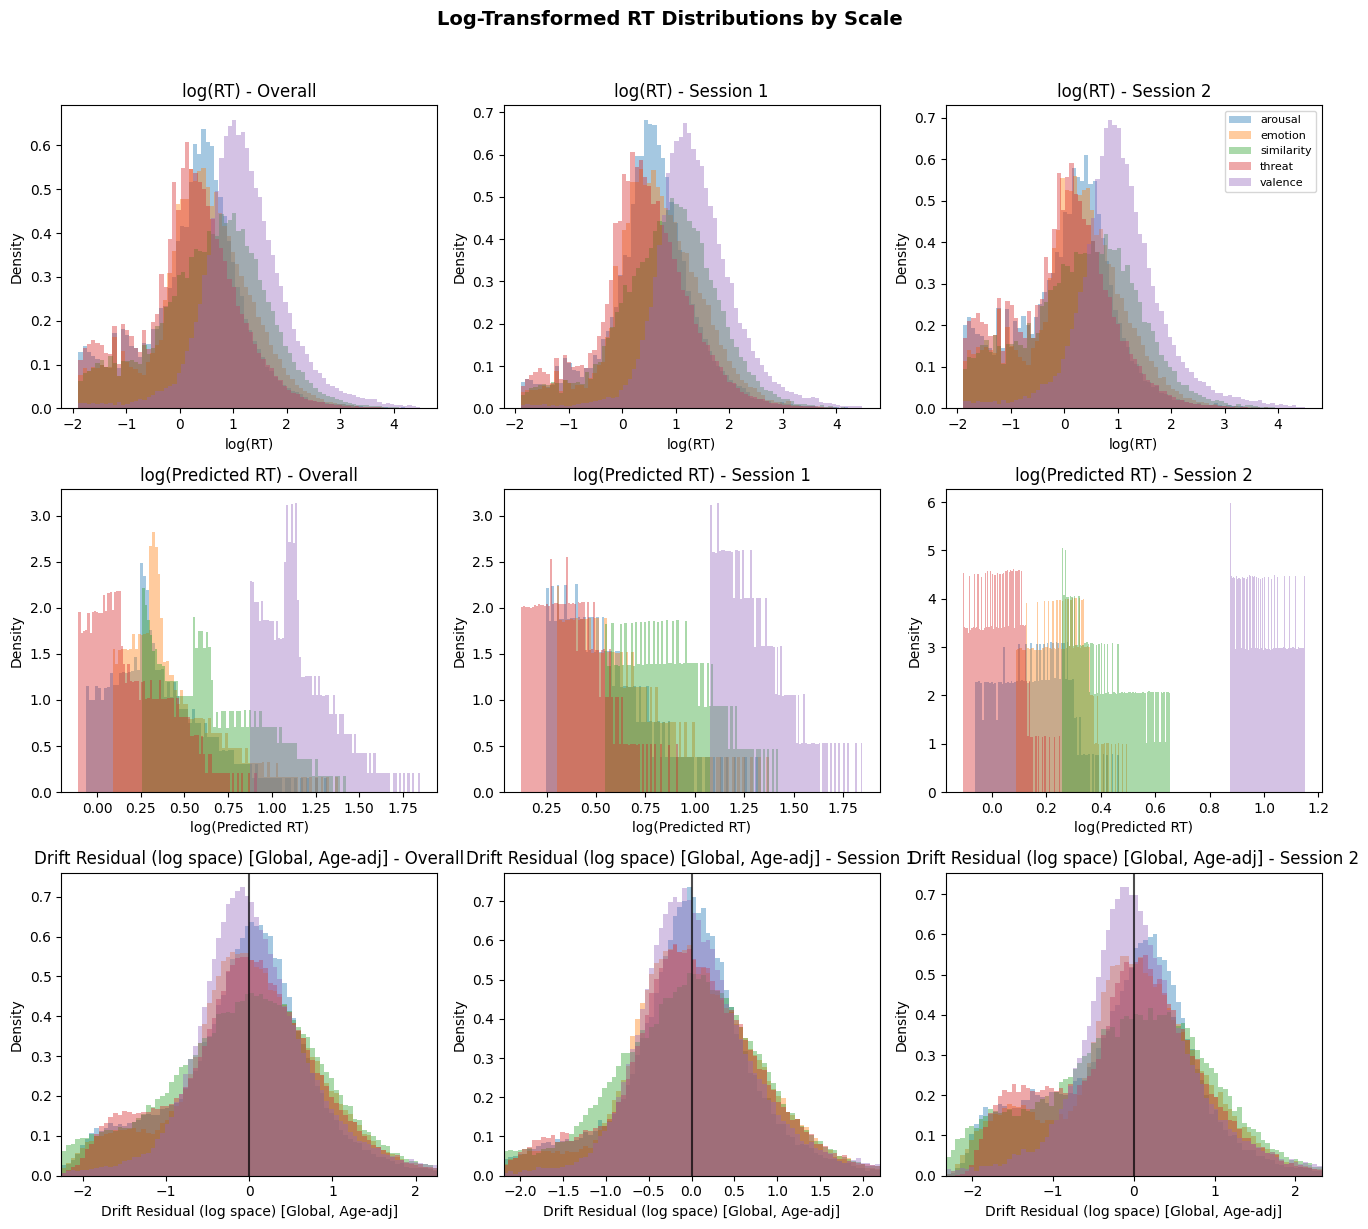

Box-Cox λ (per scale):
  arousal: λ = 0.0273
  emotion: λ = 0.0362
  similarity: λ = 0.0619
  threat: λ = -0.0048
  valence: λ = -0.0496


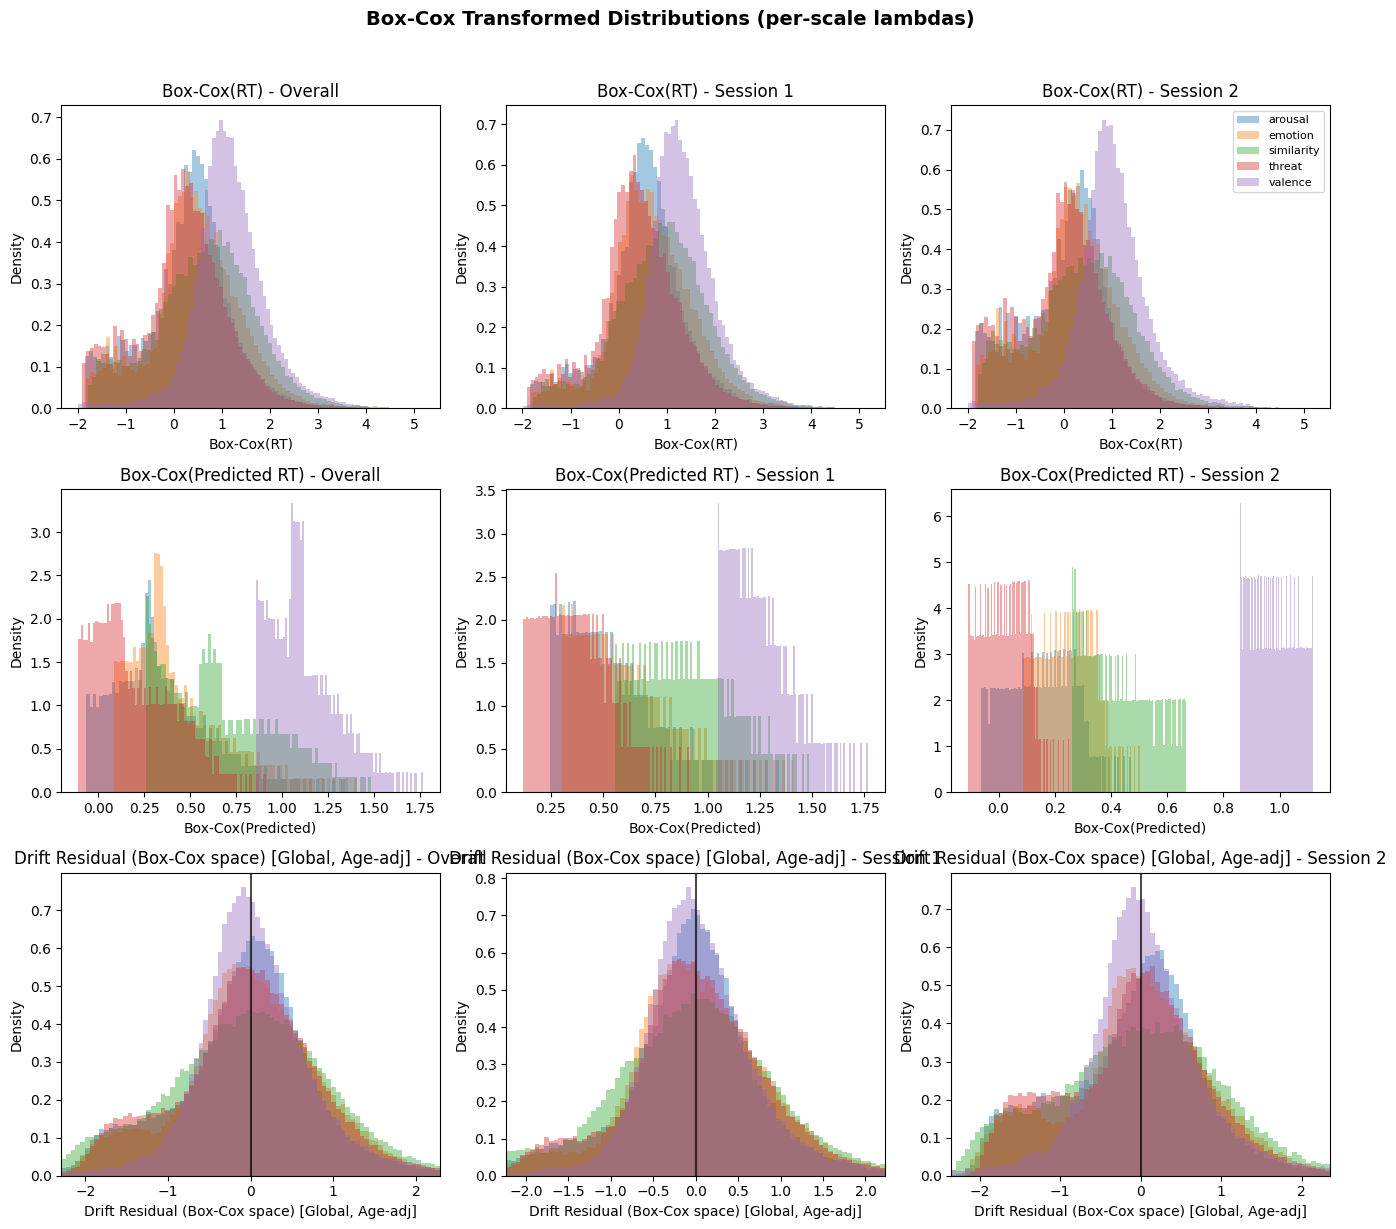

  Timestamped LVL_0 handoff -> lv0_out_20261106_180438.csv (552,281 rows, 282 participants)
  LVL_0 parameter/results JSON -> /home/sjsuss626/EMST_files/sjs_dissertation/dervatives/dynamic_qc/lvl_outs/lv0_out_20261106_180438_parameters.json


PosixPath('/home/sjsuss626/EMST_files/sjs_dissertation/dervatives/dynamic_qc/lvl_outs/lv0_out_20261106_180438_parameters.json')

In [8]:
# [cell 7]
# =============================================================================
# MODEL DEFINITION 
# =============================================================================

def model_exp_fatigue(trial: np.ndarray, asymptote: float, amplitude: float, 
                      rate: float, fatigue: float) -> np.ndarray:
    """
    Exponential decay with linear fatigue term.
    RT(t) = asymptote + amplitude * exp(-rate * t) + fatigue * t
    """
    trial = np.asarray(trial, dtype=float)
    return asymptote + amplitude * np.exp(-rate * trial) + fatigue * trial
def model_exp(trial: np.ndarray, asymptote: float, amplitude: float, 
              rate: float) -> np.ndarray:
    """
    Simple exponential decay (no fatigue term).
    RT(t) = asymptote + amplitude * exp(-rate * t)
    """
    trial = np.asarray(trial, dtype=float)
    return asymptote + amplitude * np.exp(-rate * trial)

def model_log_decay(trial: np.ndarray, asymptote: float, amplitude: float,
                    rate: float) -> np.ndarray:
    """
    Logarithmic decay.
    RT(t) = asymptote + amplitude / (log(1 + rate * (t + 1)) + epsilon)
    where epsilon = 1e-10 prevents division-by-zero, and the (t + 1) shift
    moves the singularity at t=0 outside the valid trial range so the model
    can be safely evaluated on trials below the curve-fit window
    (e.g. dropped practice trials retained for downstream use).

    Slower decay than exponential, common in learning/practice literature.
    Note: When rate*(t+1) is small, this approximates 1/(rate*(t+1)),
    giving hyperbolic-like behavior.
    """
    trial = np.asarray(trial, dtype=float)
    return asymptote + amplitude / (np.log1p(rate * (trial + 1)) + 1e-10)

def model_log_fatigue(trial: np.ndarray, asymptote: float, amplitude: float,
                      rate: float, fatigue: float) -> np.ndarray:
    """
    Logarithmic decay with linear fatigue term.
    RT(t) = asymptote + amplitude / (log(1 + rate * (t + 1)) + epsilon) + fatigue * t
    where epsilon = 1e-10 prevents division-by-zero, and the (t + 1) shift
    in the log term moves the singularity at t=0 outside the valid trial range.
    Fatigue is kept as a function of raw t (no shift), so a 0-trial baseline
    contributes 0 fatigue.

    Combines slower-than-exponential log decay with linear fatigue accumulation.
    """
    trial = np.asarray(trial, dtype=float)
    return asymptote + amplitude / (np.log1p(rate * (trial + 1)) + 1e-10) + fatigue * trial

def model_linear(trial: np.ndarray, intercept: float, slope: float) -> np.ndarray:
    """
    Simple linear decay.
    RT(t) = intercept + slope * t
    """
    trial = np.asarray(trial, dtype=float)
    return intercept + slope * trial

# =============================================================================
# DRIFT MODEL REGISTRY
# =============================================================================
# Maps model name strings to specifications for fitting, prediction, and display.
# Each entry contains:
#   function: the model callable
#   param_names: ordered parameter names (must match function signature after 'trial')
#   display_name: human-readable name for plot titles
#   p0_fn(y, x): computes initial parameter guesses from data
#   bounds_fn(y, x): computes parameter bounds from data

DRIFT_MODELS = {
    "exp_w_linfag": {
        "function": model_exp_fatigue,
        "param_names": ["asymptote", "amplitude", "rate", "fatigue"],
        "display_name": "Exponential + Linear Fatigue",
        "p0_fn": lambda y, x: [
            float(np.median(y[-20:]) if len(y) >= 20 else np.median(y)),
            max(0.01, float(np.max(y) - (np.median(y[-20:]) if len(y) >= 20 else np.median(y)))),
            0.02,
            0.001
        ],
        "bounds_fn": lambda y, x: (
            [min(0, float(np.min(y) - max(float(np.max(y) - np.min(y)), 1e-6))), 0, 0, -0.1],
            [np.inf, np.inf, np.inf, 0.1]
        ),
    },
    "exp": {
        "function": model_exp,
        "param_names": ["asymptote", "amplitude", "rate"],
        "display_name": "Exponential Decay",
        "p0_fn": lambda y, x: [
            float(np.median(y[-20:]) if len(y) >= 20 else np.median(y)),
            max(0.01, float(np.max(y) - (np.median(y[-20:]) if len(y) >= 20 else np.median(y)))),
            0.02
        ],
        "bounds_fn": lambda y, x: (
            [min(0, float(np.min(y) - max(float(np.max(y) - np.min(y)), 1e-6))), 0, 0],
            [np.inf, np.inf, np.inf]
        ),
    },
    "log": {
        "function": model_log_decay,
        "param_names": ["asymptote", "amplitude", "rate"],
        "display_name": "Logarithmic Decay",
        "p0_fn": lambda y, x: [
            float(np.median(y[-20:]) if len(y) >= 20 else np.median(y)),
            max(0.01, float(np.max(y) - (np.median(y[-20:]) if len(y) >= 20 else np.median(y)))),
            0.01
        ],
        "bounds_fn": lambda y, x: (
            [min(0, float(np.min(y) - max(float(np.max(y) - np.min(y)), 1e-6))), 0, 1e-3],
            [np.inf, np.inf, np.inf]
        ),
    },
    "log_w_linfag": {
        "function": model_log_fatigue,
        "param_names": ["asymptote", "amplitude", "rate", "fatigue"],
        "display_name": "Logarithmic + Linear Fatigue",
        "p0_fn": lambda y, x: [
            float(np.median(y[-20:]) if len(y) >= 20 else np.median(y)),
            max(0.01, float(np.max(y) - (np.median(y[-20:]) if len(y) >= 20 else np.median(y)))),
            0.01,
            0.001
        ],
        "bounds_fn": lambda y, x: (
            [min(0, float(np.min(y) - max(float(np.max(y) - np.min(y)), 1e-6))), 0, 1e-3, -0.1],
            [np.inf, np.inf, np.inf, 0.1]
        ),
    },
    "linear": {
        "function": model_linear,
        "param_names": ["intercept", "slope"],
        "display_name": "Linear Decay",
        "p0_fn": lambda y, x: [
            float(np.mean(y)),
            float((y[-1] - y[0]) / max(x[-1] - x[0], 1)) if len(y) > 1 else 0.0
        ],
        "bounds_fn": lambda y, x: (
            [-np.inf, -np.inf],
            [np.inf, np.inf]
        ),
    },
}

def _predict_from_params(trials: np.ndarray, p) -> np.ndarray:
    """
    Reconstruct predictions from a params row, dispatching to the correct model.
    
    Parameters
    ----------
    trials : array-like
        Trial indices to predict for.
    p : dict-like (Series or dict)
        Must contain 'model_name' key and all parameter values for that model.
    
    Returns
    -------
    predicted : np.ndarray
        Predicted RT values.
    """
    mname = p.get('model_name', 'exp_w_linfag')  # default when the row has no model_name
    # an unknown or corrupted model_name string is replaced by exp_w_linfag, with a warning
    if mname not in DRIFT_MODELS:
        import warnings as _w_h1
        _w_h1.warn(
            f"_predict_from_params: unknown model_name='{mname}'; using 'exp_w_linfag'",
            stacklevel=2,
        )
        mname = 'exp_w_linfag'
    spec = DRIFT_MODELS[mname]
    model_fn = spec["function"]
    param_names = spec["param_names"]
    pvals = [p[pn] for pn in param_names]
    return model_fn(np.asarray(trials, dtype=float), *pvals)

# =============================================================================
# PLOT PALETTE
# =============================================================================
# Scale colors (auto, consistent, colorblind-friendly).
# Used in fit_drift_all_scales' PLOT block (L503+) and elsewhere.
PRIMARY_SCALE_PALETTE = [
    '#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd',  # matplotlib tab10 order
    '#009E73', '#CC79A7'                                   # colour-blind-friendly extension
]

# =============================================================================
# CURVE FITTING FUNCTIONS
# =============================================================================

def add_continuous_trial_index(
    df: pd.DataFrame,
    stim_col: str = 'stim_order',
    session_col: str = 'session',
    continuous_col: str = 'continuous_stim_order'
) -> pd.DataFrame:
    """
    Add a continuous trial index that concatenates sessions sequentially.
    
    This creates a trial index where sessions are concatenated in order:
    - Session 1 trials 1-100 -> continuous index 1-100
    - Session 2 trials 1-100 -> continuous index 101-200
    - etc.
    
    This allows fitting a single drift model across the entire experiment
    as though it were one long session.
    
    Parameters
    ----------
    df : pd.DataFrame
        Input dataframe with trial data
    stim_col : str
        Column containing within-session trial index (default: 'stim_order')
    session_col : str  
        Column containing session identifier (default: 'session')
    continuous_col : str
        Name for the new continuous index column (default: 'continuous_stim_order')
        
    Returns
    -------
    pd.DataFrame
        DataFrame with new continuous_col added
    """
    df = df.copy()
    
    if session_col not in df.columns:
        # No sessions, just use stim_order directly
        df[continuous_col] = df[stim_col]
        return df
    
    # Get sessions in sorted order
    sessions = sorted(df[session_col].dropna().unique())
    
    # Calculate offset for each session based on max trial in previous sessions
    session_offsets = {}
    cumulative_offset = 0
    
    for ses in sessions:
        session_offsets[ses] = cumulative_offset
        # Get max trial in this session
        ses_max = df.loc[df[session_col] == ses, stim_col].max()
        cumulative_offset += ses_max
    
    # Apply offset to create continuous index. Vectorized: map session -> offset
    # via the dict, fillna(0) so NaN-session rows (rare) just get the raw stim_order.
    _offsets = df[session_col].map(session_offsets).fillna(0)
    df[continuous_col] = df[stim_col] + _offsets
    
    return df

def compute_trial_statistics(
    df: pd.DataFrame,
    rt_col: str = 'rt_sec',
    stim_col: str = 'stim_order',
    scale_col: str = 'scale',
    session_col: Optional[str] = 'session',
    continuous_col: Optional[str] = 'continuous_stim_order'
) -> Tuple[pd.DataFrame, Optional[pd.DataFrame]]:
    """
    Compute median RT per trial x scale (x session) for curve fitting.
    
    Returns two DataFrames:
    1. Per-session statistics (using within-session stim_order)
    2. Concatenated statistics (using continuous trial index across sessions)
    
    The concatenated stats allow fitting a single drift model that treats
    all sessions as one long experiment.
    
    Parameters
    ----------
    continuous_col : str, optional
        Column containing continuous trial index across sessions.
        If present in df, concatenated stats will be computed.
    
    Returns
    -------
    session_stats : pd.DataFrame
        Statistics with stim_order as index, includes median_rt (averaged across 
        sessions at same stim_order) and median_rt_s{N} for each session.
    concat_stats : pd.DataFrame or None
        Statistics with continuous_stim_order as index, for fitting overall
        drift model on concatenated sessions. None if continuous_col not in df.
    """
    # Per-session statistics
    session_stats = df.groupby([stim_col, scale_col])[rt_col].agg(['median', 'std', 'count']).reset_index()
    session_stats.columns = [stim_col, scale_col, 'median_rt', 'std_rt', 'n_obs']
    
    if session_col is not None and session_col in df.columns:
        for ses in sorted(df[session_col].dropna().unique()):
            ses_data = df[df[session_col] == ses]
            ses_stat = ses_data.groupby([stim_col, scale_col])[rt_col].median().reset_index()
            ses_stat.columns = [stim_col, scale_col, f'median_rt_s{ses}']
            session_stats = session_stats.merge(ses_stat, on=[stim_col, scale_col], how='left')
    
    # Concatenated statistics (for overall drift on sequential sessions)
    concat_stats = None
    if continuous_col is not None and continuous_col in df.columns:
        # Group by continuous trial index - this treats all sessions as one sequence
        concat_stats = df.groupby([continuous_col, scale_col])[rt_col].agg(['median', 'std', 'count']).reset_index()
        concat_stats.columns = [continuous_col, scale_col, 'median_rt', 'std_rt', 'n_obs']
    
    return session_stats, concat_stats

def fit_drift_all_scales(
    trial_stats: pd.DataFrame,
    rt_col: str = 'median_rt',
    stim_col: str = 'stim_order',
    label: str = 'Overall',
    n_jobs: int = 1,
    ylabel: str = 'Aggregated RT',
    model_name: str = 'exp_w_linfag',
    scale_lambdas: Optional[Dict[str, float]] = None,
    joint_fit: bool = False
) -> Tuple[List[Dict], plt.Figure]:
    """Fit drift curves to all scales and create diagnostic plot.
    
    Uses DRIFT_MODELS registry to dispatch to the correct model function,
    initial guesses, and bounds based on model_name.
    
    When joint_fit=True, fits one model to all scales simultaneously with
    shared temporal dynamics and per-scale intercept offsets.
    """
    if rt_col not in trial_stats.columns:
        print(f"Column '{rt_col}' not found. Skipping {label}.")
        return [], None
    
    if model_name not in DRIFT_MODELS:
        raise ValueError(f"Unknown drift model '{model_name}'. Options: {list(DRIFT_MODELS.keys())}")
    
    spec = DRIFT_MODELS[model_name]
    model_fn = spec["function"]
    param_names = spec["param_names"]

    scales = sorted(trial_stats['scale'].dropna().unique())

    # Pre-extract x/y per scale
    scale_xy = {}
    for scale in scales:
        sub = trial_stats[trial_stats['scale'] == scale].sort_values(stim_col).copy()
        sub = sub.dropna(subset=[rt_col])
        if sub.empty:
            continue
        x = sub[stim_col].astype(float).values
        y = sub[rt_col].astype(float).values
        scale_xy[scale] = (x, y)

    # =========================================================================
    # JOINT FIT: shared temporal dynamics + per-scale intercept offsets
    # =========================================================================
    if joint_fit and len(scale_xy) > 1:
        # IMPLICIT ASSUMPTION (joint-fit only): param_names[0] is the intercept/
        # asymptote slot. The per-scale offset returned by curve_fit is added to
        # effective_params[0] below, so a model whose first parameter is NOT the
        # intercept would silently get its offset applied to the wrong slot.
        # True for all 5 models in DRIFT_MODELS (asymptote / intercept).
        assert param_names[0] in ("asymptote", "intercept"), (
            f"Joint fit expects param_names[0] to be the intercept/asymptote slot; "
            f"got '{param_names[0]}' for model '{model_name}'."
        )
        ref_scale = scales[0]  # reference scale (alphabetically first)
        non_ref_scales = [s for s in scales if s in scale_xy and s != ref_scale]
        n_base = len(param_names)
        n_offsets = len(non_ref_scales)

        # Stack all data and build indicator matrix
        all_x, all_y, all_indicators = [], [], []
        for scale in scales:
            if scale not in scale_xy:
                continue
            x, y = scale_xy[scale]
            all_x.append(x)
            all_y.append(y)
            # One-hot indicators for non-reference scales
            indicators = np.zeros((n_offsets, len(x)))
            if scale != ref_scale and scale in non_ref_scales:
                idx = non_ref_scales.index(scale)
                indicators[idx] = 1.0
            all_indicators.append(indicators)

        X_combined = np.vstack([
            np.concatenate(all_x).reshape(1, -1),  # row 0: trial numbers
            np.hstack(all_indicators)               # rows 1..N: scale indicators
        ])
        y_combined = np.concatenate(all_y)

        # Wrapper model
        def joint_model(X, *params):
            trial = X[0]
            base_params = params[:n_base]
            offsets = params[n_base:]
            pred = model_fn(trial, *base_params)
            for k, off in enumerate(offsets):
                pred = pred + off * X[1 + k]
            return pred

        # Initial guesses and bounds
        p0_base = spec["p0_fn"](y_combined, X_combined[0])
        bounds_base = spec["bounds_fn"](y_combined, X_combined[0])
        # Ensure p0 within bounds
        for k in range(len(p0_base)):
            lo = bounds_base[0][k] if np.isfinite(bounds_base[0][k]) else -1e10
            hi = bounds_base[1][k] if np.isfinite(bounds_base[1][k]) else 1e10
            p0_base[k] = max(lo, min(float(p0_base[k]), hi))

        y_range = float(np.ptp(y_combined)) + 0.1
        p0_offsets = [0.0] * n_offsets
        bounds_lo_offsets = [-y_range * 3] * n_offsets
        bounds_hi_offsets = [y_range * 3] * n_offsets

        p0_all = p0_base + p0_offsets
        bounds_all = (
            list(bounds_base[0]) + bounds_lo_offsets,
            list(bounds_base[1]) + bounds_hi_offsets
        )

        all_params = []
        try:
            popt, _ = curve_fit(joint_model, X_combined, y_combined,
                                p0=p0_all, bounds=bounds_all, maxfev=50000)
            base_fitted = popt[:n_base]
            offset_fitted = popt[n_base:]

            # Decompose into per-scale effective params
            for scale in scales:
                if scale not in scale_xy:
                    continue
                x, y = scale_xy[scale]

                # Compute effective intercept
                effective_params = list(base_fitted)
                if scale != ref_scale and scale in non_ref_scales:
                    idx = non_ref_scales.index(scale)
                    effective_params[0] = float(effective_params[0]) + float(offset_fitted[idx])

                # Predict for this scale
                y_pred = model_fn(x, *effective_params)
                ss_res = float(np.sum((y - y_pred) ** 2))
                ss_tot = float(np.sum((y - np.mean(y)) ** 2))
                r_squared = 1 - (ss_res / ss_tot) if ss_tot > 0 else 0.0
                rmse = float(np.sqrt(np.mean((y - y_pred) ** 2)))

                result = {
                    'scale': scale,
                    'model_name': model_name,
                    'r_squared': float(r_squared),
                    'rmse': float(rmse),
                    'n_trials': int(len(x)),
                    'rt_column': rt_col,
                    'session_label': label,
                    'joint_fit': True,
                }
                for pname, pval in zip(param_names, effective_params):
                    result[pname] = float(pval)
                all_params.append(result)

        except RuntimeError as e:
            import warnings as _w_jf
            _w_jf.warn(
                f"fit_drift_all_scales: joint fit failed for {label} "
                f"(model='{model_name}'): {e}; returning empty params list. "
                "Consider switching to independent fit (joint_fit=False) or "
                "checking for collinear / pathological per-scale data.",
                stacklevel=2,
            )
            print(f"  Joint fit failed for {label}: {e}")
            # the joint fit leaves no results

    # =========================================================================
    # INDEPENDENT FIT: each scale fitted separately
    # =========================================================================
    else:
        def _fit_one(scale: str, x: np.ndarray, y: np.ndarray) -> Optional[Dict]:
            if len(x) < 5:
                return None
            p0 = spec["p0_fn"](y, x)
            bounds = spec["bounds_fn"](y, x)
            for k in range(len(p0)):
                lo = bounds[0][k] if np.isfinite(bounds[0][k]) else -1e10
                hi = bounds[1][k] if np.isfinite(bounds[1][k]) else 1e10
                p0[k] = max(lo, min(float(p0[k]), hi))
            try:
                popt, _ = curve_fit(model_fn, x, y, p0=p0, bounds=bounds, maxfev=20000)
                y_pred = model_fn(x, *popt)
                ss_res = float(np.sum((y - y_pred) ** 2))
                ss_tot = float(np.sum((y - np.mean(y)) ** 2))
                r_squared = 1 - (ss_res / ss_tot) if ss_tot > 0 else 0.0
                rmse = float(np.sqrt(np.mean((y - y_pred) ** 2)))
                result = {
                    'scale': scale,
                    'model_name': model_name,
                    'r_squared': float(r_squared),
                    'rmse': float(rmse),
                    'n_trials': int(len(x)),
                    'rt_column': rt_col,
                    'session_label': label,
                }
                for pname, pval in zip(param_names, popt):
                    result[pname] = float(pval)
                return result
            except RuntimeError:
                return None

        items = [(s, *scale_xy[s]) for s in scale_xy.keys()]
        if n_jobs is None:
            n_jobs = 1
        if n_jobs == 1 or len(items) <= 1:
            fit_results = [_fit_one(s, x, y) for (s, x, y) in items]
        else:
            fit_results = Parallel(n_jobs=n_jobs)(
                delayed(_fit_one)(s, x, y) for (s, x, y) in items
            )
        all_params = [p for p in fit_results if p is not None]

    # =========================================================================
    # PLOT
    # =========================================================================
    fig, ax = plt.subplots(figsize=(10, 7))
    # Use the project-wide colorblind-friendly palette (declared at L180+) so
    # scale colors stay consistent across cell 7's drift plots and downstream
    # diagnostic figures.
    colors = [PRIMARY_SCALE_PALETTE[i % len(PRIMARY_SCALE_PALETTE)]
              for i in range(max(1, len(scales)))]

    for scale, color in zip(scales, colors):
        if scale not in scale_xy:
            continue
        x, y = scale_xy[scale]
        ax.scatter(x, y, alpha=0.3, color=color, s=15)

        params = next((p for p in all_params if p["scale"] == scale), None)
        if params is not None:
            x_fit = np.linspace(float(x.min()), float(x.max()), 300)
            pvals = [params[pn] for pn in param_names]
            y_fit = model_fn(x_fit, *pvals)
            # Build legend label
            lbl = f"{scale} ($R^2$={params['r_squared']:.3f}"
            if scale_lambdas and scale in scale_lambdas:
                lbl += f", λ={scale_lambdas[scale]:.3f}"
            lbl += ")"
            ax.plot(x_fit, y_fit, color=color, linewidth=2, label=lbl)
        else:
            ax.plot(x, y, '--', color=color, alpha=0.5, label=f"{scale} (no fit)")

    ax.set_xlabel('Stimulus-Trial (within scale)', fontsize=12)
    ax.set_ylabel(ylabel, fontsize=12)
    title_suffix = ' [joint]' if joint_fit and len(scale_xy) > 1 else ''
    ax.set_title(f'{spec["display_name"]} Model - {label}{title_suffix}', fontsize=14)
    ax.legend(title='Scale', loc='upper right', fontsize=10)
    ax.grid(True, alpha=0.3)
    plt.tight_layout()

    return all_params, fig
def compute_drift_residuals(
    df: pd.DataFrame,
    decay_params: pd.DataFrame,
    rt_col: str = 'rt_sec',
    stim_col: str = 'stim_order',
    scale_col: str = 'scale',
    session_col: Optional[str] = 'session',
    rt_transform: str = 'raw',
    bc_lambda: Optional[float] = None,
    continuous_col: Optional[str] = 'continuous_stim_order',
    use_overall_only: bool = False,  # When True, always use Overall (Concatenated) params
    scale_lambdas: Optional[Dict[str, float]] = None  # Per-scale Box-Cox lambdas
) -> pd.DataFrame:
    """
    Compute drift-corrected residuals for each observation.
    
    IMPORTANT: rt_col should be the TRANSFORMED RT column if transform was applied.
    The drift model was fit on transformed RT, so residuals are naturally in the
    transformed space (no shifting required!).
    
    When using "Overall (Concatenated)" parameters, the continuous trial index is used
    to compute predictions, treating all sessions as one long experiment.
    
    Parameters
    ----------
    rt_col : str
        The RT column to use. If transform was applied, this should be 'rt_transformed'.
        If raw, this should be 'rt_sec'.
    rt_transform : str
        What transform was used ('raw', 'log', 'boxcox'). Used for labeling.
    bc_lambda : float, optional
        Box-Cox lambda if used (stored for reference).
    continuous_col : str, optional
        Column containing continuous trial index across sessions.
        Used when applying "Overall (Concatenated)" parameters.
    
    Returns
    -------
    df : pd.DataFrame
        DataFrame with predicted_rt, drift_residual, drift_residual_abs columns.
        Also includes diagnostic columns (log_rt, bc_rt, etc.) for plotting.

    Notes
    -----
    Sign convention: drift_residual = observed - predicted, in whichever space
    rt_col is provided (raw, log, or Box-Cox). Because observed and predicted
    live in the same space, the sign is consistent across transforms:
    a *positive* residual means the participant was slower than the
    drift-predicted RT (attentive-leaning) and a *negative* residual means
    faster (inattentive-leaning). Downstream block detection that treats
    "slower-than-drift" as attentive should look for *positive* residuals 
    directly without re-orienting across transforms.
    """
    df = df.copy()
    df['predicted_rt'] = np.nan
    df['drift_residual'] = np.nan
    
    has_session_params = 'session_label' in decay_params.columns
    
    # Check if we have Overall (Concatenated) parameters
    has_concat_overall = has_session_params and any(
        'Concatenated' in str(label) for label in decay_params['session_label'].unique()
    )
    
    for scale in df[scale_col].unique():
        scale_mask = df[scale_col] == scale
        
        if has_session_params and session_col is not None and session_col in df.columns:
            for ses in df[session_col].unique():
                ses_mask = scale_mask & (df[session_col] == ses)
                # Per-session fits are labelled "Session N", with " [<transform>]" appended for every
                # transform other than the fitting reference (e.g. "Session 1 [log]"): match on N.
                _ses_num = decay_params['session_label'].astype(str).str.extract(r"^Session (\d+)")[0]
                params_row = decay_params[
                    (decay_params['scale'] == scale) &
                    (_ses_num == str(int(ses)))
                ]
                if not use_overall_only and len(params_row) != 1:
                    raise ValueError(
                        f"compute_drift_residuals: {len(params_row)} per-session drift fits for scale "
                        f"{scale!r}, session {ses} (labels: "
                        f"{sorted(decay_params['session_label'].astype(str).unique())})")
                
                if not use_overall_only:
                    # Use session-specific parameters with within-session stim_order
                    p = params_row.iloc[0]
                    trials = df.loc[ses_mask, stim_col].values
                    predicted = _predict_from_params(trials, p)
                    df.loc[ses_mask, 'predicted_rt'] = predicted
                else:
                    # use_overall_only: the Overall (Concatenated) parameters
                    # Find the Overall parameters (with or without "Concatenated" suffix)
                    params_row = decay_params[
                        (decay_params['scale'] == scale) & 
                        (decay_params['session_label'].str.contains('Overall', case=False, na=False))
                    ]
                    
                    if params_row.empty:
                        continue
                    
                    p = params_row.iloc[0]
                    
                    # IMPORTANT: For Overall (Concatenated), use continuous trial index
                    if has_concat_overall and continuous_col is not None and continuous_col in df.columns:
                        trials = df.loc[ses_mask, continuous_col].values
                    else:
                        # no continuous trial index: use stim_order
                        trials = df.loc[ses_mask, stim_col].values
                    
                    predicted = _predict_from_params(trials, p)
                    df.loc[ses_mask, 'predicted_rt'] = predicted
        else:
            # No session-specific parameters, use the single Overall parameters
            params_row = decay_params[decay_params['scale'] == scale]
            if params_row.empty:
                continue
            
            p = params_row.iloc[0]
            
            # Use continuous index if available and this is concatenated fit
            if has_concat_overall and continuous_col is not None and continuous_col in df.columns:
                trials = df.loc[scale_mask, continuous_col].values
            else:
                trials = df.loc[scale_mask, stim_col].values
            
            predicted = _predict_from_params(trials, p)
            df.loc[scale_mask, 'predicted_rt'] = predicted
    
    # Compute residual in whatever space we're in (raw or transformed)
    # Since drift model was fit on transformed RT, this is the correct residual
    df['drift_residual'] = df[rt_col] - df['predicted_rt']
    df['drift_residual_abs'] = np.abs(df['drift_residual'])
    
    # Store metadata about the transform used
    df['rt_transform'] = rt_transform
    if scale_lambdas:
        df['bc_lambda'] = df['scale'].map(scale_lambdas)
    elif bc_lambda is not None:
        df['bc_lambda'] = bc_lambda
    
    # For convenience, also store which column was used for fitting
    df['rt_col_used'] = rt_col
    
    # -------------------------------------------------------------------------
    # Diagnostic columns for plotting (these are NOT used for block detection)
    # -------------------------------------------------------------------------
    # =========================================================================
    # -------------------------------------------------------------------------
    # `predicted_rt` is already in the fitting space, so applying np.log() or the
    # Box-Cox formula to it directly would double-transform (log(log(RT))).
    # Everything routes through a temporary "raw hub" (`pred_sec`) instead.
    # We identify the active fitting space and safely INVERSE-transform the 
    # predictions back to raw seconds. All downstream diagnostic columns are 
    # then generated uniformly from this `pred_sec` baseline. This guarantees 
    # every diagnostic plot represents exactly one level of transformation.
    # =========================================================================


    valid_pred = df['predicted_rt'].notna()
    
    pred_sec = pd.Series(np.nan, index=df.index, dtype=float)
    
    if rt_transform == 'raw':
        pred_sec.loc[valid_pred] = df.loc[valid_pred, 'predicted_rt']
    elif rt_transform == 'log':
        pred_sec.loc[valid_pred] = np.exp(df.loc[valid_pred, 'predicted_rt'])
    elif rt_transform == 'boxcox':
        # Inverse Box-Cox to get back to raw seconds
        if scale_lambdas:
            for sc, lam in scale_lambdas.items():
                sc_pred = valid_pred & (df['scale'] == sc)
                if abs(lam) < 1e-10:
                    pred_sec.loc[sc_pred] = np.exp(df.loc[sc_pred, 'predicted_rt'])
                else:
                    pred_sec.loc[sc_pred] = (df.loc[sc_pred, 'predicted_rt'] * lam + 1) ** (1 / lam)
        elif bc_lambda is not None:
            if abs(bc_lambda) < 1e-10:
                pred_sec.loc[valid_pred] = np.exp(df.loc[valid_pred, 'predicted_rt'])
            else:
                pred_sec.loc[valid_pred] = (df.loc[valid_pred, 'predicted_rt'] * bc_lambda + 1) ** (1 / bc_lambda)

    # 2. Now compute diagnostic columns from the RAW temporary series (or copy if it's native)
    valid_rt = df['rt_sec'].notna() & (df['rt_sec'] > 0)
    
    valid_pred_sec = pred_sec.notna() & (pred_sec > 0)
    
    # Log diagnostics
    df['log_rt'] = np.nan
    df['log_predicted'] = np.nan
    df.loc[valid_rt, 'log_rt'] = np.log(df.loc[valid_rt, 'rt_sec'])
    
    if rt_transform == 'log':
        df.loc[valid_pred, 'log_predicted'] = df.loc[valid_pred, 'predicted_rt'] # Already log
    else:
        df.loc[valid_pred_sec, 'log_predicted'] = np.log(pred_sec.loc[valid_pred_sec])

    # Box-Cox diagnostics
    if scale_lambdas or bc_lambda is not None:
        df['bc_rt'] = np.nan
        df['bc_predicted'] = np.nan
        
        if rt_transform == 'boxcox':
             df.loc[valid_pred, 'bc_predicted'] = df.loc[valid_pred, 'predicted_rt'] # Already Box-Cox
             
        # Compute bc_rt and remaining bc_predicted (if model wasn't fit in boxcox space)
        if scale_lambdas:
            for sc, lam in scale_lambdas.items():
                sc_rt = valid_rt & (df['scale'] == sc)
                
                sc_pred = valid_pred_sec & (df['scale'] == sc) & (rt_transform != 'boxcox')
                
                if abs(lam) < 1e-10:
                    df.loc[sc_rt, 'bc_rt'] = np.log(df.loc[sc_rt, 'rt_sec'])
                    
                    if rt_transform != 'boxcox': 
                        df.loc[sc_pred, 'bc_predicted'] = np.log(pred_sec.loc[sc_pred])
                else:
                    df.loc[sc_rt, 'bc_rt'] = (df.loc[sc_rt, 'rt_sec'] ** lam - 1) / lam
                    
                    if rt_transform != 'boxcox': 
                        df.loc[sc_pred, 'bc_predicted'] = (pred_sec.loc[sc_pred] ** lam - 1) / lam
        elif bc_lambda is not None:
            if abs(bc_lambda) < 1e-10:
                df.loc[valid_rt, 'bc_rt'] = np.log(df.loc[valid_rt, 'rt_sec'])
                
                if rt_transform != 'boxcox': 
                    df.loc[valid_pred_sec, 'bc_predicted'] = np.log(pred_sec.loc[valid_pred_sec])
            else:
                df.loc[valid_rt, 'bc_rt'] = (df.loc[valid_rt, 'rt_sec'] ** bc_lambda - 1) / bc_lambda
                
                if rt_transform != 'boxcox': 
                    df.loc[valid_pred_sec, 'bc_predicted'] = (pred_sec.loc[valid_pred_sec] ** bc_lambda - 1) / bc_lambda
        
        df['bc_residual'] = df['bc_rt'] - df['bc_predicted']
    return df

def fit_drift_and_compute_residuals(
    clean_df: pd.DataFrame,
    full_df: Optional[pd.DataFrame] = None,
    rt_col: str = 'rt_sec',
    stim_col: str = 'stim_order',
    scale_col: str = 'scale',
    session_col: Optional[str] = 'session',
    id_col: str = 'id',
    fit_by_session: bool = True,
    show_plots: bool = True,
    n_jobs: int = 1,
    # Transformation parameters
    rt_transform: str = 'raw',
    boxcox_lambda: Optional[float] = None,
    # Visualization parameters
    vis_drift_residuals: Optional[List[str]] = None,
    use_overall_only: bool = False,  # When True, residuals use only Overall (Concatenated) params
    # Model selection parameters
    drift_model_overall: str = 'exp_w_linfag',  # Model for concatenated overall fit
    drift_model_per_ses: Union[str, List[str]] = 'exp_w_linfag',  # Model per session
    scale_lambdas: Optional[Dict[str, float]] = None,  # Per-scale Box-Cox lambdas (None = pooled)
    joint_scale_fit: bool = False  # True = shared dynamics + per-scale offsets
) -> Tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame, Dict[str, plt.Figure], Optional[float], Dict[str, pd.DataFrame]]:
    """
    Main pipeline: fit exp_fatigue curves and compute drift residuals.
    
    IMPORTANT: When rt_transform != 'raw', the drift model is fit on TRANSFORMED RT.
    This is the correct approach - transform first, then fit, then residuals are
    naturally in the transformed space (no need for shifting).
    
    Parameters
    ----------
    rt_transform : str
        'raw': Fit on raw RT
        'log': Transform RT with log first, then fit
        'boxcox': Transform RT with Box-Cox first, then fit
    boxcox_lambda : float, optional
        Lambda for Box-Cox. None = estimate from data.
    
    Returns
    -------
    full_with_residuals : pd.DataFrame
    clean_with_residuals : pd.DataFrame  
    param_df : pd.DataFrame
    figures : dict
    lambda_used : float or None
        Box-Cox lambda if used (for downstream consistency)
    """
    # Writes no files: param_df is returned (and recorded in the LVL_0 run log), and the
    # figures are saved by plt.show() when save_figures is on.
    print("=" * 70)
    print("EXP_FATIGUE DRIFT MODEL PIPELINE")
    print("=" * 70)
    print(f"Clean data (for fitting): {len(clean_df):,} observations")
    if full_df is not None:
        print(f"Full data (for residuals): {len(full_df):,} observations")
    print(f"Participants: {clean_df[id_col].nunique()}")
    print(f"Scales: {sorted(clean_df[scale_col].unique())}")
    print(f"RT Transform: {rt_transform}")
    
    # Validate and print drift model settings
    if drift_model_overall not in DRIFT_MODELS and drift_model_overall != 'auto':
        raise ValueError(f"Unknown drift model '{drift_model_overall}'. Options: {list(DRIFT_MODELS.keys())}")
    valid_models = set(DRIFT_MODELS.keys()) | {'auto'}
    if isinstance(drift_model_per_ses, str):
        if drift_model_per_ses not in valid_models:
            raise ValueError(f"Unknown drift model '{drift_model_per_ses}'. Options: {sorted(valid_models)}")
    elif isinstance(drift_model_per_ses, list):
        for m in drift_model_per_ses:
            if m not in valid_models:
                raise ValueError(f"Unknown drift model '{m}'. Options: {sorted(valid_models)}")
    
    if not fit_by_session:
        print(f"Drift Model (Overall): {drift_model_overall}" + (f" - {DRIFT_MODELS[drift_model_overall]['display_name']}" if drift_model_overall in DRIFT_MODELS else ''))
    else:
        print(f"Drift Model (Per-Session): {drift_model_per_ses}")
    
    # Step 0: Select RT column based on transform setting
    # Transforms are pre-computed (log_rt, bc_rt exist in data)
    lambda_used = boxcox_lambda
    
    if rt_transform == 'raw':
        fitting_col = rt_col
        print(f"\n[0/4] Using raw RT ({rt_col})")
    elif rt_transform == 'log':
        fitting_col = 'log_rt'
        if fitting_col not in clean_df.columns:
            raise ValueError(f"log_rt column not found. Compute transformations first.")
        print(f"\n[0/4] Using pre-computed log transform (log_rt)")
    elif rt_transform == 'boxcox':
        fitting_col = 'bc_rt'
        if fitting_col not in clean_df.columns:
            raise ValueError(f"bc_rt column not found. Compute transformations first.")
        if scale_lambdas:
            print(f"\n[0/4] Using pre-computed Box-Cox transform (bc_rt, per-scale lambdas)")
        else:
            print(f"\n[0/4] Using pre-computed Box-Cox transform (bc_rt, λ={boxcox_lambda:.4f})")
    else:
        raise ValueError(f"Unknown rt_transform: {rt_transform}")
    
    # Store rt_transformed as alias for the selected column
    clean_df['rt_transformed'] = clean_df[fitting_col]
    if full_df is not None:
        full_df['rt_transformed'] = full_df[fitting_col]
    
    # Create continuous trial index for concatenated session modeling
    continuous_col = 'continuous_stim_order'
    clean_df = add_continuous_trial_index(clean_df, stim_col, session_col, continuous_col)
    if full_df is not None:
        full_df = add_continuous_trial_index(full_df, stim_col, session_col, continuous_col)
    print(f"  Added {continuous_col} for concatenated session drift modeling")
    
    # Step 1: Compute trial statistics from clean data (using transformed RT for fitting)
    print(f"\n[1/4] Computing trial statistics on {fitting_col}...")
    session_stats, concat_stats = compute_trial_statistics(clean_df, fitting_col, stim_col, scale_col, session_col, continuous_col)
    
    # Resolve 'auto' models: try all models, pick best mean R² per session
    if fit_by_session and session_col and session_col in clean_df.columns:
        _needs_auto = False
        if isinstance(drift_model_per_ses, str) and drift_model_per_ses == 'auto':
            _needs_auto = True
        elif isinstance(drift_model_per_ses, list) and 'auto' in drift_model_per_ses:
            _needs_auto = True
        
        if _needs_auto:
            sessions = sorted(clean_df[session_col].dropna().unique())
            resolved_models = []
            for idx, ses in enumerate(sessions):
                if isinstance(drift_model_per_ses, list):
                    ses_model = drift_model_per_ses[idx] if idx < len(drift_model_per_ses) else drift_model_per_ses[-1]
                else:
                    ses_model = drift_model_per_ses
                
                if ses_model != 'auto':
                    resolved_models.append(ses_model)
                    continue
                
                # Try all models for this session
                rt_col_ses = f'median_rt_s{ses}'
                if rt_col_ses not in session_stats.columns:
                    resolved_models.append('exp_w_linfag')  # no median RT for this session: the default model
                    continue
                
                best_model, best_r2 = 'exp_w_linfag', -np.inf
                print(f"  Auto-selecting model for Session {ses}:")
                for candidate in DRIFT_MODELS:
                    try:
                        cand_params, _ = fit_drift_all_scales(
                            session_stats, rt_col_ses, stim_col,
                            f'_auto_S{ses}', n_jobs=n_jobs, ylabel='',
                            model_name=candidate
                        )
                        if cand_params:
                            mean_r2 = np.mean([p['r_squared'] for p in cand_params])
                            print(f"    {candidate:20s}  mean R² = {mean_r2:.4f}")
                            if mean_r2 > best_r2:
                                best_r2 = mean_r2
                                best_model = candidate
                    except Exception:
                        pass
                    plt.close('all')  # close auto-selection plots
                
                resolved_models.append(best_model)
                print(f"    -> Selected: {best_model} (mean R² = {best_r2:.4f})")
            
            drift_model_per_ses = resolved_models
            print(f"  Resolved per-session models: {drift_model_per_ses}")
    
    # Resolve 'auto' for overall model: try all models on concat stats, pick best mean R²
    if drift_model_overall == 'auto':
        _stats_for_auto = concat_stats if concat_stats is not None else session_stats
        _rt_col_auto = 'median_rt' if concat_stats is not None else 'median_rt'
        _stim_col_auto = continuous_col if concat_stats is not None else stim_col
        best_model, best_r2 = 'exp_w_linfag', -np.inf
        print(f"  Auto-selecting model for Overall:")
        for candidate in DRIFT_MODELS:
            try:
                cand_params, _ = fit_drift_all_scales(
                    _stats_for_auto, _rt_col_auto, _stim_col_auto,
                    '_auto_Overall', n_jobs=n_jobs, ylabel='',
                    model_name=candidate
                )
                if cand_params:
                    mean_r2 = np.mean([p['r_squared'] for p in cand_params])
                    print(f"    {candidate:20s}  mean R² = {mean_r2:.4f}")
                    if mean_r2 > best_r2:
                        best_r2 = mean_r2
                        best_model = candidate
            except Exception:
                pass
            plt.close('all')
        drift_model_overall = best_model
        print(f"    -> Selected: {drift_model_overall} (mean R² = {best_r2:.4f})")
    
    # Step 2: Fit decay curves and visualize
    # Fitting uses the configured rt_transform; visualization can show multiple RT types
    print("\n[2/4] Fitting exp_fatigue curves...")
    all_params = []
    all_params_by_type = {}   # {'raw'|'log'|'boxcox': [param dicts]} -- every fitted
                               # transform is kept, not just the fitting one, so the
                               # caller can compute residuals for all three RT spaces.
    figures = {}
    
    # Get visualization RT types from config (default to just the fitting transform)
    vis_rt_types = vis_drift_residuals if vis_drift_residuals else [rt_transform]
    
    # Map RT type to column name
    rt_type_to_col = {
        'raw': rt_col,
        'log': 'log_rt',
        'boxcox': 'bc_rt'
    }
    
    # Map RT type to display label
    rt_type_to_label = {
        'raw': 'RT (seconds)',
        'log': 'RT (log-transformed)',
        'boxcox': 'RT (Box-Cox, per-scale λ)' if scale_lambdas else (f'RT (Box-Cox, λ={boxcox_lambda:.3f})' if boxcox_lambda else 'RT (Box-Cox)')
    }
    
    for vis_rt_type in vis_rt_types:
        vis_col = rt_type_to_col.get(vis_rt_type, rt_col)
        
        # Check if column exists
        if vis_col not in clean_df.columns:
            print(f"  Skipping {vis_rt_type}: column {vis_col} not found")
            continue
        
        # Compute trial stats for this RT type
        vis_session_stats, vis_concat_stats = compute_trial_statistics(clean_df, vis_col, stim_col, scale_col, session_col, continuous_col)
        
        # Determine if this is the fitting transform (parameters only from fitting transform)
        is_fitting_transform = (vis_rt_type == rt_transform)
        suffix = "" if is_fitting_transform else f" [{vis_rt_type}]"
        
        print(f"\n  --- Visualizing {vis_rt_type} RT ---")
        
        # Overall fit/visualization. Models drift as if all sessions were one long
        # experiment, using continuous_stim_order (always present at this point).
        ylabel = rt_type_to_label.get(vis_rt_type, 'Aggregated RT')
        vis_params, fig_vis = fit_drift_all_scales(
            vis_concat_stats, 'median_rt', continuous_col,
            f'Overall (Concatenated){suffix}',
            n_jobs=n_jobs, ylabel=ylabel, model_name=drift_model_overall,
            scale_lambdas=scale_lambdas if vis_rt_type == 'boxcox' else None,
            joint_fit=joint_scale_fit,
        )
        
        # Collected parameters from the fitting transform feed param_df below;
        # every transform's parameters are also kept per-type for the caller.
        if is_fitting_transform:
            all_params.extend(vis_params)
        all_params_by_type.setdefault(vis_rt_type, []).extend(vis_params)
        
        figures[f'overall_{vis_rt_type}'] = fig_vis
        if show_plots and fig_vis:
            plt.show()
        
        # Session-specific fits (visualize for all RT types, but only collect params from fitting transform)
        if fit_by_session and session_col and session_col in clean_df.columns:
            sessions = sorted(clean_df[session_col].dropna().unique())
            for idx, ses in enumerate(sessions):
                # Resolve per-session model
                if isinstance(drift_model_per_ses, list):
                    ses_model = drift_model_per_ses[idx] if idx < len(drift_model_per_ses) else drift_model_per_ses[-1]
                else:
                    ses_model = drift_model_per_ses
                
                rt_col_ses = f'median_rt_s{ses}'
                if rt_col_ses in vis_session_stats.columns:
                    ses_suffix = "" if is_fitting_transform else f" [{vis_rt_type}]"
                    ses_params, fig_ses = fit_drift_all_scales(
                        vis_session_stats, rt_col_ses, stim_col, f'Session {ses}{ses_suffix}', n_jobs=n_jobs, ylabel=ylabel, model_name=ses_model, scale_lambdas=scale_lambdas if vis_rt_type == 'boxcox' else None
                    )
                    # Collected parameters from the fitting transform feed param_df
                    # below; every transform's parameters are also kept per-type.
                    if is_fitting_transform:
                        all_params.extend(ses_params)
                    all_params_by_type.setdefault(vis_rt_type, []).extend(ses_params)
                    figures[f'session_{ses}_{vis_rt_type}'] = fig_ses
                    if show_plots and fig_ses:
                        plt.show()
    
    param_df = pd.DataFrame(all_params)
    param_df['rt_transform'] = rt_transform  # Record what transform was used
    if scale_lambdas:
        # Harmonized on bc_lambda (matches compute_drift_residuals).
        param_df['bc_lambda'] = param_df['scale'].map(scale_lambdas)
        param_df['per_scale_transform'] = True
    elif lambda_used is not None:
        param_df['bc_lambda'] = lambda_used
    
    print(f"\n  Fitted {len(param_df)} curves")
    print("\nParameters:")
    print(param_df.to_string(index=False))

    # Per-transform param DataFrames (one per key of all_params_by_type), so the
    # caller can compute drift residuals in raw / log / boxcox space independently
    # of which one was the fitting transform. Same rt_transform tagging as param_df.
    param_df_by_type = {}
    for _t, _plist in all_params_by_type.items():
        _pdf = pd.DataFrame(_plist)
        _pdf['rt_transform'] = _t
        if _t == 'boxcox' and scale_lambdas:
            _pdf['bc_lambda'] = _pdf['scale'].map(scale_lambdas)
            _pdf['per_scale_transform'] = True
        elif _t == 'boxcox' and lambda_used is not None:
            _pdf['bc_lambda'] = lambda_used
        param_df_by_type[_t] = _pdf
    
    # Step 3: Compute drift residuals (in transformed space)
    print(f"\n[3/4] Computing drift residuals in {rt_transform} space...")
    clean_with_residuals = compute_drift_residuals(
        clean_df, param_df, fitting_col, stim_col, scale_col, session_col,
        rt_transform=rt_transform, bc_lambda=lambda_used, continuous_col=continuous_col, use_overall_only=use_overall_only, scale_lambdas=scale_lambdas
    )
    
    if full_df is not None:
        full_with_residuals = compute_drift_residuals(
            full_df, param_df, fitting_col, stim_col, scale_col, session_col,
            rt_transform=rt_transform, bc_lambda=lambda_used, continuous_col=continuous_col, use_overall_only=use_overall_only, scale_lambdas=scale_lambdas
        )
    else:
        full_with_residuals = clean_with_residuals
    
    print("\n[4/4] Complete!")
    print("\n" + "=" * 70)
    print("PIPELINE COMPLETE")
    if scale_lambdas:
        lam_str = ", ".join(f"{s}: λ={l:.3f}" for s, l in sorted(scale_lambdas.items()))
        print(f"Transform used: {rt_transform} (per-scale: {lam_str})")
    else:
        print(f"Transform used: {rt_transform}" + (f" (λ={lambda_used:.4f})" if lambda_used else ""))
    print("=" * 70)
    
    return full_with_residuals, clean_with_residuals, param_df, figures, lambda_used, param_df_by_type

# =============================================================================
# STEP 1: COMPUTE RT TRANSFORMATIONS (before drift model)
# =============================================================================
scale_lambdas = {}

print("=" * 70)
print("COMPUTING RT TRANSFORMATIONS")
print("  Mode: PER-SCALE (each scale gets its own Box-Cox lambda)")
print("=" * 70)

# Log transform (no parameters)
valid_rt_mask = clean_data['rt_sec'].notna() & (clean_data['rt_sec'] > 0)
clean_data['log_rt'] = np.nan
clean_data.loc[valid_rt_mask, 'log_rt'] = np.log(clean_data.loc[valid_rt_mask, 'rt_sec'])
print(f"  Computed log_rt for {valid_rt_mask.sum():,} observations")

# Box-Cox transform: lambda estimated separately for each scale
clean_data['bc_rt'] = np.nan
clean_data['bc_lambda'] = np.nan

for scale_name, grp in clean_data.groupby('scale'):
    mask = grp['rt_sec'].notna() & (grp['rt_sec'] > 0)
    rt_vals = grp.loc[mask, 'rt_sec'].values
    if len(rt_vals) > 10:
        _, lam = stats.boxcox(rt_vals)
    else:
        lam = 0.0  # too few RTs: lambda 0 (the log transform)
    scale_lambdas[scale_name] = lam
    idx = grp.index[mask]
    if abs(lam) < 1e-10:
        clean_data.loc[idx, 'bc_rt'] = np.log(clean_data.loc[idx, 'rt_sec'])
    else:
        clean_data.loc[idx, 'bc_rt'] = (clean_data.loc[idx, 'rt_sec'] ** lam - 1) / lam
    clean_data.loc[grp.index, 'bc_lambda'] = lam
print("  Per-scale Box-Cox lambdas:")
for s_name, l in sorted(scale_lambdas.items()):
    print(f"    {s_name}: λ = {l:.4f}")

# Apply same transforms to all_data
valid_all_mask = all_data['rt_sec'].notna() & (all_data['rt_sec'] > 0)
all_data['log_rt'] = np.nan
all_data.loc[valid_all_mask, 'log_rt'] = np.log(all_data.loc[valid_all_mask, 'rt_sec'])
all_data['bc_rt'] = np.nan
all_data['bc_lambda'] = np.nan

for scale_name, grp in all_data.groupby('scale'):
    lam = scale_lambdas.get(scale_name, 0.0)
    mask = grp['rt_sec'].notna() & (grp['rt_sec'] > 0)
    idx = grp.index[mask]
    if abs(lam) < 1e-10:
        all_data.loc[idx, 'bc_rt'] = np.log(all_data.loc[idx, 'rt_sec'])
    else:
        all_data.loc[idx, 'bc_rt'] = (all_data.loc[idx, 'rt_sec'] ** lam - 1) / lam
    all_data.loc[grp.index, 'bc_lambda'] = lam
print(f"  Applied transforms to all_data ({valid_all_mask.sum():,} observations)")

print("=" * 70)

# =============================================================================
# STEP 2: RUN DRIFT MODEL PIPELINE — all four residual variants
# =============================================================================
# Always fits BOTH overall (concatenated) and per-session decay curves, for every
# representation listed in vis_drift_residuals, so drift_residual_<tag>_overall and
# drift_residual_<tag>_per_ses are always available regardless of ses_wise_drift.
# LVL_0 does not pick a primary representation: LVL_1 selects with
# "feature_rt_transform"; LVL_2 uses its own knob of the same name.
# =============================================================================
vis_drift_residuals  = LVL_0_CONFIG["vis_drift_residuals"]
ses_drift_model_overall = LVL_0_CONFIG["ses_drift_model_overall"]
ses_drift_model_per_ses = LVL_0_CONFIG["ses_drift_model_per_ses"]
joint_scale_fit      = LVL_0_CONFIG["joint_scale_fit"]
fit_reference_transform = vis_drift_residuals[0]

# --- 2a. Fit decay curves ---------------------------------------------------
# fit_by_session=True → params contains both "Overall (Concatenated)" rows
# AND "Session N" rows. use_overall_only=False → initial residuals use
# per-session params (tagged as drift_residual_per_ses below).
full_df, clean_df, params, figs, lambda_used, params_by_type = fit_drift_and_compute_residuals(
    clean_df=clean_data,
    full_df=all_data,
    n_jobs=n_jobs,
    fit_by_session=True,                # always fit per-session AND overall
    use_overall_only=False,             # initial residuals = per-session params
    rt_transform=fit_reference_transform,
    vis_drift_residuals=vis_drift_residuals,
    drift_model_overall=ses_drift_model_overall,
    drift_model_per_ses=ses_drift_model_per_ses,
    scale_lambdas=scale_lambdas,
    joint_scale_fit=joint_scale_fit,
)

# --- 2b. Compute drift residuals for every RT representation ----------------
# Each representation got its own curve fit above (params_by_type). Tagged
# raw/log/bc columns exist for all of them so LVL_1_CONFIG's feature_rt_transform
# and LVL_2_CONFIG's rt_transform can each pick independently.
_RT_VALUE_COL = {'raw': 'rt_sec', 'log': 'log_rt', 'boxcox': 'bc_rt'}
_RT_TAG       = {'raw': 'raw', 'log': 'log', 'boxcox': 'bc'}
for _t, _t_params in params_by_type.items():
    _tag = _RT_TAG[_t]
    _kw = dict(
        stim_col='stim_order', scale_col='scale', session_col='session',
        rt_transform=_t, bc_lambda=lambda_used if _t == 'boxcox' else None,
        continuous_col='continuous_stim_order',
        scale_lambdas=scale_lambdas if _t == 'boxcox' else None,
    )
    for _base, _overall_only in (('per_ses', False), ('overall', True)):
        _res_full  = compute_drift_residuals(full_df,  _t_params, _RT_VALUE_COL[_t],
                                              use_overall_only=_overall_only, **_kw)
        _res_clean = compute_drift_residuals(clean_df, _t_params, _RT_VALUE_COL[_t],
                                              use_overall_only=_overall_only, **_kw)
        for _src, _res in [(full_df, _res_full), (clean_df, _res_clean)]:
            _src[f'drift_residual_{_tag}_{_base}'] = _res['drift_residual']
            _src[f'predicted_rt_{_tag}_{_base}']   = _res['predicted_rt']
    print(f"  Computed drift_residual_{_tag}_{{per_ses,overall}} / predicted_rt_{_tag}_{{per_ses,overall}}")

# --- 2e.5 Age-adjust drift residuals (optional) -----------------------------
age_adjust_drift_residuals = LVL_0_CONFIG["age_adjust_drift_residuals"]
# The run log's record of the adjustment, {residual column: {scale: fit}} (empty when no residual is adjusted): the
# clean trials fitted (n), their mean age (the centre), the fitted slope and its p, whether the slope is applied, the
# slope applied (0 when it is not) and the method.
_age_adjustment = {}
_finite_or_none = lambda v: None if v is None or not np.isfinite(v) else float(v)

if age_adjust_drift_residuals and 'age' in full_df.columns:
    print("\n[Age Adj] Removing linear age trend from drift residuals...")
    _age_res_cols = [f'drift_residual_{_t}_{_b}' for _t in ('raw', 'log', 'bc')
                                                  for _b in ('overall', 'per_ses')]
    for _res_col in _age_res_cols:
        # Fit age regression on CLEAN data only, then apply same slope to both
        _age_slopes = {}  # {scale_or_None: (slope, mean_age)}
        _age_adjustment[_res_col] = {}
        _scales = clean_df['scale'].dropna().unique()
        for _sc in _scales:
            _mask_c = clean_df['scale'] == _sc
            _sub = clean_df.loc[_mask_c, ['age', _res_col]].dropna()
            if len(_sub) < 10:
                _age_adjustment[_res_col][_sc] = {"n": int(len(_sub)), "mean_age": None, "slope": None, "p": None,
                                                  "applied": False, "applied_slope": 0.0,
                                                  "method": "not fitted (fewer than 10 clean trials)"}
                continue
            _mean_age = float(_sub['age'].mean())
            # Significance gate (p<0.10): apply slope only when the
            # age-residual relationship is at least suggestive. Avoids
            # injecting noise from imprecisely-estimated slopes in small
            # per-scale subsets.
            try:
                from scipy import stats as _stats_age
                _lr = _stats_age.linregress(_sub['age'].values - _mean_age,
                                            _sub[_res_col].values)
                _age_gate = np.isfinite(_lr.pvalue) and _lr.pvalue < 0.10
                _slope_val = float(_lr.slope) if _age_gate else 0.0
                _age_fit = (_lr.slope, _lr.pvalue, bool(_age_gate), "linregress (slope applied when p < 0.10)")
            except Exception:
                _b = np.polyfit(_sub['age'] - _mean_age, _sub[_res_col], 1)
                _slope_val = float(_b[0])
                _age_fit = (_b[0], None, True, "polyfit (no p; slope applied)")
            _age_slopes[_sc] = (_slope_val, _mean_age)
            _age_adjustment[_res_col][_sc] = {"n": int(len(_sub)), "mean_age": _mean_age,
                                              "slope": _finite_or_none(_age_fit[0]), "p": _finite_or_none(_age_fit[1]),
                                              "applied": _age_fit[2], "applied_slope": _slope_val, "method": _age_fit[3]}
        # Apply the clean-data slope to both DataFrames
        for _df in [full_df, clean_df]:
            _out_col = _res_col + '_age'
            _df[_out_col] = _df[_res_col].copy()
            for _sc in _scales:
                if _sc not in _age_slopes:
                    continue
                _slope, _mean_age = _age_slopes[_sc]
                _mask = _df['scale'] == _sc
                # Remove age slope, preserve sample mean (center age so intercept = mean)
                _valid = _mask & _df['age'].notna()
                _df.loc[_valid, _out_col] = (
                    _df.loc[_valid, _res_col] - _slope * (_df.loc[_valid, 'age'] - _mean_age)
                )
        print(f"  Created {_res_col}_age (per scale)")
elif age_adjust_drift_residuals:
    print("[Age Adj] WARNING: 'age' column not found, skipping age adjustment")
    age_adjust_drift_residuals = False

# --- 2e. Drop the interim untagged columns; selection happens at LVL_1/LVL_2 --
for _df in [full_df, clean_df]:
    _df.drop(columns=[c for c in ('drift_residual', 'drift_residual_abs',
                                  'predicted_rt', 'rt_transformed', 'rt_transform',
                                  'rt_col_used')
                      if c in _df.columns], inplace=True)

# --- 2f. Residual columns handed to LVL_1 (written with the handoff below) ----
_res_cols = sorted(c for c in full_df.columns if 'drift_residual' in c)
print(f"\nResidual columns: {_res_cols}")

# =============================================================================
# RT Distribution Diagnostic Plots
# =============================================================================

# Each figure shows the GLOBAL (concatenated) residual of its own representation,
# age-adjusted when LVL_0 computed one.
_res_sfx = '_age' if age_adjust_drift_residuals else ''
_global_res_tag = ' [Global, Age-adj]' if _res_sfx else ' [Global]'
_raw_res_col = f'drift_residual_raw_overall{_res_sfx}'
_log_res_col = f'drift_residual_log_overall{_res_sfx}'
_bc_res_col = f'drift_residual_bc_overall{_res_sfx}'
_raw_pred_col = 'predicted_rt_raw_overall'

# DYNAMIC SESSION DETECTION from data
data_sessions = sorted(clean_df['session'].dropna().unique())
sessions_to_plot = [None] + list(data_sessions)  # None = Overall
session_labels = ["Overall"] + [f"Session {s}" for s in data_sessions]
n_cols = len(sessions_to_plot)

# Get whatever scales exist (no hard-coded names)
scales = sorted(clean_df["scale"].dropna().unique())

# Filter to user-selected scales for histogram display
_vis_hist_scales = LVL_0_CONFIG["vis_hist_scales"]
if _vis_hist_scales != "all":
    scales = [s for s in scales if s in _vis_hist_scales]

# Use the project palette (PRIMARY_SCALE_PALETTE declared at L184). Extend
# from matplotlib's prop_cycle if scale count > len(palette).
_mpl_cycle = plt.rcParams['axes.prop_cycle'].by_key().get('color', [])
_extra = [c for c in _mpl_cycle if c not in PRIMARY_SCALE_PALETTE]
_palette = list(PRIMARY_SCALE_PALETTE) + _extra
SCALE_COLORS = {s: _palette[i % len(_palette)] for i, s in enumerate(scales)}

# -----------------------------------------------------------------------------
# FIGURE 1: Raw RT Distributions (3 x n_sessions+1)
# -----------------------------------------------------------------------------
fig1, axes1 = plt.subplots(3, n_cols, figsize=(4.5 * n_cols, 12))
if n_cols == 1:
    axes1 = axes1.reshape(-1, 1)

for col, (ses, ses_label) in enumerate(zip(sessions_to_plot, session_labels)):
    data = clean_df if ses is None else clean_df[clean_df['session'] == ses]

    xmax_rt = float(data['rt_sec'].quantile(0.95))
    xmax_pred = float(data[_raw_pred_col].quantile(0.99))
    xlim_resid = float(np.abs(data[_raw_res_col].dropna().quantile([0.01, 0.99])).max())

    # Row 0: Raw RT
    ax = axes1[0, col]
    for scale in scales:
        scale_data = data[data['scale'] == scale]['rt_sec']
        ax.hist(scale_data, bins=80, range=(0, xmax_rt), alpha=0.4, label=scale, 
                color=SCALE_COLORS[scale], density=True)
    ax.set_xlabel('RT (seconds)')
    ax.set_ylabel('Density')
    ax.set_title(f'Raw RT - {ses_label}')
    ax.set_xlim(0, xmax_rt)
    # Visual anchor at the configured fast-RT cutoff.
    ax.axvline(LVL_0_CONFIG["min_rt_thresh"], color='black', linestyle='--', alpha=0.5)
    if col == n_cols - 1:
        ax.legend(fontsize=8, loc='upper right')
    
    # Row 1: Predicted RT
    ax = axes1[1, col]
    for scale in scales:
        scale_data = data[data['scale'] == scale][_raw_pred_col]
        ax.hist(scale_data, bins=80, range=(0, xmax_pred), alpha=0.4, label=scale,
                color=SCALE_COLORS[scale], density=True)
    ax.set_xlabel('Predicted RT (seconds)')
    ax.set_ylabel('Density')
    ax.set_title(f'Predicted RT - {ses_label}')
    ax.set_xlim(0, xmax_pred)
    
    # Row 2: Drift Residual
    ax = axes1[2, col]
    for scale in scales:
        scale_data = data[data['scale'] == scale][_raw_res_col].replace([np.inf, -np.inf], np.nan).dropna()
        ax.hist(scale_data, bins=80, range=(-xlim_resid, xlim_resid), alpha=0.4, label=scale,
                color=SCALE_COLORS[scale], density=True)
    ax.set_xlabel(f'Drift Residual{_global_res_tag} (seconds)')
    ax.set_ylabel('Density')
    ax.set_title(f'Drift Residual{_global_res_tag} - {ses_label}')
    ax.axvline(0, color='black', linestyle='-', alpha=0.7)
    ax.set_xlim(-xlim_resid, xlim_resid)

plt.suptitle('Raw RT Distributions by Scale', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

# -----------------------------------------------------------------------------
# FIGURE 2: Log-Transformed Distributions (3 x n_sessions+1)
# -----------------------------------------------------------------------------
# 3-row figure: log(RT), log(predicted), and the log-space drift residual
# (log_rt - log_predicted). This is a difference of two already-log-transformed
# positive RT quantities, not log() applied to a residual (which can be
# negative and would be undefined) -- same pattern as the Box-Cox residual
# row in Figure 3 (bc_rt - bc_predicted).
fig2, axes2 = plt.subplots(3, n_cols, figsize=(4.5 * n_cols, 12))
if n_cols == 1:
    axes2 = axes2.reshape(-1, 1)

for col, (ses, ses_label) in enumerate(zip(sessions_to_plot, session_labels)):
    data = clean_df if ses is None else clean_df[clean_df['session'] == ses]

    # Row 0: log(RT)
    ax = axes2[0, col]
    for scale in scales:
        scale_data = data[data['scale'] == scale]['log_rt'].replace([np.inf, -np.inf], np.nan).dropna()
        ax.hist(scale_data, bins=80, alpha=0.4, label=scale,
                color=SCALE_COLORS[scale], density=True)
    ax.set_xlabel('log(RT)')
    ax.set_ylabel('Density')
    ax.set_title(f'log(RT) - {ses_label}')
    if col == n_cols - 1:
        ax.legend(fontsize=8, loc='upper right')
    
    # Row 1: log(Predicted RT)
    ax = axes2[1, col]
    for scale in scales:
        scale_data = data[data['scale'] == scale]['log_predicted'].replace([np.inf, -np.inf], np.nan).dropna()
        ax.hist(scale_data, bins=80, alpha=0.4, label=scale,
                color=SCALE_COLORS[scale], density=True)
    ax.set_xlabel('log(Predicted RT)')
    ax.set_ylabel('Density')
    ax.set_title(f'log(Predicted RT) - {ses_label}')

    # Row 2: Drift Residual in log space (log_rt - log_predicted)
    ax = axes2[2, col]
    resid_col = _log_res_col
    if resid_col in data.columns:
        xlim = float(np.abs(data[resid_col].dropna().quantile([0.01, 0.99])).max())
        for scale in scales:
            scale_data = data[data['scale'] == scale][resid_col].replace([np.inf, -np.inf], np.nan).dropna()
            ax.hist(scale_data, bins=80, range=(-xlim, xlim), alpha=0.4, label=scale,
                    color=SCALE_COLORS[scale], density=True)
        resid_label = 'Drift Residual (log space)' + _global_res_tag
        ax.set_xlabel(resid_label)
        ax.set_ylabel('Density')
        ax.set_title(f'{resid_label} - {ses_label}')
        ax.axvline(0, color='black', linestyle='-', alpha=0.7)
        ax.set_xlim(-xlim, xlim)

plt.suptitle('Log-Transformed RT Distributions by Scale', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

# -----------------------------------------------------------------------------
# FIGURE 3: Box-Cox Transformed Distributions (3 x n_sessions+1)
# -----------------------------------------------------------------------------
# Detect if per-scale lambdas were used
_bc_lambdas_unique = clean_df.groupby('scale')['bc_lambda'].first()
is_per_scale_bc = _bc_lambdas_unique.nunique() > 1
bc_lambda = _bc_lambdas_unique.iloc[0]  # the single lambda when the scales share one
if is_per_scale_bc:
    print("Box-Cox λ (per scale):")
    for sc, lam in _bc_lambdas_unique.items():
        print(f"  {sc}: λ = {lam:.4f}")
else:
    print(f"Box-Cox λ = {bc_lambda:.4f}")

fig3, axes3 = plt.subplots(3, n_cols, figsize=(4.5 * n_cols, 12))
if n_cols == 1:
    axes3 = axes3.reshape(-1, 1)

for col, (ses, ses_label) in enumerate(zip(sessions_to_plot, session_labels)):
    data = clean_df if ses is None else clean_df[clean_df['session'] == ses]
    
    # Row 0: Box-Cox(RT)
    ax = axes3[0, col]
    for scale in scales:
        scale_data = data[data['scale'] == scale]['bc_rt'].replace([np.inf, -np.inf], np.nan).dropna()
        ax.hist(scale_data, bins=80, alpha=0.4, label=scale,
                color=SCALE_COLORS[scale], density=True)
    ax.set_xlabel('Box-Cox(RT)' if is_per_scale_bc else f'Box-Cox(RT), λ={bc_lambda:.2f}')
    ax.set_ylabel('Density')
    ax.set_title(f'Box-Cox(RT) - {ses_label}')
    if col == n_cols - 1:
        ax.legend(fontsize=8, loc='upper right')
    
    # Row 1: Box-Cox(Predicted RT)
    ax = axes3[1, col]
    for scale in scales:
        scale_data = data[data['scale'] == scale]['bc_predicted'].replace([np.inf, -np.inf], np.nan).dropna()
        ax.hist(scale_data, bins=80, alpha=0.4, label=scale,
                color=SCALE_COLORS[scale], density=True)
    ax.set_xlabel('Box-Cox(Predicted)' if is_per_scale_bc else f'Box-Cox(Predicted), λ={bc_lambda:.2f}')
    ax.set_ylabel('Density')
    ax.set_title(f'Box-Cox(Predicted RT) - {ses_label}')
    
    # Row 2: Drift Residual in Box-Cox space
    ax = axes3[2, col]
    resid_col = _bc_res_col
    if resid_col in data.columns:
        xlim = float(np.abs(data[resid_col].dropna().quantile([0.01, 0.99])).max())
        for scale in scales:
            scale_data = data[data['scale'] == scale][resid_col].replace([np.inf, -np.inf], np.nan).dropna()
            ax.hist(scale_data, bins=80, range=(-xlim, xlim), alpha=0.4, label=scale,
                    color=SCALE_COLORS[scale], density=True)
        resid_label = 'Drift Residual (Box-Cox space)' + _global_res_tag
        ax.set_xlabel(resid_label)
        ax.set_ylabel('Density')
        ax.set_title(f'{resid_label} - {ses_label}')
        ax.axvline(0, color='black', linestyle='-', alpha=0.7)
        ax.set_xlim(-xlim, xlim)

plt.suptitle('Box-Cox Transformed Distributions (per-scale lambdas)' if is_per_scale_bc else f'Box-Cox Transformed Distributions (λ={bc_lambda:.2f})',
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

# TIMESTAMPED LVL_0 HANDOFF: the level's data output, immutable once written. Downstream
# levels pin it by name, never "whichever file is newest". Its run log (below) shares
# its stem: lv0_out_<ts>_parameters.json.
LVL0_EXPORT_TS   = datetime.now().strftime('%Y%m%d_%H%M%S')
LVL0_EXPORT_PATH = LVL_OUTS / f'lv0_out_{LVL0_EXPORT_TS}.csv'
full_df.to_csv(LVL0_EXPORT_PATH, index=False)
print(f"  Timestamped LVL_0 handoff -> {LVL0_EXPORT_PATH.name} "
      f"({len(full_df):,} rows, {full_df['id'].nunique()} participants)")

# =============================================================================
# LVL_0 PARAMETER / OUTPUT MANIFEST
# =============================================================================
_lvl0_resid_cols = sorted(c for c in full_df.columns if c.startswith('drift_residual_'))


def _fitted_model(rows):
    """The drift model of the fitted parameters in rows: one model per fit (every scale), a list if they differ."""
    _m = sorted(set(params.loc[rows, 'model_name']))
    return _m[0] if len(_m) == 1 else _m


# The drift models the fits used: the configured model, or for 'auto' the model with the best mean R² that
# fit_drift_and_compute_residuals selects, read from the fitted parameters (the overall fit, then each session's fit).
_fit_label = params['session_label'].astype(str)
_fit_session = _fit_label.str.extract(r"^Session (\d+)")[0]
_drift_model_overall_resolved = _fitted_model(_fit_label.str.startswith('Overall'))
_drift_model_per_ses_resolved = [_fitted_model(_fit_session == _s)
                                 for _s in sorted(_fit_session.dropna().unique(), key=int)]
dump_level_json(
    "LVL_0",
    LVL_0_CONFIG,
    results={
        "boxcox_scale_lambdas": scale_lambdas,
        "drift_model_overall_resolved": _drift_model_overall_resolved,
        "drift_model_per_ses_resolved": _drift_model_per_ses_resolved,
        "drift_fit_parameters": params,
        "drift_fit_parameters_by_type": params_by_type,
        "age_adjustment": _age_adjustment,
    },
    extra={
        "annotated_long_csv": str(LVL0_EXPORT_PATH),
        "input_long_sha256": file_sha256(INPUT_LONG_PATH),
        "residual_columns": _lvl0_resid_cols,
        "n_rows": int(len(full_df)),
        "n_participants": int(full_df['id'].nunique()),
    },
    name=f"lv0_out_{LVL0_EXPORT_TS}",
)

In [9]:
# [notebook only] LVL_0 EXPORTS: GROUP-LEVEL DECAY FITS
# =============================================================================
# The group-level decay fits that the LVL0 report tabulates and make_replication_figures draws, made from the
# handoff written by [cell 7] with this notebook's model registry (DRIFT_MODELS). Rows are those of the drift fits:
# practice stimuli left out, RTs inside the RT limits. Each fit is to the median RT per trial position of one scale.
#   model selection  per span (both sessions concatenated, S1, S2): every candidate fitted to the median raw RT;
#                    the span's model is the candidate with the best mean R^2 over the scales (LVL_0's "auto" rule,
#                    resolved once on raw RTs and kept for the log and Box-Cox fits)
#   figure fit       that model per transform (raw, log, Box-Cox) x span x scale: parameters and R^2
# Written beside the handoff: <handoff stem>_decay_fits.csv (both tables) and <handoff stem>_decay_curves.csv (the
# medians per trial position, kind "median", and each figure fit's curve over the observed positions, kind "fit").
from scipy.optimize import curve_fit as _curve_fit

_TRANSFORM_COL = {"raw": "rt_sec", "log": "log_rt", "boxcox": "bc_rt"}
_dc = pd.read_csv(LVL0_EXPORT_PATH, usecols=["id", "condition", "session", "scale", "stim_order",
                                             "continuous_stim_order"] + list(_TRANSFORM_COL.values()))
_dc = _dc[_dc["stim_order"] > LVL_0_CONFIG["pr_stim_drop"]].copy()
if LVL_0_CONFIG["min_rt_thresh"] > 0:
    _dc = _dc[_dc["rt_sec"] >= LVL_0_CONFIG["min_rt_thresh"]]
if LVL_0_CONFIG["max_rt_thresh"] > 0:
    _dc = _dc[_dc["rt_sec"] <= LVL_0_CONFIG["max_rt_thresh"]]
_dc = _dc.reset_index(drop=True)
_SPANS = [("Overall", None, "continuous_stim_order")] + [(f"S{s}", s, "stim_order")
                                                         for s in sorted(_dc["session"].dropna().unique())]
_PARAMS = sorted({p for spec in DRIFT_MODELS.values() for p in spec["param_names"]})


def _fit_one(x, y, model_name):
    """One registry model fitted to (x, y): {model_name, r_squared, n_trials, <parameters>}, or None."""
    if len(x) < 5:
        return None
    spec = DRIFT_MODELS[model_name]
    p0, bounds = spec["p0_fn"](y, x), spec["bounds_fn"](y, x)
    for k in range(len(p0)):                       # p0 inside the bounds
        lo = bounds[0][k] if np.isfinite(bounds[0][k]) else -1e10
        hi = bounds[1][k] if np.isfinite(bounds[1][k]) else 1e10
        p0[k] = max(lo, min(float(p0[k]), hi))
    try:
        popt, _ = _curve_fit(spec["function"], x, y, p0=p0, bounds=bounds, maxfev=20000)
    except (RuntimeError, ValueError):
        return None
    y_pred = spec["function"](x, *popt)
    ss_res, ss_tot = float(np.sum((y - y_pred) ** 2)), float(np.sum((y - np.mean(y)) ** 2))
    out = {"model_name": model_name, "r_squared": 1 - ss_res / ss_tot if ss_tot > 0 else 0.0, "n_trials": int(len(x))}
    out.update({pn: float(pv) for pn, pv in zip(spec["param_names"], popt)})
    return out


def _medians(df, rt_col, x_col):
    """{scale: (trial positions, median RT at each)}."""
    st = df.dropna(subset=[rt_col, x_col]).groupby([x_col, "scale"])[rt_col].median().reset_index()
    return {sc: (g.sort_values(x_col)[x_col].to_numpy(float), g.sort_values(x_col)[rt_col].to_numpy(float))
            for sc, g in st.groupby("scale")}


_fit_rows, _curve_rows, DECAY_MODELS = [], [], {}
for _span, _ses, _x in _SPANS:
    _sub = _dc if _ses is None else _dc[_dc["session"] == _ses]
    _xy = _medians(_sub, _TRANSFORM_COL["raw"], _x)
    _best, _best_r2 = "exp_w_linfag", -np.inf
    for _cand in DRIFT_MODELS:
        _fits = [f for f in (_fit_one(x, y, _cand) for x, y in _xy.values()) if f is not None]
        if not _fits:
            continue
        _m = float(np.mean([f["r_squared"] for f in _fits]))
        _fit_rows.append({"table": "model selection", "transform": "raw", "span": _span, "model": _cand,
                          "scale": "mean over scales", "r_squared": _m, "n_points": np.nan})
        if _m > _best_r2:
            _best, _best_r2 = _cand, _m
    DECAY_MODELS[_span] = _best
for _tag, _col in _TRANSFORM_COL.items():
    for _span, _ses, _x in _SPANS:
        _sub = _dc if _ses is None else _dc[_dc["session"] == _ses]
        _spec = DRIFT_MODELS[DECAY_MODELS[_span]]
        for _sc, (x, y) in _medians(_sub, _col, _x).items():
            f = _fit_one(x, y, DECAY_MODELS[_span])
            _curve_rows += [{"transform": _tag, "span": _span, "scale": _sc, "kind": "median", "x": a, "y": b}
                            for a, b in zip(x, y)]
            if f is None:
                continue
            _fit_rows.append({"table": "figure fit", "transform": _tag, "span": _span, "model": f["model_name"],
                              "scale": _sc, "r_squared": f["r_squared"], "n_points": len(x),
                              **{p: f.get(p, np.nan) for p in _PARAMS}})
            _xs = np.linspace(float(x.min()), float(x.max()), 300)
            _ys = _spec["function"](_xs, *[f[p] for p in _spec["param_names"]])
            _curve_rows += [{"transform": _tag, "span": _span, "scale": _sc, "kind": "fit", "x": a, "y": b}
                            for a, b in zip(_xs, _ys)]
DECAY_FITS = pd.DataFrame(_fit_rows).reindex(columns=["table", "transform", "span", "model", "scale", "r_squared",
                                                      "n_points", "selected"] + _PARAMS)
DECAY_FITS["selected"] = [(t == "model selection") and (DECAY_MODELS.get(s) == m)
                          for t, s, m in DECAY_FITS[["table", "span", "model"]].values]
DECAY_FITS.to_csv(LVL0_EXPORT_PATH.with_name(f"{LVL0_EXPORT_PATH.stem}_decay_fits.csv"), index=False)
pd.DataFrame(_curve_rows).to_csv(LVL0_EXPORT_PATH.with_name(f"{LVL0_EXPORT_PATH.stem}_decay_curves.csv"), index=False)
print(f"decay models per span: {DECAY_MODELS}")
print(f"  -> {LVL0_EXPORT_PATH.stem}_decay_fits.csv ({len(DECAY_FITS)} rows), "
      f"{LVL0_EXPORT_PATH.stem}_decay_curves.csv ({len(_curve_rows)} rows)")
display(DECAY_FITS[DECAY_FITS["table"] == "model selection"].pivot_table(index="model", columns="span",
                                                                         values="r_squared").round(4))


decay models per span: {'Overall': 'log_w_linfag', 'S1': 'log_w_linfag', 'S2': 'exp_w_linfag'}
  -> lv0_out_20261106_180438_decay_fits.csv (60 rows), lv0_out_20261106_180438_decay_curves.csv (25320 rows)


span,Overall,S1,S2
model,,,
exp,0.9361,0.9316,0.7712
exp_w_linfag,0.9596,0.9511,0.7800
linear,0.7866,0.8181,0.7595
log,0.9312,0.9209,0.6844
log_w_linfag,0.9625,0.9552,0.7791


PERMUTATION-NULL MARKERS ([cell 5]); the T2 columns are the calibration values for LVL_2_CONFIG's inattent_behav_*_thresh:


,ALL 95th,ALL 99th,T2 95th,T2 99th,T3 95th,T3 99th
detector,,,,,,
Straight-Line,14,21,12,20,15,23
Periodic p=2,8,9,8,9,8,9
Periodic p=3,9,11,9,11,9,11
Periodic p=4,11,13,11,13,11,13
5-Response Stimulus-Linked Pattern,4,8,4,9,3,6


STRAIGHT-LINE THRESHOLD ANALYSIS
Null distribution (pooled from 553 participant-sessions x permutations):
  Mean max run by chance: 7.4
  Median max run by chance: 6.0
  Max observed in null: 225
----------------------------------------------------------------------
Null percentile markers (pooled over these participant-sessions):
  95th percentile: 14 (79 participant-sessions exceed, 14.3%)
  99th percentile: 21 (51 participant-sessions exceed, 9.2%)
----------------------------------------------------------------------
Observed data:
  Global max run: 631
  Mean max run per participant-session: 11.8
  Median max run per participant-session: 5.0
----------------------------------------------------------------------
Per-participant analysis (observed vs own null):
  Participants exceeding their own 95th pct null: 111 (20.1%)
  Participants exceeding their own 99th pct null: 89 (16.1%)


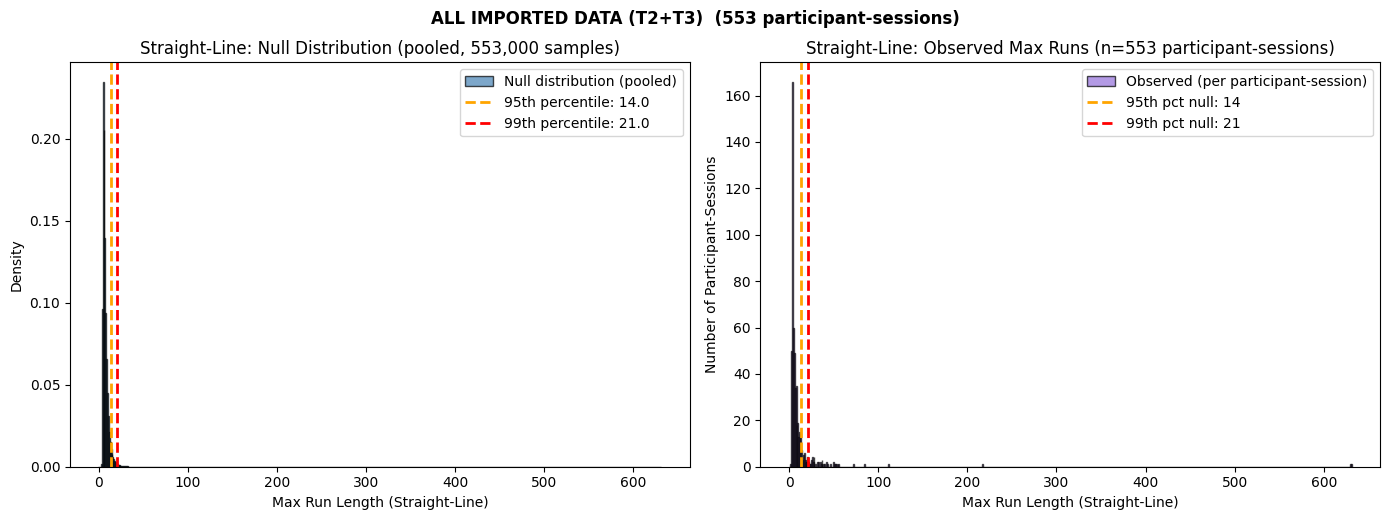

STRAIGHT-LINE THRESHOLD ANALYSIS
Null distribution (pooled from 272 participant-sessions x permutations):
  Mean max run by chance: 7.1
  Median max run by chance: 6.0
  Max observed in null: 95
----------------------------------------------------------------------
Null percentile markers (pooled over these participant-sessions):
  95th percentile: 12 (42 participant-sessions exceed, 15.4%)
  99th percentile: 20 (18 participant-sessions exceed, 6.6%)
----------------------------------------------------------------------
Observed data:
  Global max run: 630
  Mean max run per participant-session: 10.6
  Median max run per participant-session: 5.0
----------------------------------------------------------------------
Per-participant analysis (observed vs own null):
  Participants exceeding their own 95th pct null: 47 (17.3%)
  Participants exceeding their own 99th pct null: 34 (12.5%)


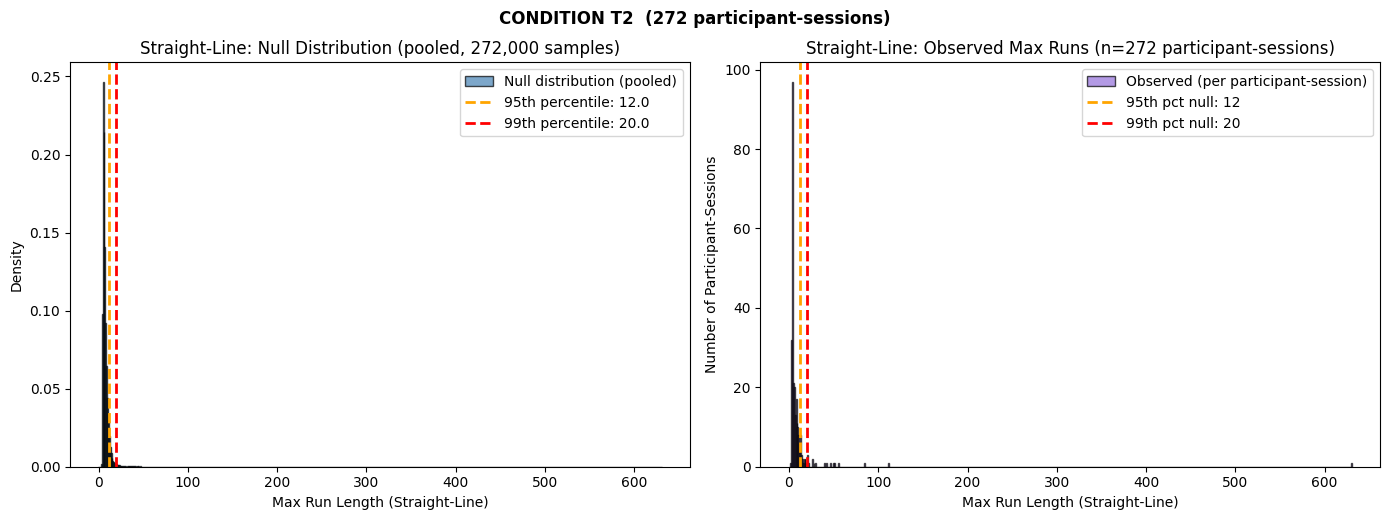

STRAIGHT-LINE THRESHOLD ANALYSIS
Null distribution (pooled from 281 participant-sessions x permutations):
  Mean max run by chance: 7.7
  Median max run by chance: 6.0
  Max observed in null: 225
----------------------------------------------------------------------
Null percentile markers (pooled over these participant-sessions):
  95th percentile: 15 (47 participant-sessions exceed, 16.7%)
  99th percentile: 23 (32 participant-sessions exceed, 11.4%)
----------------------------------------------------------------------
Observed data:
  Global max run: 631
  Mean max run per participant-session: 12.9
  Median max run per participant-session: 6.0
----------------------------------------------------------------------
Per-participant analysis (observed vs own null):
  Participants exceeding their own 95th pct null: 64 (22.8%)
  Participants exceeding their own 99th pct null: 55 (19.6%)


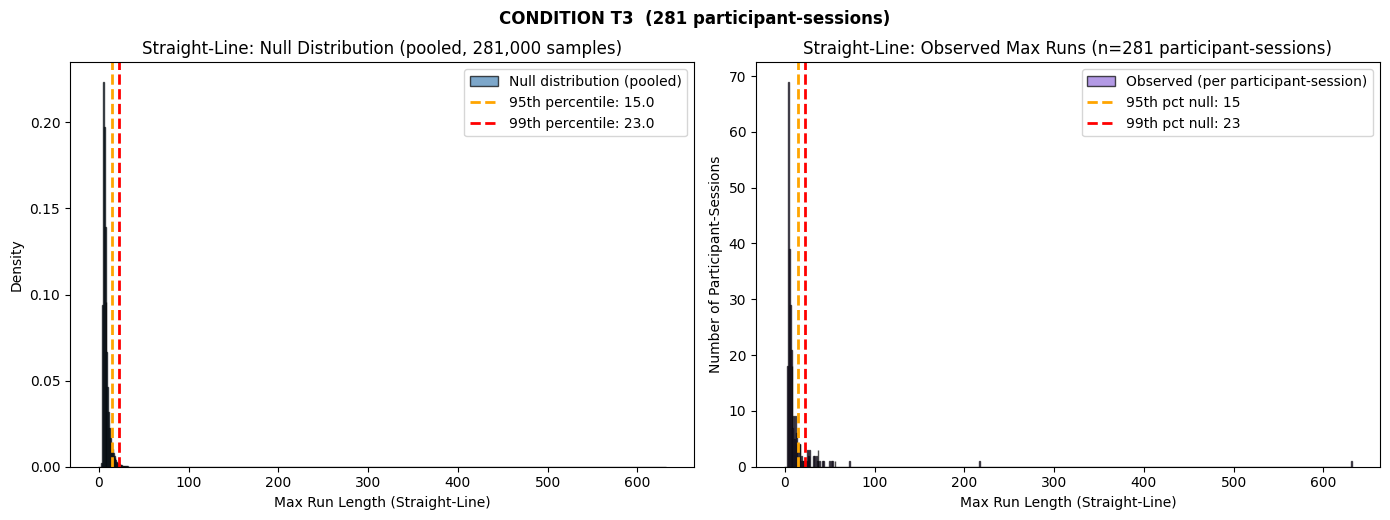

STRAIGHT-LINE DETECTION SUMMARY
Definition: Same response for 20+ consecutive trials
----------------------------------------------------------------------
Total participants: 282
Participants with straight-lining: 38 (13.5%)
Participants without straight-lining: 244 (86.5%)

Among participants WITH straight-lining:
  Mean trials flagged: 223.8
  Median trials flagged: 92
  Max trials flagged: 1235
  Mean % of trials: 12.1%
  Longest run: 631 consecutive trials


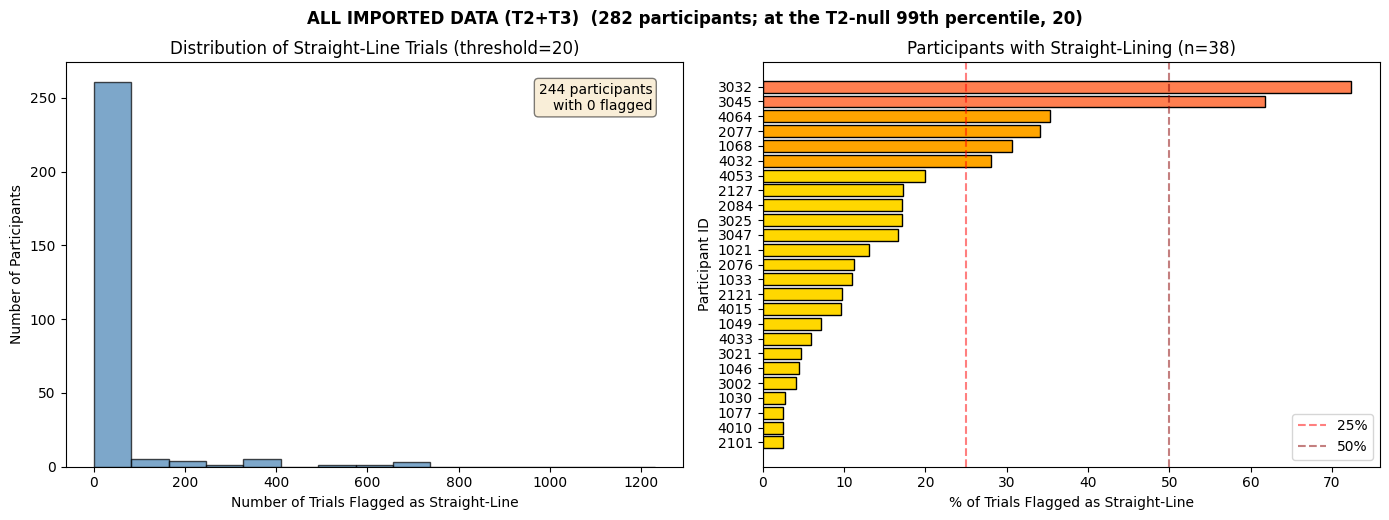

STRAIGHT-LINE DETECTION SUMMARY
Definition: Same response for 20+ consecutive trials
----------------------------------------------------------------------
Total participants: 139
Participants with straight-lining: 14 (10.1%)
Participants without straight-lining: 125 (89.9%)

Among participants WITH straight-lining:
  Mean trials flagged: 254.1
  Median trials flagged: 86
  Max trials flagged: 723
  Mean % of trials: 15.3%
  Longest run: 630 consecutive trials


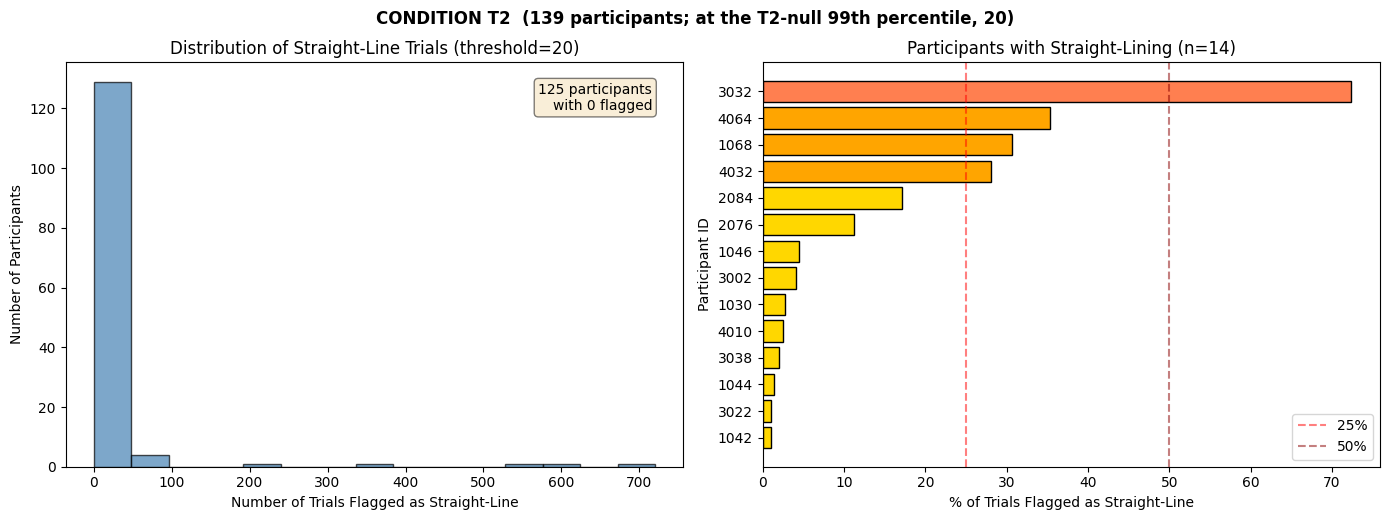

STRAIGHT-LINE DETECTION SUMMARY
Definition: Same response for 20+ consecutive trials
----------------------------------------------------------------------
Total participants: 143
Participants with straight-lining: 24 (16.8%)
Participants without straight-lining: 119 (83.2%)

Among participants WITH straight-lining:
  Mean trials flagged: 206.1
  Median trials flagged: 106
  Max trials flagged: 1235
  Mean % of trials: 10.3%
  Longest run: 631 consecutive trials


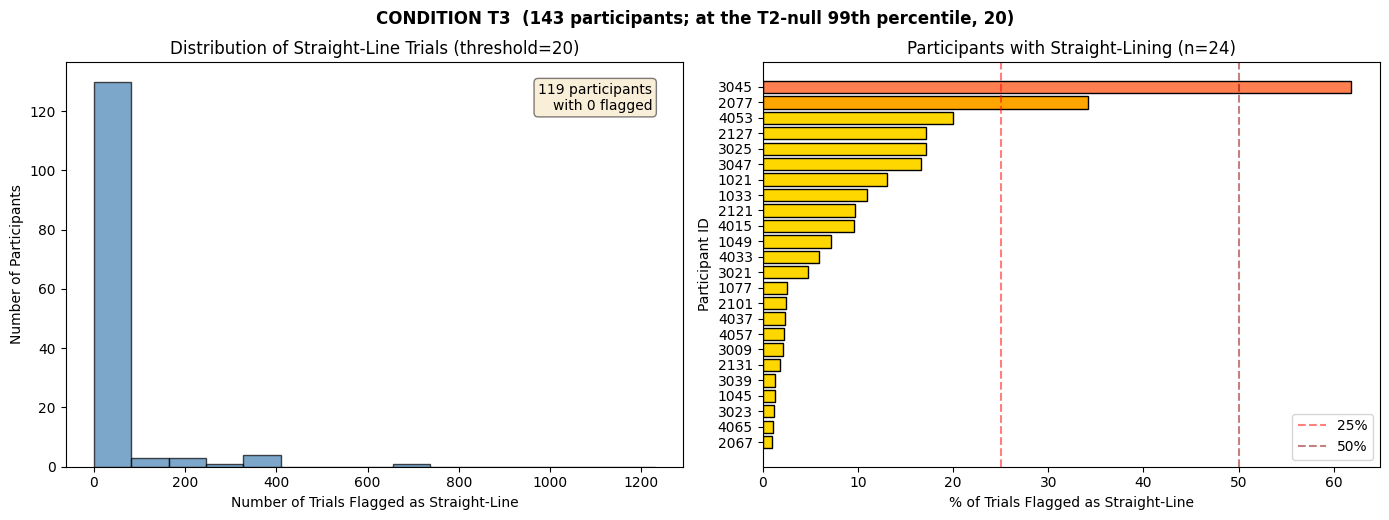

PERIODIC P=2 THRESHOLD ANALYSIS
Null distribution (pooled from 553 participant-sessions x permutations):
  Mean max run by chance: 5.9
  Median max run by chance: 6.0
  Max observed in null: 18
----------------------------------------------------------------------
Null percentile markers (pooled over these participant-sessions):
  95th percentile: 8 (19 participant-sessions exceed, 3.4%)
  99th percentile: 9 (15 participant-sessions exceed, 2.7%)
----------------------------------------------------------------------
Observed data:
  Global max run: 21
  Mean max run per participant-session: 5.2
  Median max run per participant-session: 5.0
----------------------------------------------------------------------
Per-participant analysis (observed vs own null):
  Participants exceeding their own 95th pct null: 16 (2.9%)
  Participants exceeding their own 99th pct null: 13 (2.4%)


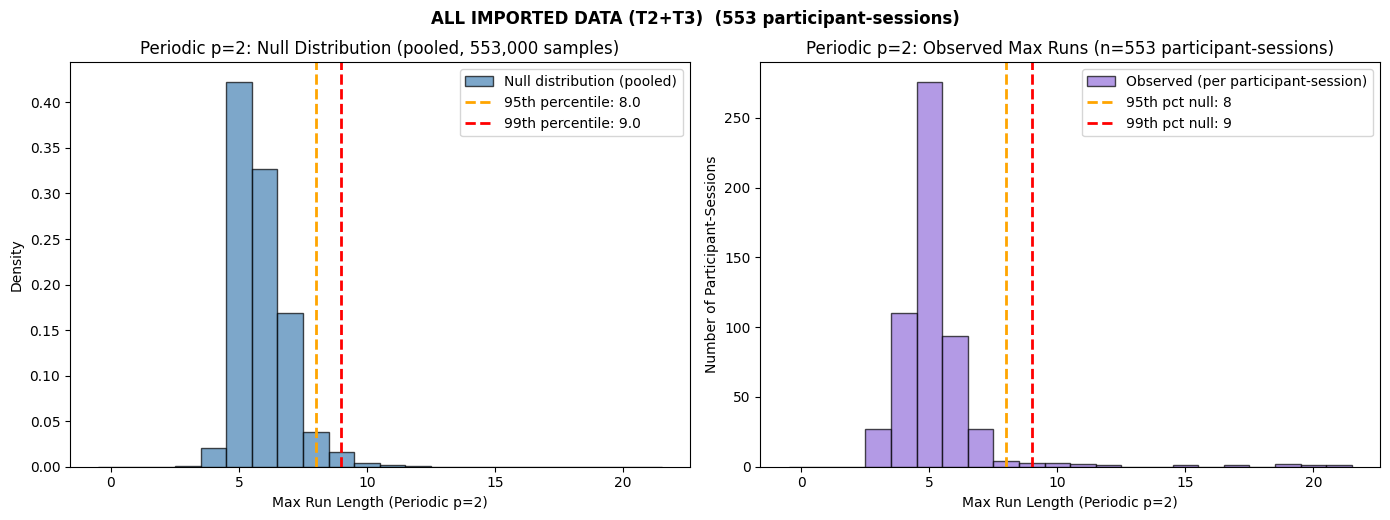

PERIODIC P=2 THRESHOLD ANALYSIS
Null distribution (pooled from 272 participant-sessions x permutations):
  Mean max run by chance: 5.9
  Median max run by chance: 6.0
  Max observed in null: 16
----------------------------------------------------------------------
Null percentile markers (pooled over these participant-sessions):
  95th percentile: 8 (9 participant-sessions exceed, 3.3%)
  99th percentile: 9 (6 participant-sessions exceed, 2.2%)
----------------------------------------------------------------------
Observed data:
  Global max run: 21
  Mean max run per participant-session: 5.2
  Median max run per participant-session: 5.0
----------------------------------------------------------------------
Per-participant analysis (observed vs own null):
  Participants exceeding their own 95th pct null: 7 (2.6%)
  Participants exceeding their own 99th pct null: 5 (1.8%)


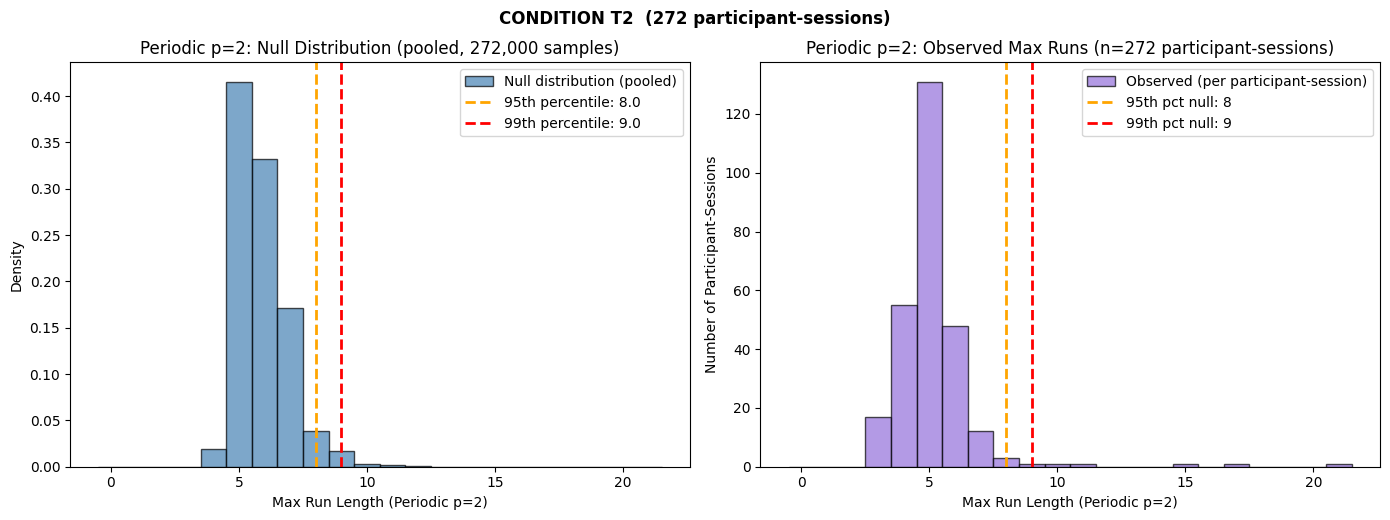

PERIODIC P=2 THRESHOLD ANALYSIS
Null distribution (pooled from 281 participant-sessions x permutations):
  Mean max run by chance: 5.8
  Median max run by chance: 6.0
  Max observed in null: 18
----------------------------------------------------------------------
Null percentile markers (pooled over these participant-sessions):
  95th percentile: 8 (10 participant-sessions exceed, 3.6%)
  99th percentile: 9 (9 participant-sessions exceed, 3.2%)
----------------------------------------------------------------------
Observed data:
  Global max run: 20
  Mean max run per participant-session: 5.3
  Median max run per participant-session: 5.0
----------------------------------------------------------------------
Per-participant analysis (observed vs own null):
  Participants exceeding their own 95th pct null: 9 (3.2%)
  Participants exceeding their own 99th pct null: 8 (2.8%)


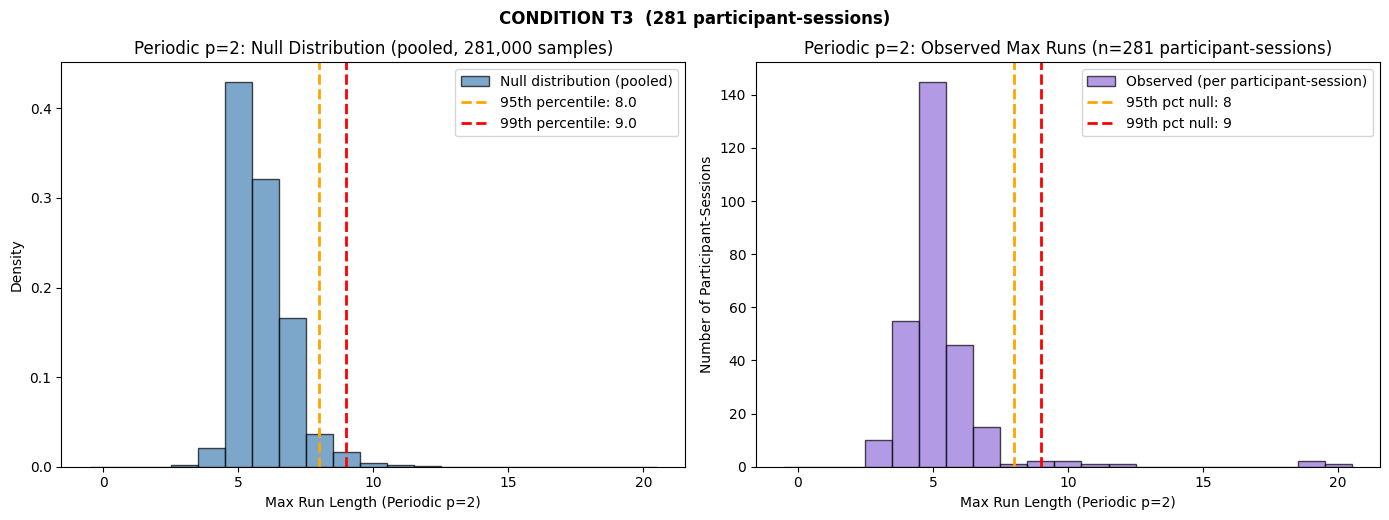

PERIODIC P=3 THRESHOLD ANALYSIS
Null distribution (pooled from 553 participant-sessions x permutations):
  Mean max run by chance: 7.2
  Median max run by chance: 7.0
  Max observed in null: 21
----------------------------------------------------------------------
Null percentile markers (pooled over these participant-sessions):
  95th percentile: 9 (19 participant-sessions exceed, 3.4%)
  99th percentile: 11 (7 participant-sessions exceed, 1.3%)
----------------------------------------------------------------------
Observed data:
  Global max run: 19
  Mean max run per participant-session: 6.3
  Median max run per participant-session: 6.0
----------------------------------------------------------------------
Per-participant analysis (observed vs own null):
  Participants exceeding their own 95th pct null: 12 (2.2%)
  Participants exceeding their own 99th pct null: 8 (1.4%)


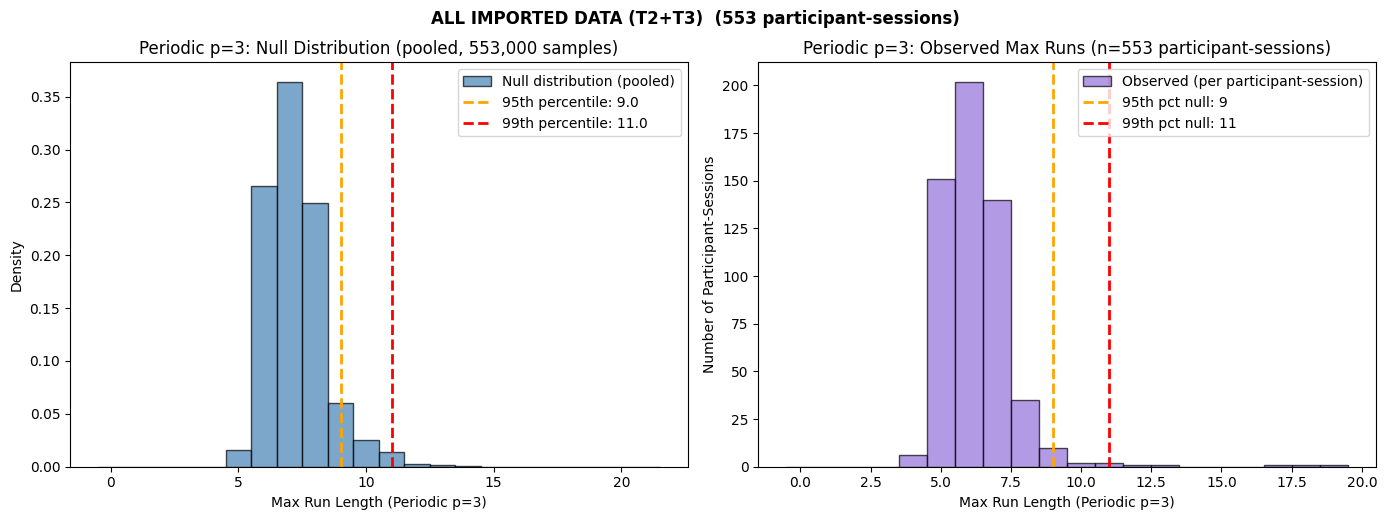

PERIODIC P=3 THRESHOLD ANALYSIS
Null distribution (pooled from 272 participant-sessions x permutations):
  Mean max run by chance: 7.2
  Median max run by chance: 7.0
  Max observed in null: 21
----------------------------------------------------------------------
Null percentile markers (pooled over these participant-sessions):
  95th percentile: 9 (5 participant-sessions exceed, 1.8%)
  99th percentile: 11 (2 participant-sessions exceed, 0.7%)
----------------------------------------------------------------------
Observed data:
  Global max run: 18
  Mean max run per participant-session: 6.2
  Median max run per participant-session: 6.0
----------------------------------------------------------------------
Per-participant analysis (observed vs own null):
  Participants exceeding their own 95th pct null: 4 (1.5%)
  Participants exceeding their own 99th pct null: 3 (1.1%)


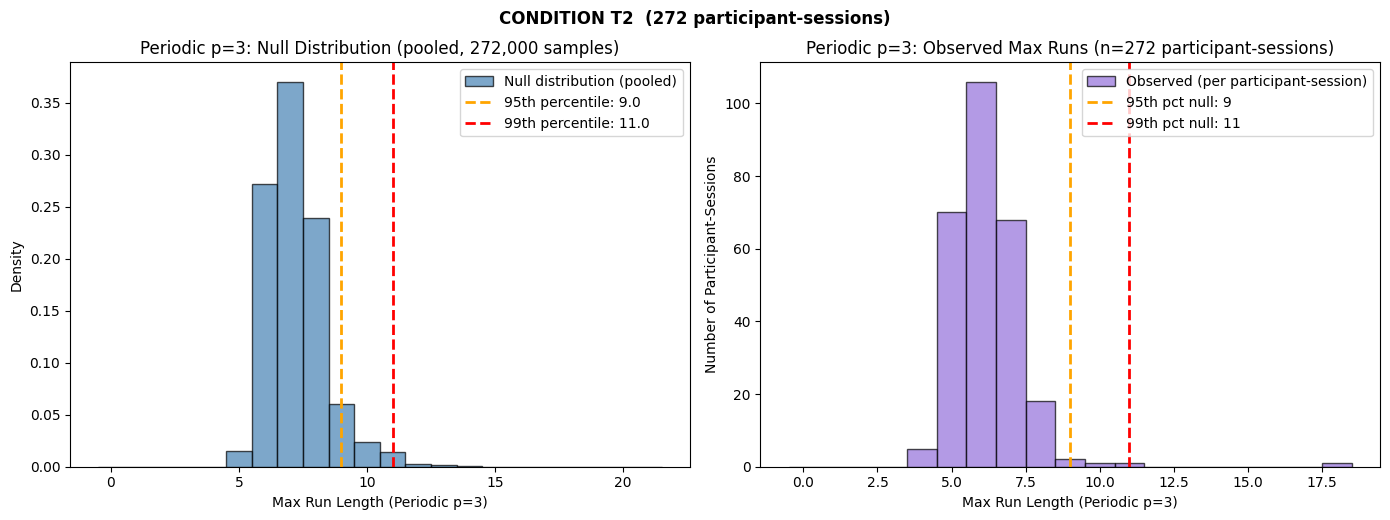

PERIODIC P=3 THRESHOLD ANALYSIS
Null distribution (pooled from 281 participant-sessions x permutations):
  Mean max run by chance: 7.3
  Median max run by chance: 7.0
  Max observed in null: 21
----------------------------------------------------------------------
Null percentile markers (pooled over these participant-sessions):
  95th percentile: 9 (14 participant-sessions exceed, 5.0%)
  99th percentile: 11 (5 participant-sessions exceed, 1.8%)
----------------------------------------------------------------------
Observed data:
  Global max run: 19
  Mean max run per participant-session: 6.3
  Median max run per participant-session: 6.0
----------------------------------------------------------------------
Per-participant analysis (observed vs own null):
  Participants exceeding their own 95th pct null: 8 (2.8%)
  Participants exceeding their own 99th pct null: 5 (1.8%)


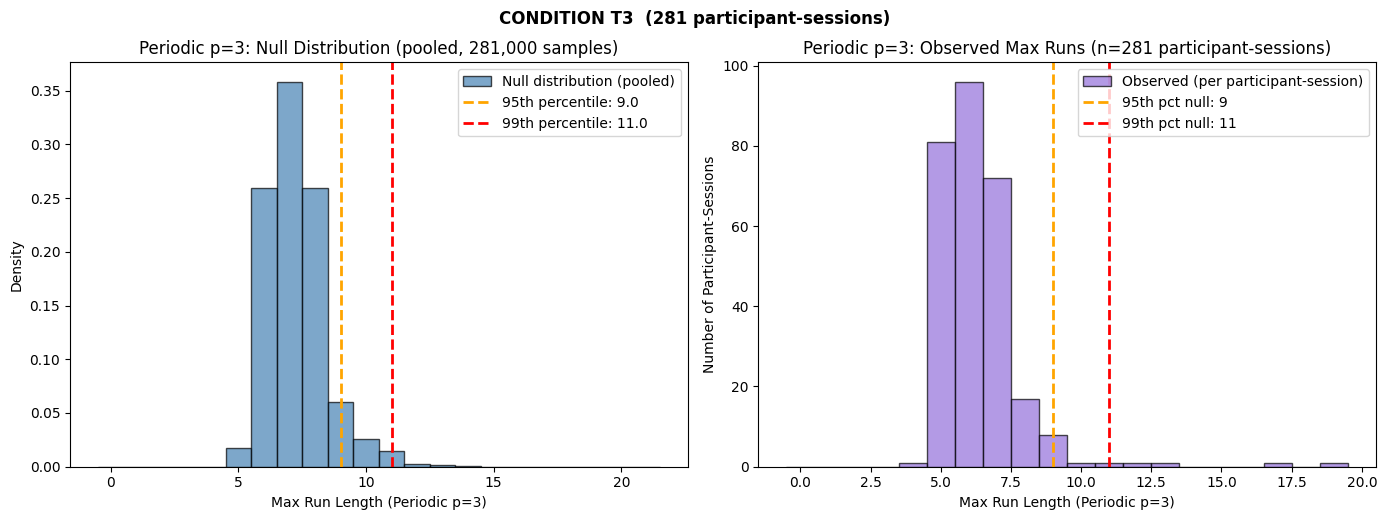

PERIODIC P=4 THRESHOLD ANALYSIS
Null distribution (pooled from 553 participant-sessions x permutations):
  Mean max run by chance: 8.3
  Median max run by chance: 8.0
  Max observed in null: 34
----------------------------------------------------------------------
Null percentile markers (pooled over these participant-sessions):
  95th percentile: 11 (36 participant-sessions exceed, 6.5%)
  99th percentile: 13 (3 participant-sessions exceed, 0.5%)
----------------------------------------------------------------------
Observed data:
  Global max run: 18
  Mean max run per participant-session: 8.0
  Median max run per participant-session: 8.0
----------------------------------------------------------------------
Per-participant analysis (observed vs own null):
  Participants exceeding their own 95th pct null: 17 (3.1%)
  Participants exceeding their own 99th pct null: 8 (1.4%)


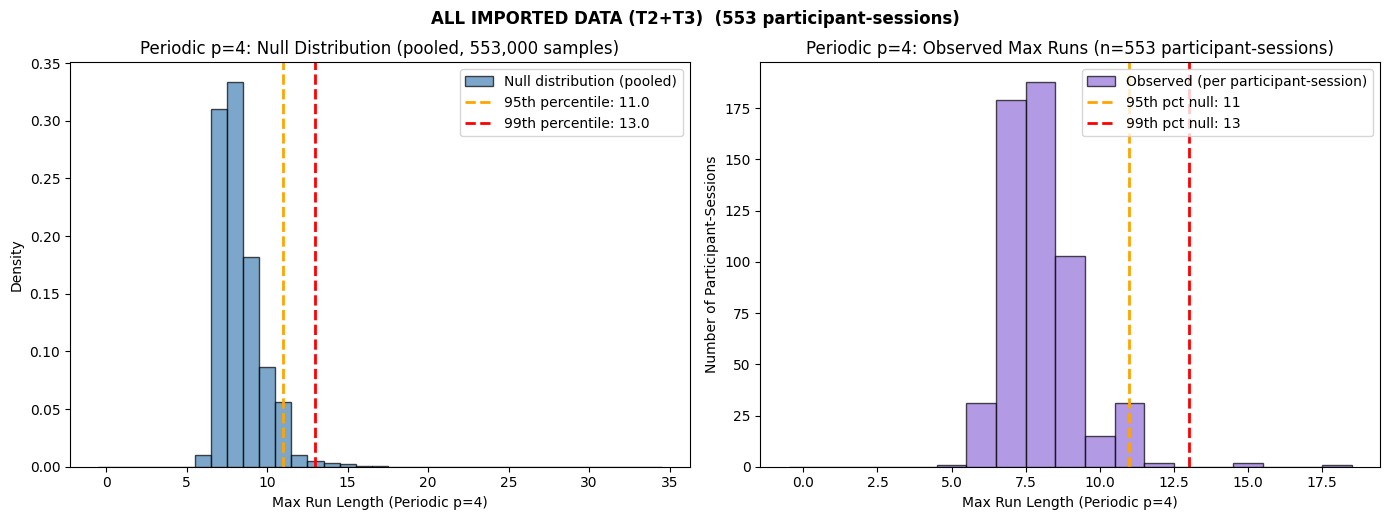

PERIODIC P=4 THRESHOLD ANALYSIS
Null distribution (pooled from 272 participant-sessions x permutations):
  Mean max run by chance: 8.3
  Median max run by chance: 8.0
  Max observed in null: 34
----------------------------------------------------------------------
Null percentile markers (pooled over these participant-sessions):
  95th percentile: 11 (17 participant-sessions exceed, 6.2%)
  99th percentile: 13 (1 participant-sessions exceed, 0.4%)
----------------------------------------------------------------------
Observed data:
  Global max run: 15
  Mean max run per participant-session: 7.9
  Median max run per participant-session: 8.0
----------------------------------------------------------------------
Per-participant analysis (observed vs own null):
  Participants exceeding their own 95th pct null: 6 (2.2%)
  Participants exceeding their own 99th pct null: 1 (0.4%)


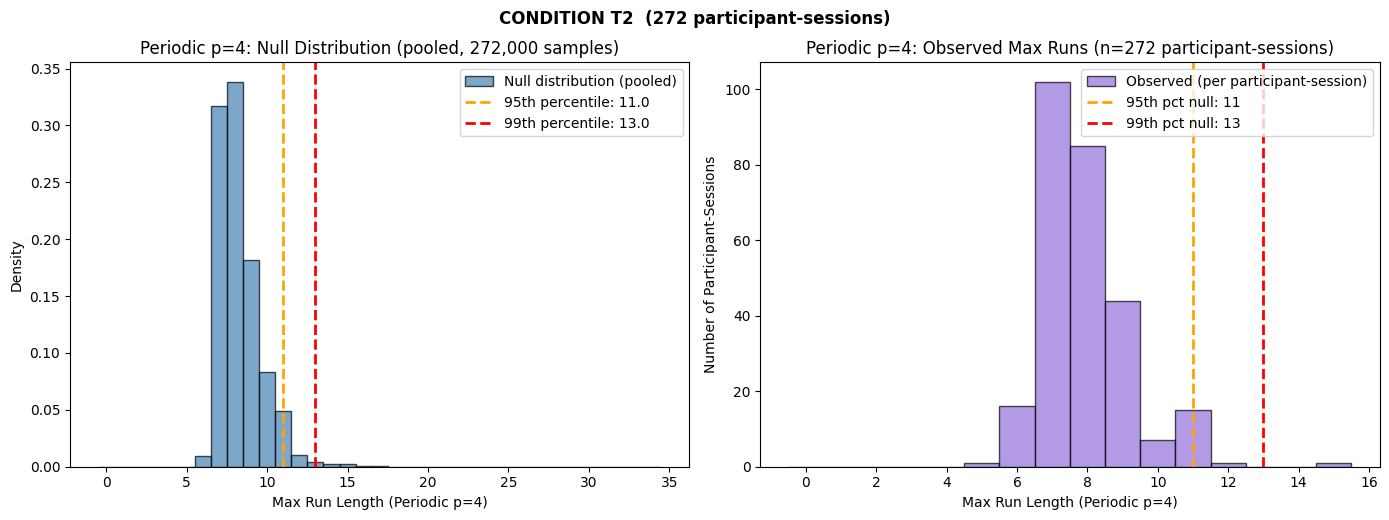

PERIODIC P=4 THRESHOLD ANALYSIS
Null distribution (pooled from 281 participant-sessions x permutations):
  Mean max run by chance: 8.3
  Median max run by chance: 8.0
  Max observed in null: 24
----------------------------------------------------------------------
Null percentile markers (pooled over these participant-sessions):
  95th percentile: 11 (19 participant-sessions exceed, 6.8%)
  99th percentile: 13 (2 participant-sessions exceed, 0.7%)
----------------------------------------------------------------------
Observed data:
  Global max run: 18
  Mean max run per participant-session: 8.1
  Median max run per participant-session: 8.0
----------------------------------------------------------------------
Per-participant analysis (observed vs own null):
  Participants exceeding their own 95th pct null: 11 (3.9%)
  Participants exceeding their own 99th pct null: 7 (2.5%)


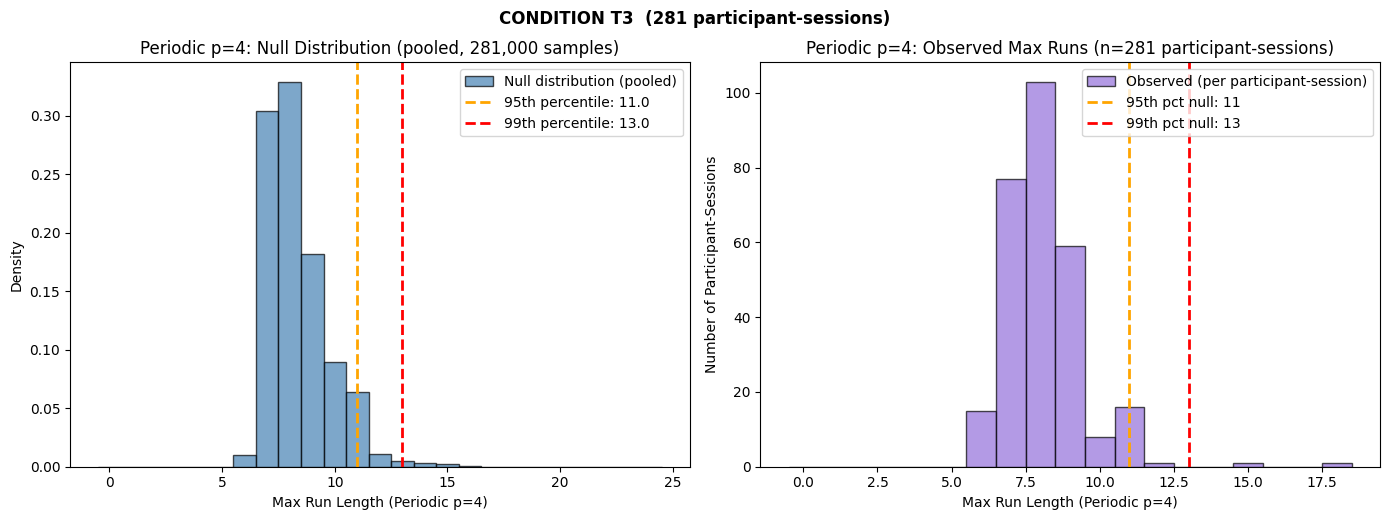

5-RESPONSE STIMULUS-LINKED PATTERN THRESHOLD ANALYSIS
Null distribution (pooled from 553 participant-sessions x permutations):
  Mean max run by chance: 1.8
  Median max run by chance: 2.0
  Max observed in null: 84
----------------------------------------------------------------------
Null percentile markers (pooled over these participant-sessions):
  95th percentile: 4 (188 participant-sessions exceed, 34.0%)
  99th percentile: 8 (60 participant-sessions exceed, 10.8%)
----------------------------------------------------------------------
Observed data:
  Global max run: 126
  Mean max run per participant-session: 4.7
  Median max run per participant-session: 3.0
----------------------------------------------------------------------
Per-participant analysis (observed vs own null):
  Participants exceeding their own 95th pct null: 262 (47.4%)
  Participants exceeding their own 99th pct null: 219 (39.6%)


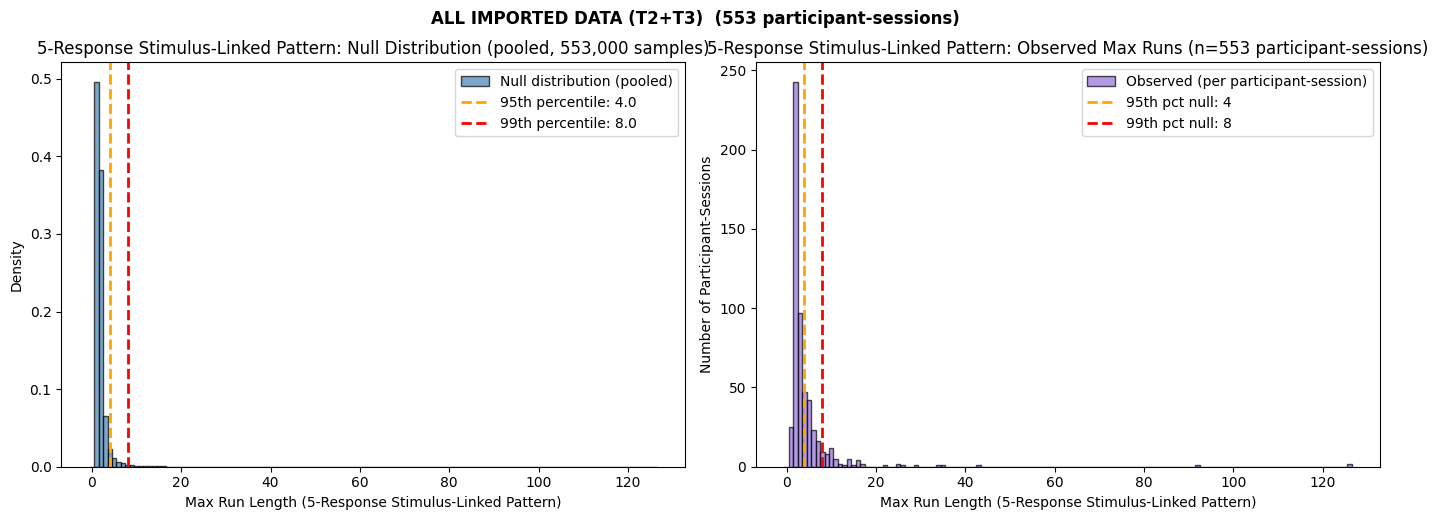

5-RESPONSE STIMULUS-LINKED PATTERN THRESHOLD ANALYSIS
Null distribution (pooled from 272 participant-sessions x permutations):
  Mean max run by chance: 1.9
  Median max run by chance: 2.0
  Max observed in null: 84
----------------------------------------------------------------------
Null percentile markers (pooled over these participant-sessions):
  95th percentile: 4 (86 participant-sessions exceed, 31.6%)
  99th percentile: 9 (28 participant-sessions exceed, 10.3%)
----------------------------------------------------------------------
Observed data:
  Global max run: 126
  Mean max run per participant-session: 4.9
  Median max run per participant-session: 3.0
----------------------------------------------------------------------
Per-participant analysis (observed vs own null):
  Participants exceeding their own 95th pct null: 124 (45.6%)
  Participants exceeding their own 99th pct null: 105 (38.6%)


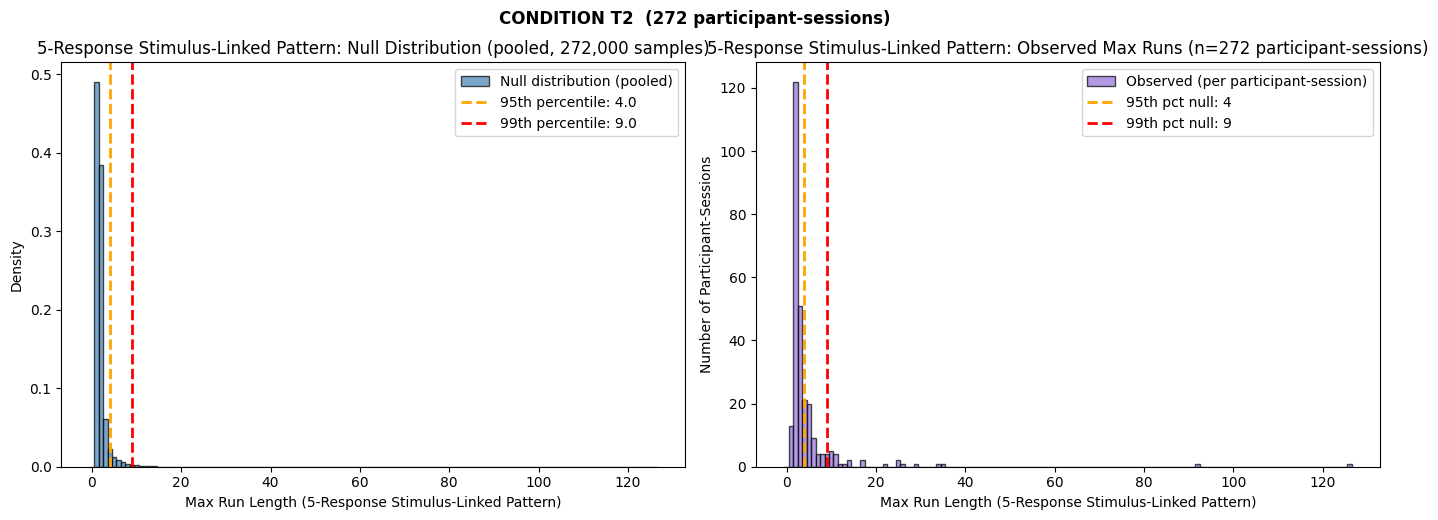

5-RESPONSE STIMULUS-LINKED PATTERN THRESHOLD ANALYSIS
Null distribution (pooled from 281 participant-sessions x permutations):
  Mean max run by chance: 1.8
  Median max run by chance: 1.0
  Max observed in null: 50
----------------------------------------------------------------------
Null percentile markers (pooled over these participant-sessions):
  95th percentile: 3 (148 participant-sessions exceed, 52.7%)
  99th percentile: 6 (54 participant-sessions exceed, 19.2%)
----------------------------------------------------------------------
Observed data:
  Global max run: 126
  Mean max run per participant-session: 4.4
  Median max run per participant-session: 3.0
----------------------------------------------------------------------
Per-participant analysis (observed vs own null):
  Participants exceeding their own 95th pct null: 138 (49.1%)
  Participants exceeding their own 99th pct null: 114 (40.6%)


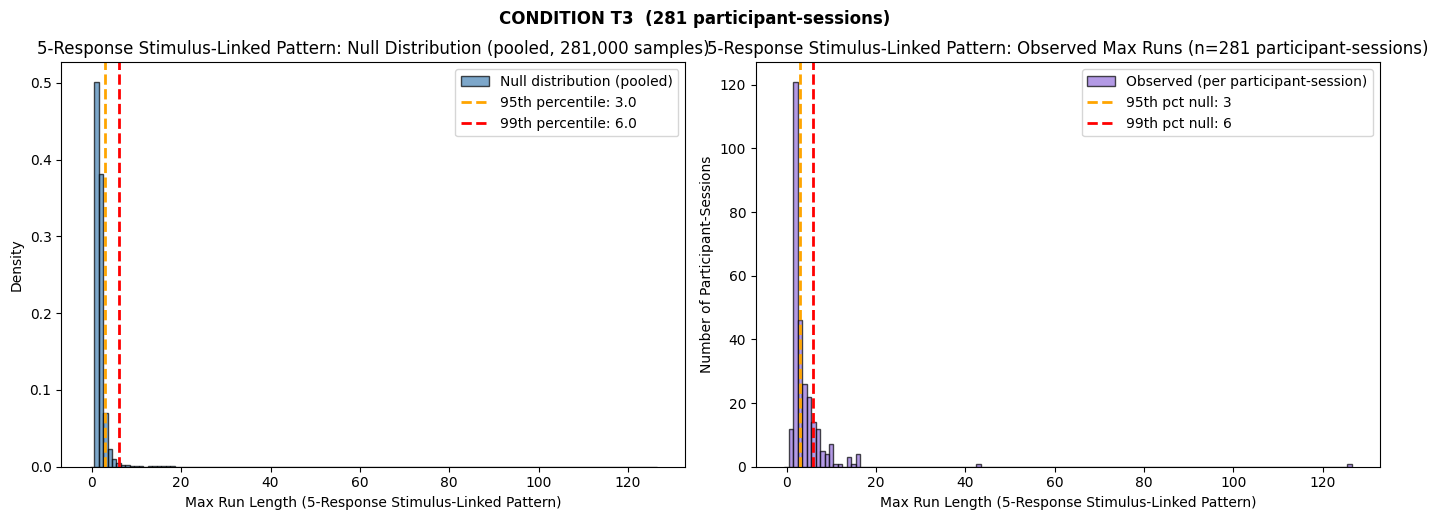

INATTENTIVE PATTERN DETECTION SUMMARY
Definition: Same response to 9+ consecutive stimuli (within scale)
Note: Straight-line responses are excluded before detection
----------------------------------------------------------------------
Total participants: 282
Participants with 5-response stimulus-linked patterns: 25 (8.9%)
Participants without 5-response stimulus-linked patterns: 257 (91.1%)

Among participants WITH 5-response stimulus-linked patterns:
  Mean trials flagged: 239.6
  Median trials flagged: 105
  Max trials flagged: 840
  Mean % of trials: 13.8%
  Longest run: 92 consecutive stimuli


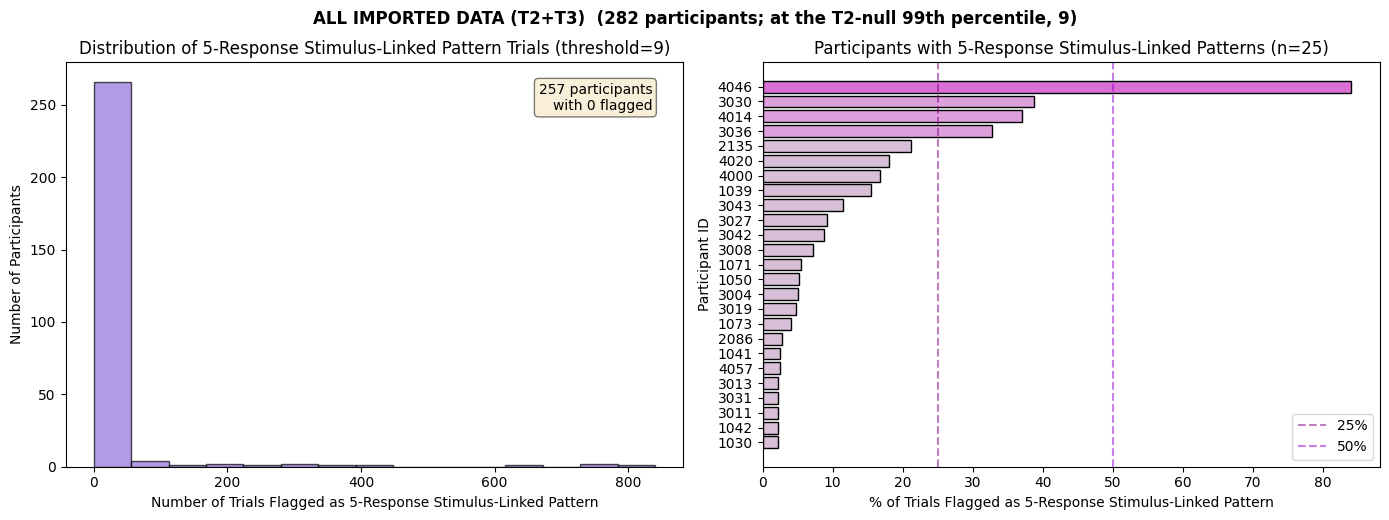

INATTENTIVE PATTERN DETECTION SUMMARY
Definition: Same response to 9+ consecutive stimuli (within scale)
Note: Straight-line responses are excluded before detection
----------------------------------------------------------------------
Total participants: 139
Participants with 5-response stimulus-linked patterns: 13 (9.4%)
Participants without 5-response stimulus-linked patterns: 126 (90.6%)

Among participants WITH 5-response stimulus-linked patterns:
  Mean trials flagged: 336.5
  Median trials flagged: 175
  Max trials flagged: 840
  Mean % of trials: 20.1%
  Longest run: 92 consecutive stimuli


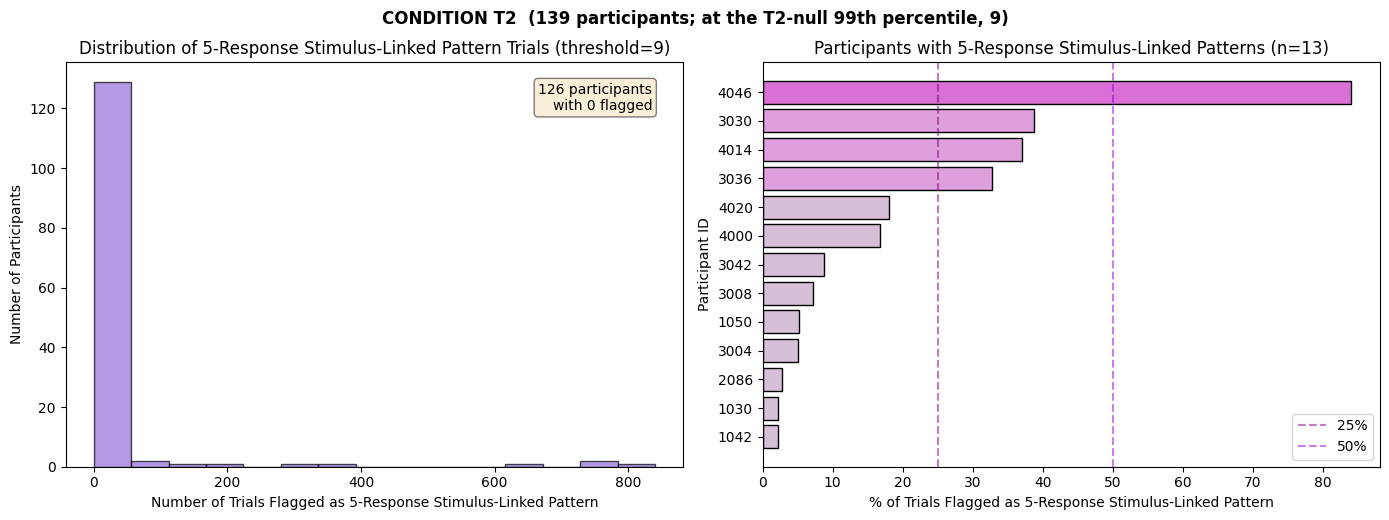

INATTENTIVE PATTERN DETECTION SUMMARY
Definition: Same response to 9+ consecutive stimuli (within scale)
Note: Straight-line responses are excluded before detection
----------------------------------------------------------------------
Total participants: 143
Participants with 5-response stimulus-linked patterns: 12 (8.4%)
Participants without 5-response stimulus-linked patterns: 131 (91.6%)

Among participants WITH 5-response stimulus-linked patterns:
  Mean trials flagged: 134.6
  Median trials flagged: 68
  Max trials flagged: 425
  Mean % of trials: 7.0%
  Longest run: 16 consecutive stimuli


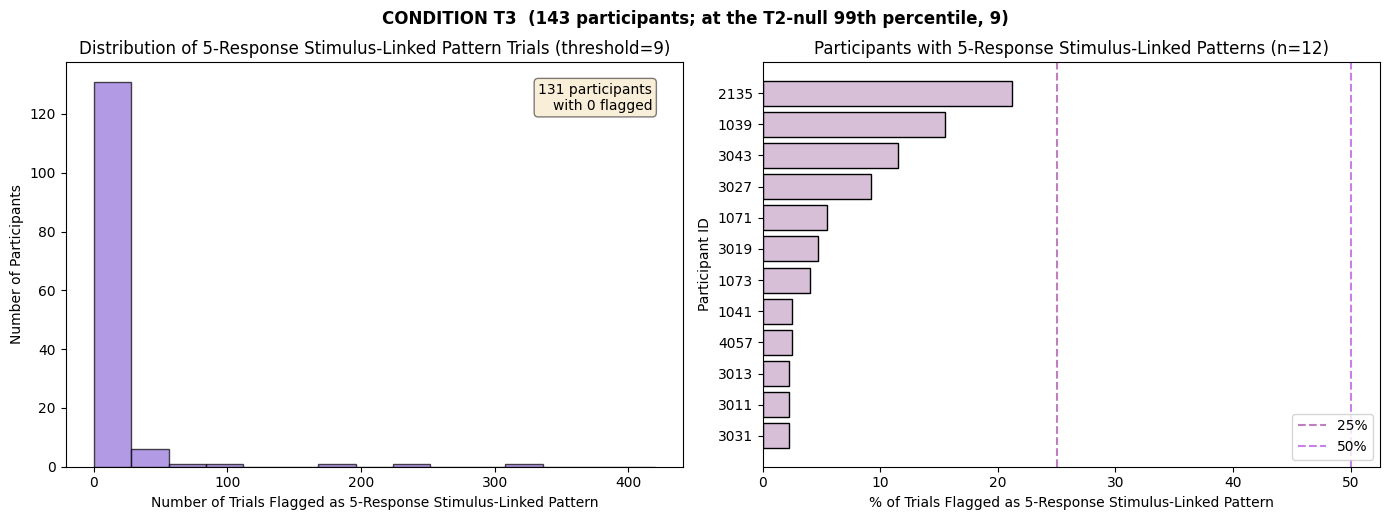

In [10]:
# [notebook only] LVL_0 REPORTING: QC FIGURES BY CONDITION
# =============================================================================
# The LVL_0 response-pattern diagnostics, each drawn for ALL IMPORTED DATA (the [cell 5]
# figure, i.e. every condition in LVL_0_CONFIG["conditions"]) and then once per condition.
# It needs LVL0_QC, kept by [cell 5].
# A condition's null-vs-observed figure uses only that condition's participant-sessions
# (null draws and observed maxima are subset BEFORE the percentiles are computed), so its
# 95th / 99th markers are that condition's columns of the marker table. The flagged-trial
# histograms are drawn at the CALIBRATION_CONDITION 99th-percentile markers in every panel
# (display only). Nothing is recomputed: the per-session nulls come from [cell 5].
_qc = LVL0_QC["data"]
_sess_cond = LVL0_QC["sess_cond"]
_qc_all = "+".join(sorted(set(_sess_cond.values())))

print(f"PERMUTATION-NULL MARKERS ([cell 5]); the {CALIBRATION_CONDITION} columns are the calibration "
      "values for LVL_2_CONFIG's inattent_behav_*_thresh:")
display(LVL0_QC["markers"])

def _qc_subsets():
    yield None, f"ALL IMPORTED DATA ({_qc_all})"
    for _cd in LVL_0_CONFIG["conditions"]:
        if _cd not in set(_sess_cond.values()):
            print(f"[skip] condition {_cd!r} is not in the LVL_0 data (LVL_0_CONFIG['conditions'])")
            continue
        yield _cd, f"CONDITION {_cd}"

def _keys(dct, cond):
    return {k: v for k, v in dct.items() if cond is None or _sess_cond.get(k) == cond}

def _qc_threshold_figs(name):
    null, observed = LVL0_QC["nulls"][name]
    for cond, label in _qc_subsets():
        n_k, o_k = _keys(null, cond), _keys(observed, cond)
        fig, _ = plot_threshold_analysis(n_k, o_k, detection_type=name, percentiles=[95, 99])
        fig.suptitle(f"{label}  ({len(o_k)} participant-sessions)", fontweight="bold", y=1.03)
        plt.show()

def _qc_histogram_figs(plot_fn, thr_arg, thr_key):
    if _qc is None:
        print(f"no flagged-trial display: {CALIBRATION_CONDITION} is not in the LVL_0 data")
        return
    thr = LVL0_QC["display_thresh"][thr_key]
    for cond, label in _qc_subsets():
        d = _qc if cond is None else _qc[_qc["condition"] == cond]
        fig = plot_fn(d, **{thr_arg: thr}, top_n=LVL_0_CONFIG["sub_n_plots"])
        fig.suptitle(f"{label}  ({d['id'].nunique()} participants; at the {CALIBRATION_CONDITION}-null "
                     f"99th percentile, {thr})", fontweight="bold", y=1.03)
        plt.show()

_qc_threshold_figs("Straight-Line")
_qc_histogram_figs(plot_straight_line_histogram, "sl_thresh", "sl")
for _p in PERIODIC_PERIODS:
    _qc_threshold_figs(f"Periodic p={_p}")
_qc_threshold_figs("5-Response Stimulus-Linked Pattern")
_qc_histogram_figs(plot_inattentive_pattern_histogram, "stim_ip_thresh", "ip")